# Ptaki Polski: rozpoznawanie gatunków i weryfikacja obserwacji

Projekt zaliczeniowy z przedmiotu Metody reprezentacji wiedzy.

Zespół: Osoba1, Osoba2, Osoba3, Osoba4.

Notebook wykonuje się w Google Colab od początku do końca (Środowisko wykonawcze, Uruchom wszystko) i nie wymaga wgrywania plików. Jedynym źródłem zewnętrznym jest usługa zapytań Wikidata. Gdy nie odpowiada, notebook korzysta z kopii wyników zapisanej 21.11.2026.

In [1]:
%pip install -q --disable-pip-version-check rdflib owlrl owlready2 pgmpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import re
import time
import shutil
import logging
import warnings
import itertools
import subprocess
from collections import defaultdict, Counter, namedtuple

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import networkx as nx

import rdflib
from rdflib import Graph, Namespace, Literal, URIRef, BNode, RDF, RDFS, OWL, XSD
from rdflib.collection import Collection
from rdflib.namespace import SKOS
import owlrl
import owlready2
import pgmpy
import sklearn
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
try:
    from pgmpy.models import DiscreteBayesianNetwork as SiecBayesowska
except ImportError:
    from pgmpy.models import BayesianNetwork as SiecBayesowska
from sklearn.ensemble import RandomForestClassifier

logging.getLogger("pgmpy").setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)
RANDOM_STATE = 42
T_START = time.time()

for nazwa, modul in [("rdflib", rdflib), ("owlrl", owlrl), ("owlready2", owlready2), ("pgmpy", pgmpy),
                     ("scikit-learn", sklearn), ("pandas", pd), ("numpy", np), ("networkx", nx)]:
    print(f"{nazwa:13s}", getattr(modul, "__version__", getattr(modul, "VERSION", "?")))

rdflib        7.6.0
owlrl         7.6.2
owlready2     0.51
pgmpy         1.1.2
scikit-learn  1.9.1
pandas        3.1.1
numpy         2.5.4
networkx      3.7


## 1. Zespół, dziedzina, cel systemu

Dziedziną są ptaki spotykane w Polsce i obserwacje zgłaszane do regionalnej bazy przez obserwatorów amatorów. System ma trzy zadania.

Pierwsze to odpowiadanie na pytania o gatunki: przynależność systematyczna, siedliska, pokarm, obecność w Polsce w różnych porach roku i kategoria zagrożenia według IUCN. Drugie to pomoc w rozpoznaniu ptaka na podstawie krótkiego opisu (wielkość, barwy, siedlisko, pora roku), jakiego udziela początkujący obserwator. Trzecie to wstępna weryfikacja zgłoszeń przed ich publikacją: system wskazuje zgłoszenia nietypowe, które powinien obejrzeć ekspert, oraz zgłoszenia, w których trzeba ukryć dokładne miejsce, bo dotyczą lęgów gatunku wrażliwego na niepokojenie.

Zakres zawęziliśmy do 58 gatunków (pospolitych, kilku rzadkich i kilku gości zimowych) i fikcyjnego obszaru badań o wymiarach 20 na 20 km, podzielonego na kwadraty o boku 1 km. Obserwatorzy występują pod pseudonimami, a wszystkie obserwacje są syntetyczne. Świadomie nie modelujemy podgatunków, szat godowych i młodocianych (poza jednym uproszczeniem w sekcji 10), głosów, liczebności populacji ani przepisów o ochronie gatunkowej poza listą gatunków, dla których wyznacza się strefy ochrony.

Każda część wiedzy trafiła do formalizmu, który do niej pasuje. Systematyka i definicje pojęć (ptak drapieżny, gatunek obecny zimą, obserwacja lęgowa) są wiedzą trwałą, która nie zależy od kompletności danych, więc zapisujemy je w OWL. Weryfikacja zgłoszeń opiera się na braku informacji ("nikt inny tego nie potwierdził", "obserwator nie ma historii zgłoszeń"), czyli na założeniu świata zamkniętego, którego OWL nie wyraża. Tę część realizujemy regułami z negacją. Rozpoznawanie gatunku z opisu jest wnioskowaniem w warunkach niepewności, bo obserwatorzy mylą się co do wielkości i barw, dlatego używamy sieci bayesowskiej, której tabele budujemy z faktów zapisanych w grafie.

## 2. Pytania kompetencyjne

Pytania dzielimy na bezpośrednie (odpowiedź zapisana w danych), wymagające wnioskowania, integracyjne (wymagają Wikidata) i nieobsługiwane. Dwa ostatnie pytania zostawiamy celowo jako przykład granic przyjętej reprezentacji.

In [3]:
CQ = pd.DataFrame([
    ("CQ1", "Do jakiej rodziny należy kowalik?", "bezpośrednie", "SPARQL"),
    ("CQ2", "Ile gatunków z rodziny krukowatych (Corvidae) jest w bazie?", "bezpośrednie", "SPARQL, agregacja"),
    ("CQ3", "Które gatunki występują na mokradłach?", "bezpośrednie", "SPARQL"),
    ("CQ4", "Do jakiego rzędu należy bielik?", "wnioskowanie", "OWL: łańcuch właściwości gatunek, rodzina, rząd"),
    ("CQ5", "Które gatunki są ptakami drapieżnymi (szponiaste, sokołowe, sowy)?", "wnioskowanie", "OWL: łańcuch i klasa definiowana"),
    ("CQ6", "Ile gatunków z bazy można spotkać w Polsce zimą?", "wnioskowanie", "OWL: klasa definiowana przez status pobytu"),
    ("CQ7", "Które gatunki są związane z wodą lub mokradłami?", "wnioskowanie", "OWL: klasa definiowana przez siedliska"),
    ("CQ8", "Które gatunki polują na kręgowce, choć nie są ptakami drapieżnymi?", "wnioskowanie", "OWL i SPARQL z FILTER NOT EXISTS"),
    ("CQ9", "W których obserwacjach trzeba ukryć dokładne miejsce, bo dotyczą lęgów gatunku wrażliwego?", "wnioskowanie", "OWL (obserwacja lęgowa, gatunek wrażliwy) i reguły"),
    ("CQ10", "Które obserwacje wymagają weryfikacji przez eksperta?", "wnioskowanie", "reguły z negacją nad grafem po wnioskowaniu"),
    ("CQ11", "Jaki gatunek najpewniej widział ktoś, kto opisał małego ptaka, czerwonego z czarnym, bez żółtego, zimą w mieście?", "wnioskowanie", "sieć bayesowska zasilana faktami z grafu"),
    ("CQ12", "Który obserwator zgłosił najwięcej różnych gatunków?", "wnioskowanie", "OWL: łańcuch z właściwością odwrotną, SPARQL z agregacją"),
    ("CQ13", "Dla których gatunków klasyfikacja w Wikidata (rodzina, rząd) jest niejednoznaczna albo inna niż nasza?", "integracja", "porównanie z Wikidata"),
    ("CQ14", "Które gatunki są globalnie zagrożone wyginięciem (VU, EN, CR)?", "wnioskowanie", "OWL: klasa definiowana"),
    ("CQ15", "Ile par bielika gniazduje obecnie w Polsce?", "nieobsługiwane", "brak danych o liczebności populacji"),
    ("CQ16", "Jak zmieniała się liczebność czajki w ostatnich dwudziestu latach?", "nieobsługiwane", "brak wymiaru czasu dla populacji"),
], columns=["id", "pytanie", "typ", "mechanizm"])
print(CQ["typ"].value_counts().to_string())
CQ

typ
wnioskowanie      10
bezpośrednie       3
nieobsługiwane     2
integracja         1


,id,pytanie,typ,mechanizm
0,CQ1,Do jakiej rodziny należy kowalik?,bezpośrednie,SPARQL
1,CQ2,Ile gatunków z rodziny krukowatych (Corvidae) jest w bazie?,bezpośrednie,"SPARQL, agregacja"
2,CQ3,Które gatunki występują na mokradłach?,bezpośrednie,SPARQL
3,CQ4,Do jakiego rzędu należy bielik?,wnioskowanie,"OWL: łańcuch właściwości gatunek, rodzina, rząd"
4,CQ5,"Które gatunki są ptakami drapieżnymi (szponiaste, sokołowe, sowy)?",wnioskowanie,OWL: łańcuch i klasa definiowana
5,CQ6,Ile gatunków z bazy można spotkać w Polsce zimą?,wnioskowanie,OWL: klasa definiowana przez status pobytu
6,CQ7,Które gatunki są związane z wodą lub mokradłami?,wnioskowanie,OWL: klasa definiowana przez siedliska
7,CQ8,"Które gatunki polują na kręgowce, choć nie są ptakami drapieżnymi?",wnioskowanie,OWL i SPARQL z FILTER NOT EXISTS
8,CQ9,"W których obserwacjach trzeba ukryć dokładne miejsce, bo dotyczą lęgów gatunku wrażliwego?",wnioskowanie,"OWL (obserwacja lęgowa, gatunek wrażliwy) i reguły"
9,CQ10,Które obserwacje wymagają weryfikacji przez eksperta?,wnioskowanie,reguły z negacją nad grafem po wnioskowaniu


## 3. Źródła danych i licencje

1. Wikidata (https://query.wikidata.org), licencja CC0. Pobieramy identyfikatory gatunków, polskie etykiety, rodzinę i rząd według taksonów nadrzędnych oraz kategorię IUCN (P141). Służą do połączenia naszych encji ze światem zewnętrznym i do sprawdzenia naszych danych. Kopia wyników z 21.11.2026 jest wbudowana w notebook.
2. Cechy gatunków (klasa wielkości, barwy widoczne w terenie, siedliska, pokarm, status pobytu) opracowaliśmy sami na podstawie terenowych przewodników do oznaczania ptaków i Listy awifauny krajowej Komisji Faunistycznej (status pobytu). To uproszczenie: każdy gatunek ma jeden status pobytu, a barwy opisują przede wszystkim dorosłego samca. Dane udostępniamy na licencji CC BY 4.0 i traktujemy jako ilustracyjne, a nie jako przewodnik.
3. Kategorie zagrożenia w naszej tabeli pochodzą z Czerwonej listy IUCN (oceny globalne). Przepisujemy wyłącznie kategorię, czyli fakt, a nie treść opracowań. W sekcji 5 porównujemy je z Wikidata.
4. Gatunki, dla których wyznacza się strefy ochrony miejsc rozrodu: rozporządzenie Ministra Środowiska z 16 grudnia 2016 r. w sprawie ochrony gatunkowej zwierząt (Dz.U. 2016 poz. 2183), wykaz stref ochrony. Z naszej listy są w nim bielik, orlik krzykliwy i głuszec. Sprawdziliśmy tekst ogłoszony w Dzienniku Ustaw, nie analizowaliśmy późniejszych zmian.
5. Obserwacje, obserwatorzy i obszar badań są syntetyczne. 44 obserwacje wpisaliśmy ręcznie tak, żeby obejmowały przypadki typowe i graniczne. Większe zbiory do oceny systemu (sekcje 10 i 11) generuje kod z ustalonym ziarnem. Notebook nie zawiera danych prawdziwych osób.

Błędna informacja o ptakach rzadko komuś szkodzi bezpośrednio, ale błędna decyzja o publikacji miejsca gniazda gatunku chronionego może zaszkodzić ptakom, a publikacja szczegółowych tras obserwatora może zaszkodzić jemu. Obie sprawy omawiamy w sekcji 11.

## 4. Ontologia

Przestrzeń nazw ontologii to `http://example.org/ptaki#` (prefiks `p:`). Najważniejsze decyzje modelowe:

1. Gatunek jest instancją klasy `p:Gatunek`, a nie klasą. Opisujemy cechy gatunku jako całości, a o konkretnych ptakach mówimy tylko pośrednio, przez obserwacje. Gdyby gatunek był klasą osobników, "bielik ma status osiadły" trzeba by zapisywać jako ograniczenie na klasie, a pytania w rodzaju "ile gatunków zimuje" wymagałyby zapytań o klasy, nie o instancje.
2. Systematyka nie jest hierarchią `rdfs:subClassOf`. Rodzina i rząd są instancjami, połączonymi funkcyjnymi właściwościami `p:nalezyDoRodziny` i `p:rodzinaWRzedzie`. Rząd gatunku wyprowadza łańcuch właściwości `p:nalezyDoRzedu`. Dzięki temu wystarczy zapisać rząd raz dla rodziny, a nie powtarzać go przy każdym gatunku.
3. Klasy definiowane (`owl:equivalentClass`) opisują pojęcia, o które pytamy: ptak drapieżny, gatunek związany z wodą, gatunek polujący na kręgowce, gatunek obecny zimą, gatunek lęgowy w Polsce, gatunek zagrożony, obserwacja lęgowa i obserwacja gatunku wrażliwego. W danych nie przypisujemy ich ręcznie, robi to reasoner.
4. Status pobytu to cztery instancje (osiadły, częściowo wędrowny, wędrowny, gość zimowy). Część z nich należy do klasy `p:StatusZimowy`, część do `p:StatusLegowy`, a częściowo wędrowny do obu. Klasy definiowane "obecny zimą" i "lęgowy w Polsce" korzystają z tych klas, a nie z listy wartości.
5. `p:GatunekZagrozony` jest podklasą `p:GatunekOWrazliwejLokalizacji`. Zakładamy, że miejsc lęgów gatunków globalnie zagrożonych nie publikuje się dokładnie, nawet jeśli przepisy nie wyznaczają dla nich stref.
6. Dziedziny i zakresy wszystkich właściwości są zadeklarowane. Pamiętamy, że reasoner nie odrzuca na ich podstawie trójek, tylko dopisuje typy. Główne klasy są parami rozłączne, więc użycie właściwości z niewłaściwym podmiotem prowadzi do niespójności, którą wykrywamy (sekcja 10.4).
7. Wartości wyliczeniowe (statusy, kategorie IUCN, klasy wielkości) są oznaczone jako `owl:AllDifferent`. Bez tego naruszenie właściwości funkcyjnej nie byłoby błędem, bo w OWL dwie nazwy mogą oznaczać ten sam obiekt.
8. Daty, pory roku, progi liczbowe i wszystko, co wymaga negacji, zostawiamy poza OWL (reguły i Python, sekcja 8).

In [4]:
TBOX = """
@prefix p: <http://example.org/ptaki#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<http://example.org/ptaki> a owl:Ontology ;
    rdfs:label "Ptaki Polski: gatunki i obserwacje"@pl ;
    owl:versionInfo "1.0" .

p:Gatunek a owl:Class ; rdfs:label "gatunek"@pl ;
    rdfs:comment "Gatunek ptaka jako całość. Jego cechy opisują typowego dorosłego przedstawiciela, nie konkretnego osobnika."@pl .
p:Rodzina a owl:Class ; rdfs:label "rodzina"@pl ; rdfs:comment "Rodzina w systematyce ptaków."@pl .
p:Rzad a owl:Class ; rdfs:label "rząd"@pl ; rdfs:comment "Rząd w systematyce ptaków."@pl .
p:RzadPtakowDrapieznych a owl:Class ; rdfs:subClassOf p:Rzad ; rdfs:label "rząd ptaków drapieżnych"@pl ;
    rdfs:comment "Rzędy zaliczane w ornitologii terenowej do ptaków drapieżnych: szponiaste, sokołowe i sowy."@pl .
p:Siedlisko a owl:Class ; rdfs:label "siedlisko"@pl ; rdfs:comment "Typ środowiska, w którym gatunek regularnie przebywa."@pl .
p:SiedliskoWodne a owl:Class ; rdfs:subClassOf p:Siedlisko ; rdfs:label "siedlisko wodne"@pl ;
    rdfs:comment "Siedliska związane z wodą: wody śródlądowe, mokradła, wybrzeże morskie."@pl .
p:Pokarm a owl:Class ; rdfs:label "pokarm"@pl ; rdfs:comment "Grupa pokarmu, który gatunek regularnie zjada."@pl .
p:PokarmKregowy a owl:Class ; rdfs:subClassOf p:Pokarm ; rdfs:label "pokarm z kręgowców"@pl ;
    rdfs:comment "Kręgowce jako pokarm: ryby, płazy, ptaki z ich jajami i pisklętami, drobne ssaki."@pl .
p:StatusPobytu a owl:Class ; rdfs:label "status pobytu"@pl ; rdfs:comment "Charakter obecności gatunku w Polsce w ciągu roku."@pl .
p:StatusZimowy a owl:Class ; rdfs:subClassOf p:StatusPobytu ; rdfs:label "status z obecnością zimą"@pl ;
    rdfs:comment "Statusy, przy których gatunek regularnie przebywa w Polsce zimą."@pl .
p:StatusLegowy a owl:Class ; rdfs:subClassOf p:StatusPobytu ; rdfs:label "status lęgowy"@pl ;
    rdfs:comment "Statusy gatunków regularnie gniazdujących w Polsce."@pl .
p:KategoriaIUCN a owl:Class ; rdfs:label "kategoria IUCN"@pl ;
    rdfs:comment "Kategoria zagrożenia z globalnej Czerwonej listy IUCN."@pl .
p:KategoriaZagrozenia a owl:Class ; rdfs:subClassOf p:KategoriaIUCN ; rdfs:label "kategoria zagrożenia wyginięciem"@pl ;
    rdfs:comment "Kategorie VU, EN i CR, czyli gatunki globalnie zagrożone wyginięciem."@pl .
p:KlasaRozmiaru a owl:Class ; rdfs:label "klasa wielkości"@pl ;
    rdfs:comment "Przedział długości ciała używany przy rozpoznawaniu ptaka w terenie."@pl .
p:Barwa a owl:Class ; rdfs:label "barwa"@pl ; rdfs:comment "Barwa upierzenia, dzioba lub nóg dobrze widoczna w terenie."@pl .
p:Obserwator a owl:Class ; rdfs:label "obserwator"@pl ; rdfs:comment "Osoba zgłaszająca obserwacje, występująca pod pseudonimem."@pl .
p:Kwadrat a owl:Class ; rdfs:label "kwadrat siatki"@pl ; rdfs:comment "Kwadrat o boku 1 km na obszarze badań."@pl .
p:Obserwacja a owl:Class ; rdfs:label "obserwacja"@pl ;
    rdfs:comment "Zgłoszenie jednego gatunku w jednym kwadracie w jednym czasie."@pl .
p:Zachowanie a owl:Class ; rdfs:label "zachowanie"@pl ; rdfs:comment "Zachowanie ptaka odnotowane w zgłoszeniu."@pl .
p:ZachowanieLegowe a owl:Class ; rdfs:subClassOf p:Zachowanie ; rdfs:label "zachowanie lęgowe"@pl ;
    rdfs:comment "Zachowanie świadczące o lęgu w miejscu obserwacji: gniazdo, karmienie młodych, tokowanie."@pl .
p:GatunekOWrazliwejLokalizacji a owl:Class ; rdfs:subClassOf p:Gatunek ; rdfs:label "gatunek o wrażliwej lokalizacji"@pl ;
    rdfs:comment "Gatunek, którego miejsc lęgów nie publikuje się dokładnie: ze strefami ochrony albo globalnie zagrożony."@pl .

p:PtakDrapiezny a owl:Class ; rdfs:label "ptak drapieżny"@pl ;
    rdfs:comment "Gatunek z rzędu ptaków drapieżnych."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Gatunek
        [ a owl:Restriction ; owl:onProperty p:nalezyDoRzedu ; owl:someValuesFrom p:RzadPtakowDrapieznych ] ) ] .
p:GatunekZwiazanyZWoda a owl:Class ; rdfs:label "gatunek związany z wodą"@pl ;
    rdfs:comment "Gatunek, który ma wśród siedlisk wody lub mokradła."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Gatunek
        [ a owl:Restriction ; owl:onProperty p:wystepujeW ; owl:someValuesFrom p:SiedliskoWodne ] ) ] .
p:GatunekPolujacyNaKregowce a owl:Class ; rdfs:label "gatunek polujący na kręgowce"@pl ;
    rdfs:comment "Gatunek, którego pokarm obejmuje kręgowce."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Gatunek
        [ a owl:Restriction ; owl:onProperty p:zywiSie ; owl:someValuesFrom p:PokarmKregowy ] ) ] .
p:GatunekObecnyZima a owl:Class ; rdfs:label "gatunek obecny zimą"@pl ;
    rdfs:comment "Gatunek, który regularnie przebywa w Polsce zimą."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Gatunek
        [ a owl:Restriction ; owl:onProperty p:maStatusPobytu ; owl:someValuesFrom p:StatusZimowy ] ) ] .
p:GatunekLegowyWPolsce a owl:Class ; rdfs:label "gatunek lęgowy w Polsce"@pl ;
    rdfs:comment "Gatunek, który regularnie gniazduje w Polsce."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Gatunek
        [ a owl:Restriction ; owl:onProperty p:maStatusPobytu ; owl:someValuesFrom p:StatusLegowy ] ) ] .
p:GatunekZagrozony a owl:Class ; rdfs:label "gatunek globalnie zagrożony"@pl ;
    rdfs:comment "Gatunek w kategorii VU, EN lub CR według IUCN."@pl ;
    rdfs:subClassOf p:GatunekOWrazliwejLokalizacji ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Gatunek
        [ a owl:Restriction ; owl:onProperty p:maKategorieIUCN ; owl:someValuesFrom p:KategoriaZagrozenia ] ) ] .
p:ObserwacjaLegowa a owl:Class ; rdfs:label "obserwacja lęgowa"@pl ;
    rdfs:comment "Obserwacja, w której odnotowano zachowanie lęgowe."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Obserwacja
        [ a owl:Restriction ; owl:onProperty p:wykazanoZachowanie ; owl:someValuesFrom p:ZachowanieLegowe ] ) ] .
p:ObserwacjaGatunkuWrazliwego a owl:Class ; rdfs:label "obserwacja gatunku wrażliwego"@pl ;
    rdfs:comment "Obserwacja gatunku o wrażliwej lokalizacji."@pl ;
    owl:equivalentClass [ a owl:Class ; owl:intersectionOf ( p:Obserwacja
        [ a owl:Restriction ; owl:onProperty p:dotyczyGatunku ; owl:someValuesFrom p:GatunekOWrazliwejLokalizacji ] ) ] .

[] a owl:AllDisjointClasses ; owl:members ( p:Gatunek p:Rodzina p:Rzad p:Siedlisko p:Pokarm p:StatusPobytu
    p:KategoriaIUCN p:KlasaRozmiaru p:Barwa p:Obserwator p:Kwadrat p:Obserwacja p:Zachowanie ) .

p:nalezyDoRodziny a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "należy do rodziny"@pl ;
    rdfs:domain p:Gatunek ; rdfs:range p:Rodzina .
p:rodzinaWRzedzie a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "rodzina w rzędzie"@pl ;
    rdfs:domain p:Rodzina ; rdfs:range p:Rzad .
p:nalezyDoRzedu a owl:ObjectProperty ; rdfs:label "należy do rzędu"@pl ;
    rdfs:domain p:Gatunek ; rdfs:range p:Rzad ;
    owl:propertyChainAxiom ( p:nalezyDoRodziny p:rodzinaWRzedzie ) .
p:wystepujeW a owl:ObjectProperty ; rdfs:label "występuje w"@pl ; rdfs:domain p:Gatunek ; rdfs:range p:Siedlisko .
p:zywiSie a owl:ObjectProperty ; rdfs:label "żywi się"@pl ; rdfs:domain p:Gatunek ; rdfs:range p:Pokarm .
p:maStatusPobytu a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "ma status pobytu"@pl ;
    rdfs:domain p:Gatunek ; rdfs:range p:StatusPobytu .
p:maKategorieIUCN a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "ma kategorię IUCN"@pl ;
    rdfs:domain p:Gatunek ; rdfs:range p:KategoriaIUCN .
p:maRozmiar a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "ma wielkość"@pl ;
    rdfs:domain p:Gatunek ; rdfs:range p:KlasaRozmiaru .
p:maBarwe a owl:ObjectProperty ; rdfs:label "ma barwę"@pl ; rdfs:domain p:Gatunek ; rdfs:range p:Barwa .
p:dotyczyGatunku a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "dotyczy gatunku"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range p:Gatunek .
p:zgloszonaPrzez a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "zgłoszona przez"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range p:Obserwator .
p:zglosil a owl:ObjectProperty ; rdfs:label "zgłosił"@pl ; owl:inverseOf p:zgloszonaPrzez .
p:obserwowalGatunek a owl:ObjectProperty ; rdfs:label "obserwował gatunek"@pl ;
    rdfs:domain p:Obserwator ; rdfs:range p:Gatunek ;
    owl:propertyChainAxiom ( p:zglosil p:dotyczyGatunku ) .
p:wKwadracie a owl:ObjectProperty, owl:FunctionalProperty ; rdfs:label "w kwadracie"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range p:Kwadrat .
p:wykazanoZachowanie a owl:ObjectProperty ; rdfs:label "wykazano zachowanie"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range p:Zachowanie .
p:maSiedlisko a owl:ObjectProperty ; rdfs:label "ma siedlisko"@pl ; rdfs:domain p:Kwadrat ; rdfs:range p:Siedlisko .

p:nazwaNaukowa a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "nazwa naukowa"@pl ;
    rdfs:domain p:Gatunek ; rdfs:range xsd:string .
p:czasObserwacji a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "czas obserwacji"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range xsd:dateTime .
p:liczbaOsobnikow a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "liczba osobników"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range xsd:positiveInteger .
p:wspolrzednaX a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "współrzędna x kwadratu"@pl ;
    rdfs:domain p:Kwadrat ; rdfs:range xsd:integer .
p:wspolrzednaY a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "współrzędna y kwadratu"@pl ;
    rdfs:domain p:Kwadrat ; rdfs:range xsd:integer .
p:liczbaZweryfikowanychZgloszen a owl:DatatypeProperty, owl:FunctionalProperty ;
    rdfs:label "liczba wcześniej zweryfikowanych zgłoszeń"@pl ;
    rdfs:domain p:Obserwator ; rdfs:range xsd:nonNegativeInteger .
p:wymagaWeryfikacji a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "wymaga weryfikacji"@pl ;
    rdfs:comment "Wynik reguł z sekcji 8, zapisywany do grafu."@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range xsd:boolean .
p:powodWeryfikacji a owl:DatatypeProperty ; rdfs:label "powód weryfikacji"@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range xsd:string .
p:lokalizacjaPubliczna a owl:DatatypeProperty, owl:FunctionalProperty ; rdfs:label "lokalizacja publiczna"@pl ;
    rdfs:comment "Kwadrat albo blok 5 na 5 km, który wolno opublikować. Wynik reguł z sekcji 8."@pl ;
    rdfs:domain p:Obserwacja ; rdfs:range xsd:string .
"""
tbox = Graph().parse(data=TBOX, format="turtle")
print("trójek w TBox:", len(tbox))

trójek w TBox: 334


## 5. Dane i budowa grafu wiedzy

Tabela gatunków używa kodów. Wielkość: M do 16 cm, S od 17 do 30 cm, D od 31 do 60 cm, B powyżej 60 cm. Barwy: cz czarny, bi biały, sz szary, br brązowy, ru rudy, zo żółty, ze zielony, ni niebieski, cr czerwony. Siedliska: MI miasto, LA las, OT teren otwarty, WS wody śródlądowe, MO mokradła, WY wybrzeże. Pokarm: OW owady, NA nasiona, OC owoce, RZ zielone części roślin, RY ryby, SS drobne ssaki, PT ptaki, PL płazy, DZ dżdżownice, PA padlina, BW bezkręgowce wodne. Status pobytu: O osiadły, C częściowo wędrowny, W wędrowny, Z gość zimowy.

In [5]:
G_CSV = """id;nazwa;aliasy;nazwa_naukowa;rodzina;rozmiar;barwy;siedliska;pokarm;status;iucn
wrobel;wróbel;wróbel domowy|wróbel zwyczajny;Passer domesticus;Passeridae;M;br+sz+cz;MI+OT;NA+OW;O;LC
mazurek;mazurek;mazurek;Passer montanus;Passeridae;M;br+cz+bi;OT+MI;NA+OW;O;LC
bogatka;bogatka;sikora bogatka|sikorka|bogatka zwyczajna;Parus major;Paridae;M;zo+cz+ze+bi;LA+MI;OW+NA;O;LC
modraszka;modraszka;sikora modra|modraszka zwyczajna;Cyanistes caeruleus;Paridae;M;ni+zo+bi;LA+MI;OW+NA;O;LC
kos;kos;kos zwyczajny;Turdus merula;Turdidae;S;cz+br;LA+MI;DZ+OW+OC;C;LC
kwiczol;kwiczoł;kwiczoł;Turdus pilaris;Turdidae;S;sz+br;LA+OT+MI;OC+DZ+OW;C;LC
rudzik;rudzik;rudzik zwyczajny;Erithacus rubecula;Muscicapidae;M;ru+br;LA+MI;OW+OC;C;LC
kopciuszek;kopciuszek;kopciuszek zwyczajny;Phoenicurus ochruros;Muscicapidae;M;cz+sz+ru;MI;OW;W;LC
szpak;szpak;szpak zwyczajny;Sturnus vulgaris;Sturnidae;S;cz;MI+OT;OW+DZ+OC;C;LC
zieba;zięba;zięba zwyczajna;Fringilla coelebs;Fringillidae;M;ru+sz+bi;LA+MI;NA+OW;C;LC
gil;gil;gil zwyczajny|gile;Pyrrhula pyrrhula;Fringillidae;M;cr+cz+sz;LA+MI;NA;O;LC
dzwoniec;dzwoniec;dzwoniec zwyczajny;Chloris chloris;Fringillidae;M;ze+zo;MI+LA;NA;C;LC
szczygiel;szczygieł;szczygieł zwyczajny;Carduelis carduelis;Fringillidae;M;cr+zo+cz+bi;OT+MI;NA;C;LC
jemioluszka;jemiołuszka;jemiołuszka zwyczajna;Bombycilla garrulus;Bombycillidae;S;br+zo;MI+LA;OC;Z;LC
sroka;sroka;sroka zwyczajna;Pica pica;Corvidae;D;cz+bi;MI+OT;OW+NA+PT+PA;O;LC
sojka;sójka;sójka zwyczajna;Garrulus glandarius;Corvidae;D;br+ni+cz+bi;LA+MI;NA+OW+PT;O;LC
wrona_siwa;wrona siwa;wrona;Corvus cornix;Corvidae;D;sz+cz;MI+OT;OW+NA+PA+PT;O;LC
kruk;kruk;kruk zwyczajny;Corvus corax;Corvidae;B;cz;LA+OT;PA+SS+OW;O;LC
gawron;gawron;gawron;Corvus frugilegus;Corvidae;D;cz;OT+MI;NA+DZ+OW;C;LC
dymowka;dymówka;jaskółka dymówka|jaskółka;Hirundo rustica;Hirundinidae;S;cz+ru+bi;OT;OW;W;LC
jerzyk;jerzyk;jerzyk zwyczajny;Apus apus;Apodidae;S;cz;MI;OW;W;LC
pliszka_siwa;pliszka siwa;pliszka;Motacilla alba;Motacillidae;S;sz+cz+bi;OT+MI+WS;OW;W;LC
skowronek;skowronek;skowronek zwyczajny|skowronek polny;Alauda arvensis;Alaudidae;S;br;OT;NA+OW;W;LC
dzieciol_duzy;dzięcioł duży;dzięcioł pstry duży;Dendrocopos major;Picidae;S;cz+bi+cr;LA+MI;OW+NA;O;LC
dzieciol_zielony;dzięcioł zielony;dzięcioł zielony;Picus viridis;Picidae;D;ze+cr+zo;LA+MI;OW;O;LC
kowalik;kowalik;kowalik zwyczajny;Sitta europaea;Sittidae;M;ni+ru+bi;LA+MI;OW+NA;O;LC
kukulka;kukułka;kukułka zwyczajna;Cuculus canorus;Cuculidae;D;sz;LA+MO+OT;OW;W;LC
grzywacz;grzywacz;gołąb grzywacz;Columba palumbus;Columbidae;D;sz+bi;LA+MI+OT;NA+RZ;C;LC
sierpowka;sierpówka;synogarlica turecka;Streptopelia decaocto;Columbidae;D;sz+cz;MI;NA;O;LC
turkawka;turkawka;turkawka zwyczajna;Streptopelia turtur;Columbidae;S;ru+sz+cz;LA+OT;NA;W;VU
myszolow;myszołów;myszołów zwyczajny;Buteo buteo;Accipitridae;D;br+bi;LA+OT;SS+PL;C;LC
krogulec;krogulec;krogulec zwyczajny;Accipiter nisus;Accipitridae;D;sz+ru+bi;LA+MI;PT;C;LC
bielik;bielik;orzeł bielik;Haliaeetus albicilla;Accipitridae;B;br+bi+zo;WS+WY+LA;RY+PT+PA;O;LC
orlik_krzykliwy;orlik krzykliwy;orlik;Clanga pomarina;Accipitridae;D;br;LA+OT;SS+PL;W;LC
pustulka;pustułka;pustułka zwyczajna;Falco tinnunculus;Falconidae;D;ru+sz;OT+MI;SS+OW;C;LC
uszatka;uszatka;sowa uszata|uszatka zwyczajna;Asio otus;Strigidae;D;br+ru;LA+OT;SS;C;LC
puszczyk;puszczyk;puszczyk zwyczajny;Strix aluco;Strigidae;D;br+sz;LA+MI;SS+PT;O;LC
bocian_bialy;bocian biały;bocian;Ciconia ciconia;Ciconiidae;B;bi+cz+cr;OT+MO;PL+SS+OW+DZ;W;LC
czapla_siwa;czapla siwa;czapla;Ardea cinerea;Ardeidae;B;sz+bi+cz;WS+MO;RY+PL+SS;C;LC
zuraw;żuraw;żuraw zwyczajny;Grus grus;Gruidae;B;sz+cz+cr+bi;MO+OT;NA+RZ+OW;W;LC
lyska;łyska;łyska zwyczajna;Fulica atra;Rallidae;D;cz+bi;WS;RZ+BW;C;LC
krzyzowka;krzyżówka;kaczka krzyżówka|dzika kaczka;Anas platyrhynchos;Anatidae;D;ze+br+sz;WS+MI;RZ+NA+BW;C;LC
labedz_niemy;łabędź niemy;łabędź;Cygnus olor;Anatidae;B;bi;WS+WY;RZ;C;LC
glowienka;głowienka;głowienka zwyczajna;Aythya ferina;Anatidae;D;ru+cz+sz;WS;RZ+BW;C;VU
gagol;gągoł;gągoł zwyczajny;Bucephala clangula;Anatidae;D;cz+bi;WS+WY;BW;C;LC
perkoz_dwuczuby;perkoz dwuczuby;perkoz;Podiceps cristatus;Podicipedidae;D;br+ru+bi;WS;RY;W;LC
kormoran;kormoran;kormoran czarny|kormoran zwyczajny;Phalacrocorax carbo;Phalacrocoracidae;B;cz;WS+WY;RY;C;LC
smieszka;mewa śmieszka;śmieszka;Chroicocephalus ridibundus;Laridae;D;bi+sz+cz+cr;WS+MI+WY;OW+RY+DZ;C;LC
czajka;czajka;czajka zwyczajna;Vanellus vanellus;Charadriidae;S;cz+bi;OT+MO;OW+DZ;W;NT
zimorodek;zimorodek;zimorodek zwyczajny;Alcedo atthis;Alcedinidae;S;ni+ru;WS;RY;C;LC
bazant;bażant;bażant zwyczajny;Phasianus colchicus;Phasianidae;B;ru+br+ze+cr;OT;NA+RZ+OW;O;LC
dudek;dudek;dudek zwyczajny;Upupa epops;Upupidae;S;ru+cz+bi;OT;OW;W;LC
trzcinniczek;trzcinniczek;trzcinniczek zwyczajny;Acrocephalus scirpaceus;Acrocephalidae;M;br;MO;OW;W;LC
ges_bialoczelna;gęś białoczelna;białoczelna;Anser albifrons;Anatidae;B;sz+br+bi;OT+WS;RZ;Z;LC
myszolow_wlochaty;myszołów włochaty;włochaty;Buteo lagopus;Accipitridae;D;br+bi;OT;SS;Z;LC
rybitwa_rzeczna;rybitwa rzeczna;rybitwa;Sterna hirundo;Laridae;D;bi+sz+cz+cr;WS+WY;RY;W;LC
wodniczka;wodniczka;wodniczka;Acrocephalus paludicola;Acrocephalidae;M;br;MO;OW;W;VU
gluszec;głuszec;głuszec zwyczajny;Tetrao urogallus;Phasianidae;B;cz+br;LA;RZ+OC;O;LC
"""
gatunki = pd.read_csv(io.StringIO(G_CSV), sep=";", dtype=str, keep_default_na=False)

RZEDY = {"Passeriformes": "wróblowe", "Apodiformes": "jerzykowe", "Piciformes": "dzięciołowe",
         "Cuculiformes": "kukułkowe", "Columbiformes": "gołębiowe", "Accipitriformes": "szponiaste",
         "Falconiformes": "sokołowe", "Strigiformes": "sowy", "Ciconiiformes": "bocianowe",
         "Pelecaniformes": "pelikanowe", "Gruiformes": "żurawiowe", "Anseriformes": "blaszkodziobe",
         "Podicipediformes": "perkozowe", "Suliformes": "głuptakowe", "Charadriiformes": "siewkowe",
         "Coraciiformes": "kraskowe", "Galliformes": "grzebiące", "Bucerotiformes": "dzioborożcowe"}
RZEDY_DRAPIEZNE = {"Accipitriformes", "Falconiformes", "Strigiformes"}
RODZINY = {"Passeridae": ("wróblowate", "Passeriformes"), "Paridae": ("sikory", "Passeriformes"),
           "Turdidae": ("drozdowate", "Passeriformes"), "Muscicapidae": ("muchołówkowate", "Passeriformes"),
           "Sturnidae": ("szpakowate", "Passeriformes"), "Fringillidae": ("łuszczakowate", "Passeriformes"),
           "Bombycillidae": ("jemiołuszki", "Passeriformes"), "Corvidae": ("krukowate", "Passeriformes"),
           "Hirundinidae": ("jaskółkowate", "Passeriformes"), "Motacillidae": ("pliszkowate", "Passeriformes"),
           "Alaudidae": ("skowronkowate", "Passeriformes"), "Sittidae": ("kowaliki", "Passeriformes"),
           "Acrocephalidae": ("trzciniaki", "Passeriformes"), "Apodidae": ("jerzykowate", "Apodiformes"),
           "Picidae": ("dzięciołowate", "Piciformes"), "Cuculidae": ("kukułkowate", "Cuculiformes"),
           "Columbidae": ("gołębiowate", "Columbiformes"), "Accipitridae": ("jastrzębiowate", "Accipitriformes"),
           "Falconidae": ("sokołowate", "Falconiformes"), "Strigidae": ("puszczykowate", "Strigiformes"),
           "Ciconiidae": ("bocianowate", "Ciconiiformes"), "Ardeidae": ("czaplowate", "Pelecaniformes"),
           "Gruidae": ("żurawie", "Gruiformes"), "Rallidae": ("chruściele", "Gruiformes"),
           "Anatidae": ("kaczkowate", "Anseriformes"), "Podicipedidae": ("perkozy", "Podicipediformes"),
           "Phalacrocoracidae": ("kormorany", "Suliformes"), "Laridae": ("mewowate", "Charadriiformes"),
           "Charadriidae": ("sieweczkowate", "Charadriiformes"), "Alcedinidae": ("zimorodki", "Coraciiformes"),
           "Phasianidae": ("kurowate", "Galliformes"), "Upupidae": ("dudki", "Bucerotiformes")}
SIEDLISKA = {"MI": ("Miasto", "miasto, parki i ogrody"), "LA": ("Las", "las"),
             "OT": ("TerenOtwarty", "pola, łąki i inne tereny otwarte"),
             "WS": ("WodySrodladowe", "wody śródlądowe: jeziora, stawy, rzeki"),
             "MO": ("Mokradla", "mokradła i trzcinowiska"), "WY": ("Wybrzeze", "wybrzeże morskie")}
SIEDLISKA_WODNE = {"WS", "MO", "WY"}
POKARM = {"OW": ("Owady", "owady"), "NA": ("Nasiona", "nasiona"), "OC": ("Owoce", "owoce"),
          "RZ": ("RoslinyZielone", "zielone części roślin"), "RY": ("Ryby", "ryby"),
          "SS": ("DrobneSsaki", "drobne ssaki"), "PT": ("Ptaki", "ptaki, ich jaja i pisklęta"),
          "PL": ("Plazy", "płazy"), "DZ": ("Dzdzownice", "dżdżownice"), "PA": ("Padlina", "padlina"),
          "BW": ("BezkregowceWodne", "bezkręgowce wodne")}
POKARM_KREGOWY = {"RY", "SS", "PT", "PL"}
STATUSY = {"O": ("Osiadly", "lęgowy osiadły", ["StatusZimowy", "StatusLegowy"]),
           "C": ("CzesciowoWedrowny", "lęgowy, częściowo wędrowny", ["StatusZimowy", "StatusLegowy"]),
           "W": ("Wedrowny", "lęgowy wędrowny", ["StatusLegowy"]),
           "Z": ("GoscZimowy", "gość zimowy, w Polsce nie gniazduje", ["StatusZimowy"])}
IUCN = {"LC": "najmniejszej troski", "NT": "bliski zagrożenia", "VU": "narażony", "EN": "zagrożony",
        "CR": "krytycznie zagrożony"}
IUCN_ZAGROZENIE = {"VU", "EN", "CR"}
ROZMIARY = {"M": ("Maly", "mały, do 16 cm"), "S": ("Sredni", "średni, od 17 do 30 cm"),
            "D": ("Duzy", "duży, od 31 do 60 cm"), "B": ("BardzoDuzy", "bardzo duży, powyżej 60 cm")}
BARWY = {"cz": ("Czarny", "czarny"), "bi": ("Bialy", "biały"), "sz": ("Szary", "szary"),
         "br": ("Brazowy", "brązowy"), "ru": ("Rudy", "rudy"), "zo": ("Zolty", "żółty"),
         "ze": ("Zielony", "zielony"), "ni": ("Niebieski", "niebieski"), "cr": ("Czerwony", "czerwony")}
ZACHOWANIA = {"Spiew": ("śpiew", False), "Zerowanie": ("żerowanie", False), "Przelot": ("przelot", False),
              "Gniazdo": ("gniazdo", True), "KarmienieMlodych": ("karmienie młodych", True),
              "Tokowanie": ("tokowanie", True)}
STREFY_OCHRONY = {"bielik", "orlik_krzykliwy", "gluszec"}

assert set(gatunki["rodzina"]) <= set(RODZINY) and {r for _, r in RODZINY.values()} <= set(RZEDY)
print("gatunków:", len(gatunki), " rodzin:", len(RODZINY), " rzędów:", len(RZEDY))
gatunki.head()

gatunków: 58  rodzin: 32  rzędów: 18


,id,nazwa,aliasy,nazwa_naukowa,rodzina,rozmiar,barwy,siedliska,pokarm,status,iucn
0,wrobel,wróbel,wróbel domowy|wróbel zwyczajny,Passer domesticus,Passeridae,M,br+sz+cz,MI+OT,NA+OW,O,LC
1,mazurek,mazurek,mazurek,Passer montanus,Passeridae,M,br+cz+bi,OT+MI,NA+OW,O,LC
2,bogatka,bogatka,sikora bogatka|sikorka|bogatka zwyczajna,Parus major,Paridae,M,zo+cz+ze+bi,LA+MI,OW+NA,O,LC
3,modraszka,modraszka,sikora modra|modraszka zwyczajna,Cyanistes caeruleus,Paridae,M,ni+zo+bi,LA+MI,OW+NA,O,LC
4,kos,kos,kos zwyczajny,Turdus merula,Turdidae,S,cz+br,LA+MI,DZ+OW+OC,C,LC


Obszar badań, obserwatorzy i obserwacje. Kwadrat `kw_XX_YY` ma współrzędne w kilometrach od południowo-zachodniego narożnika obszaru. Liczba wcześniej zweryfikowanych zgłoszeń opisuje historię obserwatora sprzed okresu objętego projektem.

In [6]:
KWADRATY = {"kw_03_04": "MI", "kw_04_04": "MI+WS", "kw_05_05": "OT", "kw_06_05": "OT+MO", "kw_07_06": "MO+WS",
            "kw_08_06": "WS", "kw_10_02": "OT", "kw_12_10": "LA", "kw_13_10": "LA", "kw_15_14": "LA", "kw_16_14": "LA+WS"}
OBSERWATORZY = {"obs01": 420, "obs02": 85, "obs03": 12, "obs04": 3, "obs05": 160, "obs06": 0}
OBS_CSV = """id;czas;obserwator;gatunek;kwadrat;liczba;zachowania
o01;2026-01-10T09:15:00;obs01;gil;kw_03_04;4;Zerowanie
o02;2026-01-10T09:40:00;obs01;jemioluszka;kw_03_04;30;Zerowanie
o03;2026-01-12T12:05:00;obs03;kopciuszek;kw_03_04;1;Zerowanie
o04;2026-01-12T14:30:00;obs01;kopciuszek;kw_03_04;1;Zerowanie
o05;2026-02-03T11:00:00;obs04;bocian_bialy;kw_06_05;1;Przelot
o06;2026-02-14T10:20:00;obs02;labedz_niemy;kw_08_06;6;Zerowanie
o07;2026-02-14T10:25:00;obs02;gagol;kw_08_06;12;Zerowanie
o08;2026-02-14T10:50:00;obs02;bielik;kw_08_06;1;Zerowanie
o09;2026-03-22T07:10:00;obs05;zuraw;kw_06_05;8;Przelot
o10;2026-03-22T07:30:00;obs05;czajka;kw_06_05;15;Zerowanie
o11;2026-04-18T06:15:00;obs05;skowronek;kw_05_05;3;Spiew
o12;2026-04-18T06:40:00;obs05;dudek;kw_05_05;1;Spiew
o13;2026-04-25T05:10:00;obs06;gluszec;kw_15_14;1;Tokowanie
o14;2026-04-25T06:30:00;obs06;kos;kw_15_14;2;Spiew
o15;2026-04-25T06:45:00;obs06;zieba;kw_15_14;5;Spiew
o16;2026-05-09T08:00:00;obs01;orlik_krzykliwy;kw_13_10;2;Gniazdo
o17;2026-05-09T08:30:00;obs01;dzieciol_duzy;kw_13_10;1;KarmienieMlodych
o18;2026-05-09T09:10:00;obs01;sojka;kw_12_10;2;Zerowanie
o19;2026-05-16T21:30:00;obs03;wodniczka;kw_06_05;1;Spiew
o20;2026-05-16T21:50:00;obs03;trzcinniczek;kw_07_06;1;Spiew
o21;2026-05-30T07:00:00;obs02;perkoz_dwuczuby;kw_08_06;2;Gniazdo
o22;2026-05-30T07:20:00;obs02;rybitwa_rzeczna;kw_08_06;4;Zerowanie
o23;2026-05-30T09:00:00;obs02;bielik;kw_16_14;2;Gniazdo
o24;2026-05-30T09:30:00;obs02;zimorodek;kw_16_14;1;Zerowanie
o25;2026-06-12T17:00:00;obs04;jemioluszka;kw_03_04;2;Zerowanie
o26;2026-06-12T17:10:00;obs04;jerzyk;kw_03_04;20;Przelot
o27;2026-06-12T17:20:00;obs04;dymowka;kw_03_04;3;Zerowanie
o28;2026-06-20T08:00:00;obs05;bocian_bialy;kw_06_05;2;Gniazdo
o29;2026-06-20T08:30:00;obs05;turkawka;kw_05_05;1;Spiew
o30;2026-07-04T10:00:00;obs06;ges_bialoczelna;kw_07_06;1;Zerowanie
o31;2026-07-04T10:15:00;obs06;krzyzowka;kw_07_06;9;KarmienieMlodych
o32;2026-08-15T12:00:00;obs03;pustulka;kw_10_02;1;Zerowanie
o33;2026-08-15T12:20:00;obs03;myszolow;kw_10_02;1;Zerowanie
o34;2026-09-19T07:45:00;obs05;zuraw;kw_06_05;120;Przelot
o35;2026-10-03T09:00:00;obs01;kwiczol;kw_05_05;40;Zerowanie
o36;2026-10-24T11:30:00;obs02;myszolow_wlochaty;kw_10_02;1;Zerowanie
o37;2026-11-07T10:00:00;obs04;lyska;kw_04_04;25;Zerowanie
o38;2026-11-07T10:10:00;obs04;smieszka;kw_04_04;40;Zerowanie
o39;2026-12-05T13:00:00;obs03;dudek;kw_05_05;1;Zerowanie
o40;2026-12-05T14:00:00;obs01;dzieciol_zielony;kw_12_10;1;Zerowanie
o41;2026-12-12T09:00:00;obs06;bogatka;kw_03_04;6;Zerowanie
o42;2026-12-12T09:05:00;obs06;kowalik;kw_03_04;1;Zerowanie
o43;2026-03-08T10:30:00;obs04;krogulec;kw_04_04;1;Zerowanie
o44;2026-03-14T15:00:00;obs06;ges_bialoczelna;kw_07_06;2;Gniazdo
"""
obserwacje = pd.read_csv(io.StringIO(OBS_CSV), sep=";", dtype={"liczba": int})
assert set(obserwacje["gatunek"]) <= set(gatunki["id"]) and set(obserwacje["kwadrat"]) <= set(KWADRATY)
print("obserwacji:", len(obserwacje), " obserwatorów:", len(OBSERWATORZY), " kwadratów:", len(KWADRATY))

obserwacji: 44  obserwatorów: 6  kwadratów: 11


In [7]:
P = Namespace("http://example.org/ptaki#")
WD = Namespace("http://www.wikidata.org/entity/")
ONTO_IRI = "http://example.org/ptaki"

g = Graph()
for prefiks, ns in [("p", P), ("owl", OWL), ("skos", SKOS), ("wd", WD), ("xsd", XSD)]:
    g.bind(prefiks, ns)
g += tbox


def ind(nazwa, *klasy, etykieta=None):
    u = P[nazwa]
    g.add((u, RDF.type, OWL.NamedIndividual))
    for k in klasy:
        g.add((u, RDF.type, P[k]))
    if etykieta:
        g.add((u, RDFS.label, Literal(etykieta, lang="pl")))
    return u


def wszystkie_rozne(nazwy):
    lista, b = BNode(), BNode()
    Collection(g, lista, [P[n] for n in nazwy])
    g.add((b, RDF.type, OWL.AllDifferent))
    g.add((b, OWL.distinctMembers, lista))


for kod, nazwa in RZEDY.items():
    ind(kod, "RzadPtakowDrapieznych" if kod in RZEDY_DRAPIEZNE else "Rzad", etykieta=nazwa)
for kod, (nazwa, rzad) in RODZINY.items():
    g.add((ind(kod, "Rodzina", etykieta=nazwa), P.rodzinaWRzedzie, P[rzad]))
for kod, (u, nazwa) in SIEDLISKA.items():
    ind(u, "SiedliskoWodne" if kod in SIEDLISKA_WODNE else "Siedlisko", etykieta=nazwa)
for kod, (u, nazwa) in POKARM.items():
    ind(u, "PokarmKregowy" if kod in POKARM_KREGOWY else "Pokarm", etykieta=nazwa)
for kod, (u, nazwa, klasy) in STATUSY.items():
    ind(u, *klasy, etykieta=nazwa)
for kod, nazwa in IUCN.items():
    ind(kod, "KategoriaZagrozenia" if kod in IUCN_ZAGROZENIE else "KategoriaIUCN", etykieta=nazwa)
for kod, (u, nazwa) in ROZMIARY.items():
    ind(u, "KlasaRozmiaru", etykieta=nazwa)
for kod, (u, nazwa) in BARWY.items():
    ind(u, "Barwa", etykieta=nazwa)
for u, (nazwa, legowe) in ZACHOWANIA.items():
    ind(u, "ZachowanieLegowe" if legowe else "Zachowanie", etykieta=nazwa)
wszystkie_rozne([s[0] for s in STATUSY.values()])
wszystkie_rozne(list(IUCN))
wszystkie_rozne([r[0] for r in ROZMIARY.values()])

for _, w in gatunki.iterrows():
    u = ind(w["id"], *(["GatunekOWrazliwejLokalizacji"] if w["id"] in STREFY_OCHRONY else ["Gatunek"]),
            etykieta=w["nazwa"])
    g.add((u, P.nazwaNaukowa, Literal(w["nazwa_naukowa"])))
    g.add((u, P.nalezyDoRodziny, P[w["rodzina"]]))
    g.add((u, P.maRozmiar, P[ROZMIARY[w["rozmiar"]][0]]))
    g.add((u, P.maStatusPobytu, P[STATUSY[w["status"]][0]]))
    g.add((u, P.maKategorieIUCN, P[w["iucn"]]))
    for b in w["barwy"].split("+"):
        g.add((u, P.maBarwe, P[BARWY[b][0]]))
    for s in w["siedliska"].split("+"):
        g.add((u, P.wystepujeW, P[SIEDLISKA[s][0]]))
    for k in w["pokarm"].split("+"):
        g.add((u, P.zywiSie, P[POKARM[k][0]]))
    for a in w["aliasy"].split("|"):
        if a and a != w["nazwa"]:
            g.add((u, SKOS.altLabel, Literal(a, lang="pl")))

for k, sied in KWADRATY.items():
    x, y = int(k[3:5]), int(k[6:8])
    u = ind(k, "Kwadrat", etykieta=f"kwadrat {x},{y}")
    g.add((u, P.wspolrzednaX, Literal(x)))
    g.add((u, P.wspolrzednaY, Literal(y)))
    for s in sied.split("+"):
        g.add((u, P.maSiedlisko, P[SIEDLISKA[s][0]]))
for a, n in OBSERWATORZY.items():
    g.add((ind(a, "Obserwator", etykieta=a), P.liczbaZweryfikowanychZgloszen, Literal(n, datatype=XSD.nonNegativeInteger)))
for _, w in obserwacje.iterrows():
    u = ind(w["id"], "Obserwacja")
    g.add((u, P.czasObserwacji, Literal(w["czas"], datatype=XSD.dateTime)))
    g.add((u, P.liczbaOsobnikow, Literal(int(w["liczba"]), datatype=XSD.positiveInteger)))
    g.add((u, P.dotyczyGatunku, P[w["gatunek"]]))
    g.add((u, P.zgloszonaPrzez, P[w["obserwator"]]))
    g.add((u, P.wKwadracie, P[w["kwadrat"]]))
    for z in w["zachowania"].split("+"):
        g.add((u, P.wykazanoZachowanie, P[z]))
print("trójek w grafie (TBox i ABox):", len(g))

trójek w grafie (TBox i ABox): 2014


In [8]:
def statystyki(graf):
    nazwane = lambda typ: {s for s in graf.subjects(RDF.type, typ) if isinstance(s, URIRef)}
    instancje = nazwane(OWL.NamedIndividual)
    return pd.Series({"klasy": len(nazwane(OWL.Class)), "właściwości obiektowe": len(nazwane(OWL.ObjectProperty)),
                      "właściwości danych": len(nazwane(OWL.DatatypeProperty)), "instancje": len(instancje),
                      "trójki": len(graf)})


print(statystyki(g).to_string())
rozklad = Counter()
for i in g.subjects(RDF.type, OWL.NamedIndividual):
    for k in g.objects(i, RDF.type):
        if k != OWL.NamedIndividual:
            rozklad[k.split("#")[-1]] += 1
print("\ninstancje według klas zapisanych w danych:")
print(pd.Series(rozklad).sort_values(ascending=False).to_string())

bez_opisu = g.query("""
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?k WHERE { ?k a owl:Class FILTER(isIRI(?k))
  FILTER (NOT EXISTS { ?k rdfs:label ?l } || NOT EXISTS { ?k rdfs:comment ?c }) }""")
print("\nklasy bez etykiety albo komentarza:", [str(r[0]) for r in bez_opisu])

klasy                      29
właściwości obiektowe      16
właściwości danych          9
instancje                 214
trójki                   2014

instancje według klas zapisanych w danych:
Gatunek                         55
Obserwacja                      44
Rodzina                         32
Rzad                            15
Kwadrat                         11
Barwa                            9
Pokarm                           7
Obserwator                       6
KlasaRozmiaru                    4
PokarmKregowy                    4
Siedlisko                        3
RzadPtakowDrapieznych            3
SiedliskoWodne                   3
KategoriaZagrozenia              3
StatusLegowy                     3
StatusZimowy                     3
ZachowanieLegowe                 3
Zachowanie                       3
GatunekOWrazliwejLokalizacji     3
KategoriaIUCN                    2



klasy bez etykiety albo komentarza: []


Graf ma 29 klas (w tym 8 definiowanych), 25 właściwości i 214 instancji. Wszystkie klasy mają etykietę i komentarz. Najliczniejsze są gatunki (58) i obserwacje (44), reszta to słowniki: rodziny, rzędy, siedliska, pokarm, statusy, kategorie IUCN, klasy wielkości, barwy, zachowania, kwadraty i obserwatorzy.

### Łączenie z Wikidata

Gatunki łączymy z Wikidata przez nazwę naukową (P225) z ograniczeniem do rangi gatunku (P105 = Q7432). Rodzinę i rząd odczytujemy, idąc w górę po taksonach nadrzędnych (P171) aż do taksonu w randze rodziny (Q35409) i rzędu (Q36602). Pobieramy też polską etykietę i kategorię IUCN (P141). Zapytania wysyłamy w paczkach po 10 nazw, z nagłówkiem User-Agent i przerwą między zapytaniami.

Żeby ocenić, ile powiązań jest błędnych, potrzebujemy drugiej, niezależnej drogi do tego samego elementu. Wykonujemy więc drugie dopasowanie, po polskiej nazwie (etykieta albo alias w Wikidata), i porównujemy wynik z dopasowaniem po nazwie naukowej.

In [9]:
WD_UA = {"User-Agent": "MRW-projekt-ptaki/1.0 (zajecia dydaktyczne)", "Accept": "application/sparql-results+json"}
WD_SPARQL = "https://query.wikidata.org/sparql"
WD_ZAPYTANIE = """SELECT ?name ?item ?itemPl ?famName ?famPl ?ordName ?iucnLabel WHERE {
 VALUES ?name { %s }
 ?item wdt:P225 ?name ; wdt:P105 wd:Q7432 .
 OPTIONAL { ?item rdfs:label ?itemPl FILTER(LANG(?itemPl) = "pl") }
 OPTIONAL { ?item wdt:P171+ ?fam . ?fam wdt:P105 wd:Q35409 ; wdt:P225 ?famName .
   OPTIONAL { ?fam rdfs:label ?famPl FILTER(LANG(?famPl) = "pl") } }
 OPTIONAL { ?item wdt:P171+ ?ord . ?ord wdt:P105 wd:Q36602 ; wdt:P225 ?ordName . }
 OPTIONAL { ?item wdt:P141 ?iucn . ?iucn rdfs:label ?iucnLabel FILTER(LANG(?iucnLabel) = "en") }
}"""
WD_ZAPYTANIE_PL = """SELECT ?lab ?item ?sci WHERE {
 VALUES ?lab { %s }
 { ?item rdfs:label ?lab } UNION { ?item skos:altLabel ?lab }
 ?item wdt:P105 wd:Q7432 .
 OPTIONAL { ?item wdt:P225 ?sci }
}"""
IUCN_EN = {"least concern": "LC", "near threatened": "NT", "vulnerable": "VU", "endangered": "EN",
           "critically endangered": "CR"}
WD_KOPIA = """name;item;itemPl;famName;famPl;ordName;iucn
Accipiter nisus;Q25380;krogulec zwyczajny;Accipitridae;jastrzębiowate;Accipitriformes;LC
Acrocephalus paludicola;Q242599;Wodniczka;Acrocephalidae;Trzciniaki;Passeriformes;VU
Acrocephalus scirpaceus;Q159080;Trzcinniczek zwyczajny;Acrocephalidae;Trzciniaki;Passeriformes;LC
Alauda arvensis;Q25961;Skowronek zwyczajny;Alaudidae;skowronki;Passeriformes;LC
Alcedo atthis;Q79915;zimorodek zwyczajny;Alcedinidae;zimorodkowate;Coraciiformes;LC
Anas platyrhynchos;Q25348;krzyżówka;Anatidae;kaczkowate;Anseriformes;LC
Anser albifrons;Q172093;gęś białoczelna;Anatidae;kaczkowate;Anseriformes;LC
Apus apus;Q25377;jerzyk zwyczajny;Apodidae;Jerzykowate;Apodiformes;LC
Ardea cinerea;Q25273;czapla siwa;Ardeidae;Czaplowate;Pelecaniformes;LC
Asio otus;Q25384;uszatka zwyczajna;Strigidae;puszczykowate;Strigiformes;LC
Aythya ferina;Q26742;głowienka;Anatidae;kaczkowate;Anseriformes;VU
Bombycilla garrulus;Q26135;jemiołuszka zwyczajna;Bombycillidae;Bombycillidae;Passeriformes;LC
Bucephala clangula;Q29865;gągoł;Anatidae;kaczkowate;Anseriformes;LC
Buteo buteo;Q25385;Myszołów zwyczajny;Accipitridae;jastrzębiowate;Accipitriformes;LC
Buteo lagopus;Q26407;myszołów włochaty;Accipitridae;jastrzębiowate;Accipitriformes;LC
Carduelis carduelis;Q25418;szczygieł;Fringillidae;Łuszczakowate;Passeriformes;LC
Chloris chloris;Q27075785;dzwoniec;Fringillidae;Łuszczakowate;Passeriformes;LC
Chroicocephalus ridibundus;Q25634;mewa śmieszka;Laridae;mewy;Charadriiformes;LC
Ciconia ciconia;Q25352;bocian biały;Ciconiidae;bocianowate;Ciconiiformes;LC
Clanga pomarina;Q232523;Orlik krzykliwy;Accipitridae;jastrzębiowate;Accipitriformes;LC
Columba palumbus;Q26026;Grzywacz;Columbidae;gołębiowate;Columbiformes;LC
Corvus corax;Q25357;kruk zwyczajny;Corvidae;krukowate;Passeriformes;LC
Corvus cornix;Q25405;wrona siwa;Corvidae;krukowate;Passeriformes;
Corvus frugilegus;Q25386;gawron;Corvidae;krukowate;Passeriformes;LC
Cuculus canorus;Q18845;kukułka zwyczajna;Cuculidae;kukułkowate;Cuculiformes;LC
Cyanistes caeruleus;Q25404;modraszka zwyczajna;Paridae;sikory;Passeriformes;LC
Cygnus olor;Q25402;łabędź niemy;Anatidae;kaczkowate;Anseriformes;LC
Dendrocopos major;Q26209;dzięcioł duży;Picidae;dzięciołowate;Piciformes;LC
Erithacus rubecula;Q25334;rudzik;Muscicapidae;muchołówkowate;Passeriformes;LC
Falco tinnunculus;Q26490;Pustułka zwyczajna;Falconidae;sokołowate;Falconiformes;LC
Fringilla coelebs;Q25383;Zięba zwyczajna;Fringillidae;Łuszczakowate;Passeriformes;LC
Fulica atra;Q25376;łyska zwyczajna;Rallidae;Chruściele;Gruiformes;LC
Garrulus glandarius;Q25354;sójka zwyczajna;Corvidae;krukowate;Passeriformes;LC
Grus grus;Q4764;żuraw;Gruidae;Żurawie;Gruiformes;LC
Haliaeetus albicilla;Q25438;bielik;Accipitridae;jastrzębiowate;Accipitriformes;LC
Hirundo rustica;Q25429;dymówka;Hirundinidae;Jaskółkowate;Passeriformes;LC
Motacilla alba;Q25399;pliszka siwa;Motacillidae;pliszkowate;Passeriformes;LC
Parus major;Q25485;bogatka zwyczajna;Paridae;sikory;Passeriformes;LC
Passer domesticus;Q14683;wróbel zwyczajny;Passeridae;wróble;Passeriformes;LC
Passer montanus;Q25968;mazurek;Passeridae;wróble;Passeriformes;LC
Phalacrocorax carbo;Q25440;kormoran zwyczajny;Phalacrocoracidae;kormorany;Suliformes;LC
Phasianus colchicus;Q25432;Bażant zwyczajny;Phasianidae;kurowate;Galliformes;LC
Phasianus colchicus;Q25432;Bażant zwyczajny;Phasianidae;kurowate;Pangalliformes;LC
Phoenicurus ochruros;Q26755;kopciuszek zwyczajny;Muscicapidae;muchołówkowate;Passeriformes;LC
Pica pica;Q25307;sroka zwyczajna;Corvidae;krukowate;Passeriformes;LC
Picus viridis;Q166171;dzięcioł zielony;Picidae;dzięciołowate;Piciformes;LC
Podiceps cristatus;Q25422;perkoz dwuczuby;Podicipedidae;perkozy;Podicipediformes;LC
Pyrrhula pyrrhula;Q25382;Gil zwyczajny;Fringillidae;Łuszczakowate;Passeriformes;LC
Sitta europaea;Q156767;kowalik zwyczajny;Sittidae;kowalikowate;Passeriformes;LC
Sterna hirundo;Q18875;Rybitwa rzeczna;Laridae;mewy;Charadriiformes;LC
Sterna hirundo;Q18875;Rybitwa rzeczna;Sternidae;Rybitwy;Charadriiformes;LC
Streptopelia decaocto;Q54696;Sierpówka;Columbidae;gołębiowate;Columbiformes;LC
Streptopelia turtur;Q168514;turkawka zwyczajna;Columbidae;gołębiowate;Columbiformes;VU
Strix aluco;Q25756;puszczyk zwyczajny;Strigidae;puszczykowate;Strigiformes;LC
Sturnus vulgaris;Q25469;szpak zwyczajny;Sturnidae;Szpakowate;Passeriformes;LC
Tetrao urogallus;Q129059;głuszec;Phasianidae;kurowate;Galliformes;LC
Tetrao urogallus;Q129059;głuszec;Phasianidae;kurowate;Pangalliformes;LC
Turdus merula;Q25234;kos;Turdidae;drozdowate;Passeriformes;LC
Turdus pilaris;Q25777;kwiczoł;Turdidae;drozdowate;Passeriformes;LC
Upupa epops;Q25247;dudek zwyczajny;Upupidae;Dudki;Bucerotiformes;LC
Vanellus vanellus;Q25392;czajka zwyczajna;Charadriidae;Sieweczkowate;Charadriiformes;NT"""
WD_PL_KOPIA = """lab;item;sci
bielik;Q25438;Haliaeetus albicilla
bocian biały;Q25352;Ciconia ciconia
czapla siwa;Q25273;Ardea cinerea
dudek;Q25247;Upupa epops
dymówka;Q25429;Hirundo rustica
dzięcioł duży;Q26209;Dendrocopos major
dzięcioł zielony;Q166171;Picus viridis
dzwoniec;Q27075785;Chloris chloris
gawron;Q25386;Corvus frugilegus
gągoł;Q29865;Bucephala clangula
gęś białoczelna;Q172093;Anser albifrons
głowienka;Q26742;Aythya ferina
głuszec;Q129059;Tetrao urogallus
jemiołuszka;Q26135;Bombycilla garrulus
jerzyk;Q25377;Apus apus
kopciuszek;Q26755;Phoenicurus ochruros
kos;Q25234;Turdus merula
kowalik;Q156767;Sitta europaea
krogulec;Q25380;Accipiter nisus
krzyżówka;Q25348;Anas platyrhynchos
kwiczoł;Q25777;Turdus pilaris
mazurek;Q25968;Passer montanus
mewa śmieszka;Q25634;Chroicocephalus ridibundus
modraszka;Q25404;Cyanistes caeruleus
myszołów włochaty;Q26407;Buteo lagopus
perkoz dwuczuby;Q25422;Podiceps cristatus
pliszka siwa;Q25399;Motacilla alba
puszczyk;Q25756;Strix aluco
rudzik;Q25334;Erithacus rubecula
szczygieł;Q25418;Carduelis carduelis
szpak;Q25469;Sturnus vulgaris
sójka;Q25354;Garrulus glandarius
trzcinniczek;Q159080;Acrocephalus scirpaceus
turkawka;Q168514;Streptopelia turtur
wrona siwa;Q25405;Corvus cornix
zimorodek;Q79915;Alcedo atthis
zięba;Q25383;Fringilla coelebs
łabędź niemy;Q25402;Cygnus olor
łyska;Q25376;Fulica atra
żuraw;Q4764;Grus grus"""


def zapytaj_wikidata(szablon, wartosci, paczka=10):
    wiersze = []
    for i in range(0, len(wartosci), paczka):
        r = requests.get(WD_SPARQL, params={"query": szablon % " ".join(wartosci[i:i + paczka])},
                         headers=WD_UA, timeout=60)
        r.raise_for_status()
        wiersze += [{k: v["value"] for k, v in b.items()} for b in r.json()["results"]["bindings"]]
        time.sleep(1.0)
    return pd.DataFrame(wiersze)


def z_kopii(tekst):
    return pd.read_csv(io.StringIO(tekst), sep=";", dtype=str, keep_default_na=False)


try:
    wd = zapytaj_wikidata(WD_ZAPYTANIE, [f'"{n}"' for n in gatunki["nazwa_naukowa"]])
    wd["item"] = wd["item"].str.split("/").str[-1]
    wd["iucn"] = wd.get("iucnLabel", pd.Series(dtype=str)).map(IUCN_EN)
    wd = wd.reindex(columns=["name", "item", "itemPl", "famName", "famPl", "ordName", "iucn"]).fillna("")
    wd_pl = zapytaj_wikidata(WD_ZAPYTANIE_PL, [f'"{n}"@pl' for n in gatunki["nazwa"]])
    wd_pl["item"] = wd_pl["item"].str.split("/").str[-1]
    wd_pl = wd_pl.reindex(columns=["lab", "item", "sci"]).fillna("")
    ZRODLO_WD = "usługa Wikidata, " + time.strftime("%d.%m.%Y")
except Exception as e:
    print("Wikidata niedostępna:", type(e).__name__, e)
    wd, wd_pl = z_kopii(WD_KOPIA), z_kopii(WD_PL_KOPIA)
    ZRODLO_WD = "kopia zapisana 21.11.2026"
print("źródło:", ZRODLO_WD, "| wierszy:", len(wd), "i", len(wd_pl))

źródło: usługa Wikidata, 21.11.2026 | wierszy: 61 i 40


In [10]:
def normalizuj_nazwe(s):
    s = s.lower().strip()
    return re.sub(r"\s+zwyczajn\w*$", "", s)


def ocen_powiazanie(w):
    sub = wd[wd["name"] == w["nazwa_naukowa"]]
    elementy = sorted(set(sub["item"]))
    rodz, rzedy = sorted(set(sub["famName"]) - {""}), sorted(set(sub["ordName"]) - {""})
    iucn_wd = sorted(set(sub["iucn"]) - {""})
    if not elementy:
        status = "brak w Wikidata"
    elif len(elementy) > 1:
        status = "kilka elementów"
    else:
        uwagi = []
        if w["rodzina"] not in rodz:
            uwagi.append("inna rodzina")
        elif len(rodz) > 1:
            uwagi.append("kilka rodzin")
        nasz_rzad = RODZINY[w["rodzina"]][1]
        if nasz_rzad not in rzedy:
            uwagi.append("inny rząd")
        elif len(rzedy) > 1:
            uwagi.append("kilka rzędów")
        status = ", ".join(uwagi) or "zgodne"
    nazwy = {normalizuj_nazwe(w["nazwa"])} | {normalizuj_nazwe(a) for a in w["aliasy"].split("|") if a}
    etykiety = {normalizuj_nazwe(e) for e in sub["itemPl"] if e}
    po_pl = sorted(set(wd_pl.loc[wd_pl["lab"] == w["nazwa"], "item"]))
    return pd.Series({"element": ", ".join(elementy), "rodzina WD": ", ".join(rodz), "rząd WD": ", ".join(rzedy),
                      "status": status, "IUCN nasza": w["iucn"], "IUCN WD": ", ".join(iucn_wd) or "brak",
                      "etykieta WD": ", ".join(sorted(set(sub["itemPl"]))),
                      "etykieta zgodna": bool(nazwy & etykiety),
                      "po nazwie polskiej": ", ".join(po_pl) or "nie znaleziono",
                      "zgodność dopasowań": ("brak" if not po_pl else
                                             "tak" if po_pl == elementy else "NIE")})


powiazania = pd.concat([gatunki[["id", "nazwa", "nazwa_naukowa"]], gatunki.apply(ocen_powiazanie, axis=1)], axis=1)
print("dopasowanie po nazwie naukowej:", powiazania["status"].value_counts().to_dict())
print("kategoria IUCN zgodna z naszą:", int((powiazania["IUCN nasza"] == powiazania["IUCN WD"]).sum()),
      "| brak kategorii w Wikidata:", int((powiazania["IUCN WD"] == "brak").sum()))
print("polska etykieta Wikidata zgodna z naszą nazwą lub aliasem:", int(powiazania["etykieta zgodna"].sum()), "z", len(powiazania))
print("dopasowanie po nazwie polskiej:", powiazania["zgodność dopasowań"].value_counts().to_dict())
powiazania[(powiazania["status"] != "zgodne") | (powiazania["IUCN nasza"] != powiazania["IUCN WD"])
           | ~powiazania["etykieta zgodna"]].drop(columns=["po nazwie polskiej"])

dopasowanie po nazwie naukowej: {'zgodne': 55, 'kilka rzędów': 2, 'kilka rodzin': 1}
kategoria IUCN zgodna z naszą: 57 | brak kategorii w Wikidata: 1
polska etykieta Wikidata zgodna z naszą nazwą lub aliasem: 58 z 58
dopasowanie po nazwie polskiej: {'tak': 40, 'brak': 18}


,id,nazwa,nazwa_naukowa,element,rodzina WD,rząd WD,status,IUCN nasza,IUCN WD,etykieta WD,etykieta zgodna,zgodność dopasowań
16,wrona_siwa,wrona siwa,Corvus cornix,Q25405,Corvidae,Passeriformes,zgodne,LC,brak,wrona siwa,True,tak
50,bazant,bażant,Phasianus colchicus,Q25432,Phasianidae,"Galliformes, Pangalliformes",kilka rzędów,LC,LC,Bażant zwyczajny,True,brak
55,rybitwa_rzeczna,rybitwa rzeczna,Sterna hirundo,Q18875,"Laridae, Sternidae",Charadriiformes,kilka rodzin,LC,LC,Rybitwa rzeczna,True,brak
57,gluszec,głuszec,Tetrao urogallus,Q129059,Phasianidae,"Galliformes, Pangalliformes",kilka rzędów,LC,LC,głuszec,True,tak


Dopasowanie po nazwie naukowej znalazło jeden element Wikidata dla każdego z 58 gatunków. Dla 55 z nich rodzina i rząd zgadzają się z naszymi bez zastrzeżeń. Trzy przypadki są niejednoznaczne, ale nie błędne. Rybitwa rzeczna ma w Wikidata dwie ścieżki do rodziny (mewowate oraz rybitwy, Sternidae, wyodrębniane w części systematyk), a bażant i głuszec dwa taksony w randze rzędu (Galliformes i Pangalliformes). To pokazuje, że Wikidata przechowuje równolegle kilka systematyk, więc wynik "rodzina według Wikidata" trzeba traktować jako zbiór, a nie jedną wartość.

Kategorie IUCN zgadzają się z naszymi dla 57 gatunków. Wrona siwa nie ma w Wikidata kategorii IUCN, więc tego jednego faktu nie dało się sprawdzić. Polskie etykiety różnią się od naszych nazw tylko zapisem (dopisek "zwyczajny" i wielka litera), co usuwa normalizacja.

Dopasowanie po polskiej nazwie znalazło element dla 40 z 58 gatunków i za każdym razem był to ten sam element, co przy dopasowaniu po nazwie naukowej. Pozostałe 18 to gatunki, których polska etykieta w Wikidata ma dopisek "zwyczajny" albo wielką literę (np. "Grzywacz", "Pustułka zwyczajna"), a zapytanie porównuje napisy dokładnie. Dwie niezależne drogi nie dały więc ani jednego sprzecznego powiązania. Liczba błędnych powiązań wynosi 0 z 58, z zastrzeżeniem, że dla 18 gatunków potwierdza ją tylko jedna droga.

Do grafu dopisujemy powiązania przez `skos:exactMatch`, a nie `owl:sameAs`. Przy `owl:sameAs` reasoner przeniósłby wszystkie nasze trójki na adresy Wikidata i odwrotnie, co podwoiłoby graf, a nic nie wnosi do pytań kompetencyjnych.

In [11]:
for _, w in powiazania.iterrows():
    if "," not in w["element"] and w["element"]:
        g.add((P[w["id"]], SKOS.exactMatch, WD[w["element"]]))
print("powiązań skos:exactMatch:", len(list(g.subject_objects(SKOS.exactMatch))), "| trójek w grafie:", len(g))

powiązań skos:exactMatch: 58 | trójek w grafie: 2072


## 6. Zapytania SPARQL

Wszystkie zapytania są zapisane w słowniku `Q` i wykonywane funkcją `sparql`, która zamienia pełne adresy na nazwy lokalne. W tej sekcji wykonujemy je na grafie zawierającym tylko fakty zapisane wprost. Pytania bezpośrednie dostają już pełną odpowiedź, a pytania wymagające wnioskowania zwracają pusty wynik, bo klasy definiowane i łańcuchy właściwości nie zostały jeszcze rozwinięte. Te same zapytania wykonujemy ponownie w sekcji 7, po wnioskowaniu.

Pytania CQ9 i CQ10 odpytują właściwości, które zapisują do grafu reguły z sekcji 8, a CQ11 i CQ13 obsługują funkcje Pythona (sieć bayesowska i porównanie z Wikidata), więc pojawiają się w testach w sekcji 10.

In [12]:
PREFIXES = """
PREFIX p: <http://example.org/ptaki#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
PREFIX skos: <http://www.w3.org/2004/02/skos/core#>
"""


def local(u):
    s = str(u)
    return re.split(r"[#/]", s)[-1] if isinstance(u, URIRef) else s


def sparql(graf, zapytanie):
    wynik = graf.query(PREFIXES + zapytanie)
    if wynik.type == "ASK":
        return wynik.askAnswer
    kolumny = [str(v) for v in wynik.vars]
    wiersze = [[local(x) if isinstance(x, URIRef) else (x.toPython() if x is not None else None) for x in row]
               for row in wynik]
    return pd.DataFrame(wiersze, columns=kolumny)


Q = {}
Q["CQ1"] = """SELECT ?rodzina ?nazwa WHERE { p:kowalik p:nalezyDoRodziny ?rodzina . ?rodzina rdfs:label ?nazwa }"""
Q["CQ2"] = """SELECT (COUNT(DISTINCT ?g) AS ?liczba) WHERE { ?g p:nalezyDoRodziny p:Corvidae }"""
Q["CQ3"] = """SELECT ?g ?nazwa WHERE { ?g p:wystepujeW p:Mokradla ; rdfs:label ?nazwa } ORDER BY ?nazwa"""
Q["CQ4"] = """SELECT ?rzad ?nazwa WHERE { p:bielik p:nalezyDoRzedu ?rzad . ?rzad rdfs:label ?nazwa }"""
Q["CQ5"] = """SELECT ?g ?rzad WHERE { ?g a p:PtakDrapiezny ; p:nalezyDoRzedu ?rzad } ORDER BY ?rzad ?g"""
Q["CQ6"] = """SELECT (COUNT(DISTINCT ?g) AS ?liczba) WHERE { ?g a p:GatunekObecnyZima }"""
Q["CQ7"] = """SELECT ?g WHERE { ?g a p:GatunekZwiazanyZWoda } ORDER BY ?g"""
Q["CQ8"] = """SELECT ?g WHERE { ?g a p:GatunekPolujacyNaKregowce
                FILTER NOT EXISTS { ?g a p:PtakDrapiezny } } ORDER BY ?g"""
Q["CQ9"] = """SELECT ?o ?publiczna WHERE { ?o p:lokalizacjaPubliczna ?publiczna ; p:wKwadracie ?k
                FILTER(STR(?publiczna) != STRAFTER(STR(?k), "#")) } ORDER BY ?o"""
Q["CQ10"] = """SELECT ?o (GROUP_CONCAT(?powod; separator="; ") AS ?powody)
               WHERE { ?o p:wymagaWeryfikacji true ; p:powodWeryfikacji ?powod } GROUP BY ?o ORDER BY ?o"""
Q["CQ12"] = """SELECT ?obserwator (COUNT(DISTINCT ?g) AS ?gatunki) WHERE { ?obserwator p:obserwowalGatunek ?g }
               GROUP BY ?obserwator ORDER BY DESC(?gatunki) LIMIT 1"""
Q["CQ14"] = """SELECT ?g ?kategoria WHERE { ?g a p:GatunekZagrozony ; p:maKategorieIUCN ?kategoria } ORDER BY ?g"""

for cq in ["CQ1", "CQ2", "CQ3"]:
    print(cq, CQ.set_index("id").loc[cq, "pytanie"])
    print(sparql(g, Q[cq]).to_string(index=False), "\n")

CQ1 Do jakiej rodziny należy kowalik?
 rodzina    nazwa
Sittidae kowaliki 

CQ2 Ile gatunków z rodziny krukowatych (Corvidae) jest w bazie?
 liczba
      5 

CQ3 Które gatunki występują na mokradłach?
           g        nazwa
bocian_bialy bocian biały
      czajka       czajka
 czapla_siwa  czapla siwa
     kukulka      kukułka
trzcinniczek trzcinniczek
   wodniczka    wodniczka
       zuraw        żuraw 



In [13]:
def rozmiary_wynikow(graf):
    wynik = {}
    for cq, q in Q.items():
        df = sparql(graf, q)
        wynik[cq] = int(df.iloc[0, 0]) if len(df) == 1 and str(df.columns[0]) == "liczba" else len(df)
    return pd.Series(wynik)


przed = rozmiary_wynikow(g)
przed.to_frame("wyników bez wnioskowania").T

,CQ1,CQ2,CQ3,CQ4,CQ5,CQ6,CQ7,CQ8,CQ9,CQ10,CQ12,CQ14
wyników bez wnioskowania,1,5,7,0,0,0,0,0,0,0,0,0


Bez wnioskowania odpowiedź mają tylko pytania bezpośrednie (CQ1 do CQ3; dla CQ2 tabela pokazuje liczbę gatunków, a nie liczbę wierszy). Pozostałe pytania potrzebują faktów, które graf zawiera tylko pośrednio, więc zwracają zero.

## 7. Wnioskowanie

Używamy dwóch reasonerów do różnych celów. owlrl wylicza domknięcie grafu w profilu OWL 2 RL i zapisuje wynik jako zwykłe trójki, z którymi dalej pracują SPARQL, reguły i sieć bayesowska. HermiT (przez owlready2) jest pełnym reasonerem OWL 2 DL. Używamy go do sprawdzenia spójności i do kontroli, czy owlrl nie pominął żadnych wniosków dla naszych klas definiowanych. Profil RL nie obejmuje wszystkich konstrukcji OWL, ale nasze klasy definiowane mają postać przecięcia z ograniczeniem `someValuesFrom`, którą reguły RL obsługują w kierunku potrzebnym do klasyfikacji instancji.

In [14]:
gi = Graph() + g
for prefiks, ns in g.namespaces():
    gi.bind(prefiks, ns)
t0 = time.time()
owlrl.DeductiveClosure(owlrl.OWLRL_Semantics, axiomatic_triples=False, datatype_axioms=False).expand(gi)
ERROR = URIRef("http://www.daml.org/2002/03/agents/agent-ont#error")
print(f"owlrl: {len(g)} trójek przed, {len(gi)} po, {len(gi) - len(g)} nowych, czas {time.time() - t0:.1f} s")
print("błędy spójności zgłoszone przez owlrl:", len(list(gi.objects(None, ERROR))))

nowe = gi - g
nowe_wg_predykatu = Counter(local(pr) for _, pr, _ in nowe)
print("\nnowe trójki według predykatu (10 najczęstszych):")
print(pd.Series(nowe_wg_predykatu).sort_values(ascending=False).head(10).to_string())

owlrl: 2072 trójek przed, 4443 po, 2371 nowych, czas 2.0 s
błędy spójności zgłoszone przez owlrl: 0

nowe trójki według predykatu (10 najczęstszych):
type                  976
sameAs                928
subClassOf            179
nalezyDoRzedu          58
equivalentClass        55
zglosil                44
obserwowalGatunek      41
equivalentProperty     25
subPropertyOf          25
domain                 24


In [15]:
DEFINIOWANE = ["PtakDrapiezny", "GatunekZwiazanyZWoda", "GatunekPolujacyNaKregowce", "GatunekObecnyZima",
               "GatunekLegowyWPolsce", "GatunekZagrozony", "GatunekOWrazliwejLokalizacji", "ObserwacjaLegowa",
               "ObserwacjaGatunkuWrazliwego"]
tabela = pd.DataFrame({"przed": [len(set(g.subjects(RDF.type, P[k]))) for k in DEFINIOWANE],
                       "po owlrl": [len(set(gi.subjects(RDF.type, P[k]))) for k in DEFINIOWANE]}, index=DEFINIOWANE)
display(tabela)

print("Przykłady faktów, których nie było w danych:")
for s, pr, o in [(P.bielik, P.nalezyDoRzedu, P.Accipitriformes), (P.uszatka, RDF.type, P.PtakDrapiezny),
                 (P.wodniczka, RDF.type, P.GatunekOWrazliwejLokalizacji), (P.o16, RDF.type, P.ObserwacjaLegowa),
                 (P.obs01, P.obserwowalGatunek, P.dzieciol_zielony), (P.obs05, P.zglosil, P.o34)]:
    print(f"  {local(s)} {local(pr)} {local(o)}:  w danych {(s, pr, o) in g},  po wnioskowaniu {(s, pr, o) in gi}")

,przed,po owlrl
PtakDrapiezny,0,8
GatunekZwiazanyZWoda,0,20
GatunekPolujacyNaKregowce,0,19
GatunekObecnyZima,0,42
GatunekLegowyWPolsce,0,55
GatunekZagrozony,0,3
GatunekOWrazliwejLokalizacji,3,6
ObserwacjaLegowa,0,8
ObserwacjaGatunkuWrazliwego,0,6


Przykłady faktów, których nie było w danych:
  bielik nalezyDoRzedu Accipitriformes:  w danych False,  po wnioskowaniu True
  uszatka type PtakDrapiezny:  w danych False,  po wnioskowaniu True
  wodniczka type GatunekOWrazliwejLokalizacji:  w danych False,  po wnioskowaniu True
  o16 type ObserwacjaLegowa:  w danych False,  po wnioskowaniu True
  obs01 obserwowalGatunek dzieciol_zielony:  w danych False,  po wnioskowaniu True
  obs05 zglosil o34:  w danych False,  po wnioskowaniu True


Wnioskowanie dodało typy wszystkim klasom definiowanym, rzędy wszystkim gatunkom (łańcuch właściwości), odwrotną właściwość `zglosil` i gatunki obserwowane przez każdego obserwatora. Klasa gatunków o wrażliwej lokalizacji urosła z trzech gatunków ze strefami ochrony do sześciu, bo turkawka, głowienka i wodniczka trafiły do niej jako gatunki globalnie zagrożone. Tego nie zapisaliśmy nigdzie wprost.

Część nowych trójek to wnioski trywialne (`owl:sameAs` każdej instancji z samą sobą, typy wynikające z dziedzin i zakresów), które w zapytaniach nie przeszkadzają.

Dalej sprawdzamy ten sam graf w HermiT. Na Colabie trzeba doinstalować Javę. Gdy jej brak, notebook pomija porównanie i dalej korzysta z wyników owlrl.

In [16]:
import tempfile
import os

if shutil.which("java") is None:
    !apt-get -qq install -y openjdk-17-jre-headless > /dev/null
JAVA_OK = shutil.which("java") is not None
if JAVA_OK:
    print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])
else:
    print("Brak Javy: HermiT niedostępny, dalej korzystamy wyłącznie z owlrl.")

openjdk version "17.0.21.1" 2026-11-17 LTS


In [17]:
TMP = tempfile.mkdtemp(prefix="ptaki_")


def do_hermit(graf):
    h = Graph() + graf
    for pr in (SKOS.altLabel, SKOS.exactMatch):
        h.add((pr, RDF.type, OWL.AnnotationProperty))
    sciezka = os.path.join(TMP, f"onto_{len(os.listdir(TMP))}.nt")
    h.serialize(sciezka, format="nt", encoding="utf-8")
    swiat = owlready2.World()
    onto = swiat.get_ontology("file://" + sciezka.replace("\\", "/")).load(format="ntriples")
    return swiat, onto


def hermit(graf, wlasciwosci=False):
    swiat, onto = do_hermit(graf)
    t0 = time.time()
    try:
        with onto:
            owlready2.sync_reasoner_hermit(swiat, infer_property_values=wlasciwosci, debug=0)
        return swiat, "spójna", time.time() - t0
    except owlready2.OwlReadyInconsistentOntologyError:
        return swiat, "NIESPÓJNA", time.time() - t0


if JAVA_OK:
    swiat_h, wynik_h, czas_h = hermit(g, wlasciwosci=True)
    print(f"HermiT: ontologia {wynik_h}, czas {czas_h:.1f} s")
    porownanie = []
    for k in DEFINIOWANE:
        z_hermit = {local(URIRef(i.iri)) for i in swiat_h[str(P[k])].instances()}
        z_owlrl = {local(s) for s in gi.subjects(RDF.type, P[k]) if isinstance(s, URIRef)}
        porownanie.append({"klasa": k, "HermiT": len(z_hermit), "owlrl": len(z_owlrl),
                           "tylko HermiT": sorted(z_hermit - z_owlrl), "tylko owlrl": sorted(z_owlrl - z_hermit)})
    rzedy_h = {(local(URIRef(s.iri)), local(URIRef(o.iri)))
               for s, o in swiat_h[str(P.nalezyDoRzedu)].get_relations()}
    rzedy_rl = {(local(s), local(o)) for s, o in gi.subject_objects(P.nalezyDoRzedu)}
    porownanie.append({"klasa": "nalezyDoRzedu (pary)", "HermiT": len(rzedy_h), "owlrl": len(rzedy_rl),
                       "tylko HermiT": sorted(rzedy_h - rzedy_rl), "tylko owlrl": sorted(rzedy_rl - rzedy_h)})
    display(pd.DataFrame(porownanie))

HermiT: ontologia spójna, czas 3.6 s


,klasa,HermiT,owlrl,tylko HermiT,tylko owlrl
0,PtakDrapiezny,8,8,[],[]
1,GatunekZwiazanyZWoda,20,20,[],[]
2,GatunekPolujacyNaKregowce,19,19,[],[]
3,GatunekObecnyZima,42,42,[],[]
4,GatunekLegowyWPolsce,55,55,[],[]
5,GatunekZagrozony,3,3,[],[]
6,GatunekOWrazliwejLokalizacji,6,6,[],[]
7,ObserwacjaLegowa,8,8,[],[]
8,ObserwacjaGatunkuWrazliwego,6,6,[],[]
9,nalezyDoRzedu (pary),58,58,[],[]


HermiT uznał ontologię za spójną i przypisał instancje klasom definiowanym dokładnie tak samo jak owlrl. Zgadzają się też rzędy wyprowadzone łańcuchem właściwości. Dla naszych pytań profil OWL 2 RL jest więc wystarczający, a HermiT przyda się głównie w sekcji 10.4, gdzie wykrywa błąd, którego owlrl nie widzi.

Te same zapytania co w sekcji 6, tym razem na grafie po wnioskowaniu:

In [18]:
po = rozmiary_wynikow(gi)
display(pd.DataFrame({"bez wnioskowania": przed, "po wnioskowaniu": po}).T)
for cq in ["CQ4", "CQ5", "CQ8", "CQ12", "CQ14"]:
    print(cq, CQ.set_index("id").loc[cq, "pytanie"])
    print(sparql(gi, Q[cq]).to_string(index=False), "\n")

,CQ1,CQ2,CQ3,CQ4,CQ5,CQ6,CQ7,CQ8,CQ9,CQ10,CQ12,CQ14
bez wnioskowania,1,5,7,0,0,0,0,0,0,0,0,0
po wnioskowaniu,1,5,7,1,8,42,20,11,0,0,1,3


CQ4 Do jakiego rzędu należy bielik?
           rzad      nazwa
Accipitriformes szponiaste 

CQ5 Które gatunki są ptakami drapieżnymi (szponiaste, sokołowe, sowy)?
                g            rzad
           bielik Accipitriformes
         krogulec Accipitriformes
         myszolow Accipitriformes
myszolow_wlochaty Accipitriformes
  orlik_krzykliwy Accipitriformes
         pustulka   Falconiformes
         puszczyk    Strigiformes
          uszatka    Strigiformes 

CQ8 Które gatunki polują na kręgowce, choć nie są ptakami drapieżnymi?
              g
   bocian_bialy
    czapla_siwa
       kormoran
           kruk
perkoz_dwuczuby
rybitwa_rzeczna
       smieszka
          sojka
          sroka
     wrona_siwa
      zimorodek 

CQ12 Który obserwator zgłosił najwięcej różnych gatunków?
obserwator  gatunki
     obs01        8 

CQ14 Które gatunki są globalnie zagrożone wyginięciem (VU, EN, CR)?
        g kategoria
glowienka        VU
 turkawka        VU
wodniczka        VU 



Po wnioskowaniu odpowiedź mają wszystkie pytania z tej grupy. CQ9 i CQ10 nadal zwracają zero wierszy, bo ich odpowiedzi dopisują dopiero reguły z sekcji 8. CQ8 dobrze pokazuje połączenie obu mechanizmów: klasy definiowane wylicza reasoner, a wykluczenie ptaków drapieżnych robi `FILTER NOT EXISTS` w SPARQL, czyli negacja w świecie zamkniętym. W OWL nie dałoby się tego zapisać jako klasy, bo z braku informacji, że gatunek jest drapieżny, reasoner nie wywnioskuje, że drapieżny nie jest.

## 8. Drugi formalizm i jego połączenie z grafem

### 8.1. Reguły weryfikacji zgłoszeń

Weryfikacja zgłoszenia opiera się na pytaniach, na które OWL nie odpowie z zasady. "Czy gatunek nie jest obecny w Polsce zimą?" wymaga przyjęcia, że skoro graf tego nie mówi, to nie jest (świat zamknięty). "Czy nikt inny nie potwierdził tej obserwacji?" i "czy autor nie jest zaufany?" to również negacja jako porażka. Dlatego tę część wiedzy zapisujemy jako reguły w stylu Datalogu z negacją.

Silnik napisaliśmy sami, żeby mieć pełną kontrolę nad semantyką negacji i nad zapisem pochodzenia faktów. Przed wykonaniem sprawdza dwie rzeczy. Pierwsza to bezpieczeństwo reguł: każda zmienna z głowy i z negacji musi wystąpić w pozytywnej części ciała, inaczej negacja nie miałaby skończonej dziedziny. Druga to stratyfikacja: buduje graf zależności między predykatami, a gdy krawędź z negacją leży w cyklu (silnie spójnej składowej), zgłasza błąd zamiast liczyć coś, co nie ma jednoznacznego znaczenia. Warstwy są liczone tak, żeby predykat negowany był w całości wyliczony, zanim użyje go reguła z wyższej warstwy. Wewnątrz warstwy reguły są stosowane aż do punktu stałego, a dopasowanie korzysta z indeksu (predykat, pozycja, wartość). Każdy wyprowadzony fakt zapamiętuje regułę, fakty użyte w ciele i sprawdzone negacje, co daje objaśnienia w sekcji 8.2.

Fakty wejściowe pochodzą z grafu po wnioskowaniu. Przy każdym zapisujemy źródło: `graf` dla faktów zapisanych w danych, `owlrl` dla faktów wywnioskowanych przez reasoner i `python` dla wartości wyliczonych w kodzie (pora roku z daty, miesiąc, dzień, zaufanie obserwatora, różność obserwatorów).

In [19]:
Regula = namedtuple("Regula", "nazwa glowa cialo negacje opis")


def zm(t):
    return isinstance(t, str) and t.startswith("?")


def fmt(f):
    return f"{f[0]}({', '.join(map(str, f[1:]))})"


class SilnikRegul:
    def __init__(self, reguly):
        self.reguly = list(reguly)
        for r in self.reguly:
            self._sprawdz_bezpieczenstwo(r)
        self.warstwy = self._stratyfikuj()

    @staticmethod
    def _sprawdz_bezpieczenstwo(r):
        pozytywne = {t for a in r.cialo for t in a[1:] if zm(t)}
        wymagane = {t for t in r.glowa[1:] if zm(t)} | {t for a in r.negacje for t in a[1:] if zm(t)}
        if wymagane - pozytywne:
            raise ValueError(f"Reguła {r.nazwa} nie jest bezpieczna: zmienne {sorted(wymagane - pozytywne)} "
                             "nie występują w pozytywnej części ciała")

    def _stratyfikuj(self):
        G = nx.DiGraph()
        for r in self.reguly:
            G.add_node(r.glowa[0])
            for a, neg in [(a, False) for a in r.cialo] + [(a, True) for a in r.negacje]:
                stara = G.edges[a[0], r.glowa[0]]["neg"] if G.has_edge(a[0], r.glowa[0]) else False
                G.add_edge(a[0], r.glowa[0], neg=stara or neg)
        for skl in nx.strongly_connected_components(G):
            for u, v, d in G.subgraph(skl).edges(data=True):
                if d["neg"]:
                    raise ValueError(f"Reguły nie są stratyfikowalne: {v} zależy od negacji {u} w cyklu {sorted(skl)}")
        C = nx.condensation(G)
        warstwa = {}
        for c in nx.topological_sort(C):
            czlonkowie = C.nodes[c]["members"]
            w = max([warstwa[u] + int(G.edges[u, v]["neg"]) for v in czlonkowie for u in G.predecessors(v)
                     if u not in czlonkowie] or [0])
            for m in czlonkowie:
                warstwa[m] = w
        self.graf_zaleznosci, self.warstwa_predykatu = G, warstwa
        grupy = defaultdict(list)
        for r in self.reguly:
            grupy[warstwa[r.glowa[0]]].append(r)
        return [grupy[k] for k in sorted(grupy)]

    def _dodaj(self, f, pochodzenie):
        self.fakty.add(f)
        self.wg_pred[f[0]].add(f)
        for i, v in enumerate(f[1:], 1):
            self.indeks[(f[0], i, v)].add(f)
        self.pochodzenie[f] = pochodzenie

    @staticmethod
    def _podstaw(atom, w):
        return tuple(w.get(t, t) if zm(t) else t for t in atom)

    def _dopasuj(self, atomy, w, uzyte):
        if not atomy:
            yield w, uzyte
            return
        a = self._podstaw(atomy[0], w)
        stale = [(i, t) for i, t in enumerate(a[1:], 1) if not zm(t)]
        kandydaci = min((self.indeks[(a[0], i, t)] for i, t in stale), key=len) if stale else self.wg_pred[a[0]]
        for f in list(kandydaci):
            if len(f) != len(a):
                continue
            nowe, ok = dict(w), True
            for t, v in zip(a[1:], f[1:]):
                if zm(t):
                    if nowe.setdefault(t, v) != v:
                        ok = False
                        break
                elif t != v:
                    ok = False
                    break
            if ok:
                yield from self._dopasuj(atomy[1:], nowe, uzyte + [f])

    def wykonaj(self, fakty_bazowe):
        self.fakty, self.wg_pred, self.indeks, self.pochodzenie = set(), defaultdict(set), defaultdict(set), {}
        for f, zrodlo in fakty_bazowe.items():
            self._dodaj(f, ("fakt", zrodlo))
        for warstwa in self.warstwy:
            zmiana = True
            while zmiana:
                zmiana = False
                for r in warstwa:
                    for w, uzyte in list(self._dopasuj(r.cialo, {}, [])):
                        negacje = [self._podstaw(n, w) for n in r.negacje]
                        if any(n in self.fakty for n in negacje):
                            continue
                        f = self._podstaw(r.glowa, w)
                        if f not in self.fakty:
                            self._dodaj(f, (r.nazwa, tuple(uzyte), tuple(negacje)))
                            zmiana = True
        return self

    def zapytaj(self, predykat):
        return sorted(f[1:] for f in self.wg_pred[predykat])

    def objasnij(self, f, wciecie=0):
        pref, poch = "    " * wciecie, self.pochodzenie.get(f)
        if poch is None:
            return [f"{pref}{fmt(f)}: nie wynika z faktów ani reguł"]
        if poch[0] == "fakt":
            return [f"{pref}{fmt(f)}   [fakt, źródło: {poch[1]}]"]
        nazwa, uzyte, negacje = poch
        opis = next(r.opis for r in self.reguly if r.nazwa == nazwa)
        linie = [f"{pref}{fmt(f)}   [reguła {nazwa}: {opis}]"]
        for u in uzyte:
            linie += self.objasnij(u, wciecie + 1)
        linie += [f"{pref}    nie {fmt(n)}   [brak takiego faktu po wyliczeniu niższych warstw]" for n in negacje]
        return linie

In [20]:
PROG_ZAUFANIA = 50
PORA_MIESIACA = {12: "zima", 1: "zima", 2: "zima", 3: "wiosna", 4: "wiosna", 5: "wiosna",
                 6: "lato", 7: "lato", 8: "lato", 9: "jesien", 10: "jesien", 11: "jesien"}
KLASY_DO_REGUL = {"GatunekObecnyZima": "obecnyZima", "GatunekLegowyWPolsce": "legowyWPolsce",
                  "GatunekOWrazliwejLokalizacji": "wrazliwy", "ObserwacjaLegowa": "obsLegowa"}


def fakty_z_grafu(graf):
    F = {}
    zrodlo = lambda t: "graf" if t in g else "owlrl"
    for w in sparql(graf, """SELECT ?o ?g ?k ?a ?t WHERE { ?o a p:Obserwacja ; p:dotyczyGatunku ?g ;
                             p:wKwadracie ?k ; p:zgloszonaPrzez ?a ; p:czasObserwacji ?t }""").itertuples():
        F[("obserwacja", w.o)] = "graf"
        F[("gatunekObs", w.o, w.g)] = "graf"
        F[("kwadratObs", w.o, w.k)] = "graf"
        F[("autor", w.o, w.a)] = "graf"
        F[("pora", w.o, PORA_MIESIACA[w.t.month])] = "python"
        F[("miesiac", w.o, w.t.month)] = "python"
        F[("dzien", w.o, w.t.date().isoformat())] = "python"
    for klasa, pred in KLASY_DO_REGUL.items():
        for s in graf.subjects(RDF.type, P[klasa]):
            if isinstance(s, URIRef):
                F[(pred, local(s))] = zrodlo((s, RDF.type, P[klasa]))
    for s, o in graf.subject_objects(P.wystepujeW):
        F[("wystepujeW", local(s), local(o))] = "graf"
    for s, o in graf.subject_objects(P.maSiedlisko):
        F[("maSiedlisko", local(s), local(o))] = "graf"
    obserwatorzy = {local(a): int(n) for a, n in graf.subject_objects(P.liczbaZweryfikowanychZgloszen)}
    for a, n in obserwatorzy.items():
        if n >= PROG_ZAUFANIA:
            F[("zaufany", a)] = "python"
    for a, b in itertools.permutations(obserwatorzy, 2):
        F[("rozni", a, b)] = "python"
    return F


R = Regula
REGULY = [
    R("R1", ("pozaSezonem", "?o"), [("pora", "?o", "zima"), ("gatunekObs", "?o", "?g")], [("obecnyZima", "?g")],
      "obserwacja zimą gatunku, który zimą w Polsce nie przebywa"),
    R("R2", ("pozaSezonem", "?o"), [("pora", "?o", "lato"), ("gatunekObs", "?o", "?g")], [("legowyWPolsce", "?g")],
      "obserwacja latem gatunku, który w Polsce nie gniazduje"),
    R("R3", ("pasujeSiedlisko", "?o"), [("gatunekObs", "?o", "?g"), ("kwadratObs", "?o", "?k"),
                                        ("wystepujeW", "?g", "?s"), ("maSiedlisko", "?k", "?s")], [],
      "kwadrat ma choć jedno siedlisko gatunku"),
    R("R4", ("pozaSiedliskiem", "?o"), [("obserwacja", "?o")], [("pasujeSiedlisko", "?o")],
      "żadne siedlisko kwadratu nie pasuje do gatunku"),
    R("R5", ("niezgodnyStatus", "?o"), [("obsLegowa", "?o"), ("gatunekObs", "?o", "?g")], [("legowyWPolsce", "?g")],
      "zachowanie lęgowe gatunku, który w Polsce nie gniazduje"),
    R("R6", ("nietypowa", "?o", "poza sezonem"), [("pozaSezonem", "?o")], [], "obserwacja poza sezonem jest nietypowa"),
    R("R7", ("nietypowa", "?o", "poza siedliskiem"), [("pozaSiedliskiem", "?o")], [],
      "obserwacja poza siedliskiem jest nietypowa"),
    R("R8", ("nietypowa", "?o", "lęg gatunku niegniazdującego"), [("niezgodnyStatus", "?o")], [],
      "lęg gatunku niegniazdującego jest nietypowy"),
    R("R9", ("nietypowa", "?o", "gatunek wrażliwy"), [("gatunekObs", "?o", "?g"), ("wrazliwy", "?g")], [],
      "każda obserwacja gatunku wrażliwego wymaga uwagi"),
    R("R10", ("potwierdzona", "?o"), [("gatunekObs", "?o", "?g"), ("kwadratObs", "?o", "?k"), ("miesiac", "?o", "?m"),
                                      ("autor", "?o", "?a"), ("gatunekObs", "?o2", "?g"), ("kwadratObs", "?o2", "?k"),
                                      ("miesiac", "?o2", "?m"), ("autor", "?o2", "?b"), ("rozni", "?a", "?b")], [],
      "ten sam gatunek w tym samym kwadracie i miesiącu zgłosił też ktoś inny"),
    R("R11", ("doWeryfikacji", "?o"), [("nietypowa", "?o", "?p"), ("autor", "?o", "?a")],
      [("potwierdzona", "?o"), ("zaufany", "?a")],
      "nietypowa, niepotwierdzona obserwacja od obserwatora bez historii zgłoszeń"),
    R("R12", ("ukryjMiejsce", "?o"), [("obsLegowa", "?o"), ("gatunekObs", "?o", "?g"), ("wrazliwy", "?g")], [],
      "lęg gatunku wrażliwego publikujemy tylko z dokładnością do bloku 5 km"),
]

silnik = SilnikRegul(REGULY)
print("warstwy:")
for i, w in enumerate(silnik.warstwy):
    print(f"  {i}: " + ", ".join(f"{r.nazwa} ({r.glowa[0]})" for r in w))

for nazwa, zle in [("niestratyfikowalne", [R("A", ("a", "?x"), [("b0", "?x")], [("b", "?x")], ""),
                                           R("B", ("b", "?x"), [("b0", "?x")], [("a", "?x")], "")]),
                   ("niebezpieczne", [R("C", ("c", "?x"), [], [("d", "?x")], "")])]:
    try:
        SilnikRegul(zle)
    except ValueError as e:
        print(f"\nreguły {nazwa}: {e}")

warstwy:
  0: R3 (pasujeSiedlisko), R10 (potwierdzona), R12 (ukryjMiejsce)
  1: R1 (pozaSezonem), R2 (pozaSezonem), R4 (pozaSiedliskiem), R5 (niezgodnyStatus), R6 (nietypowa), R7 (nietypowa), R8 (nietypowa), R9 (nietypowa), R11 (doWeryfikacji)

reguły niestratyfikowalne: Reguły nie są stratyfikowalne: b zależy od negacji a w cyklu ['a', 'b']

reguły niebezpieczne: Reguła C nie jest bezpieczna: zmienne ['?x'] nie występują w pozytywnej części ciała


In [21]:
fakty0 = fakty_z_grafu(gi)
print("fakty wejściowe według źródła:", dict(Counter(fakty0.values())))
t0 = time.time()
silnik.wykonaj(fakty0)
print(f"fakty po wykonaniu reguł: {len(silnik.fakty)} ({len(silnik.fakty) - len(fakty0)} wyprowadzonych), "
      f"czas {time.time() - t0:.2f} s")

powody = defaultdict(list)
for o, p_ in silnik.zapytaj("nietypowa"):
    powody[o].append(p_)
do_weryf = {o for (o,) in silnik.zapytaj("doWeryfikacji")}
ukryte = {o for (o,) in silnik.zapytaj("ukryjMiejsce")}
potwierdzone = {o for (o,) in silnik.zapytaj("potwierdzona")}
wyniki_regul = obserwacje.assign(
    gatunek=obserwacje["gatunek"].map(gatunki.set_index("id")["nazwa"]),
    zaufany=obserwacje["obserwator"].map(lambda a: OBSERWATORZY[a] >= PROG_ZAUFANIA),
    nietypowa=obserwacje["id"].map(lambda o: ", ".join(powody.get(o, []))),
    potwierdzona=obserwacje["id"].isin(potwierdzone),
    do_weryfikacji=obserwacje["id"].isin(do_weryf), ukryj_miejsce=obserwacje["id"].isin(ukryte))
wyniki_regul[(wyniki_regul["nietypowa"] != "") | wyniki_regul["ukryj_miejsce"]].drop(columns=["liczba"])

fakty wejściowe według źródła: {'graf': 301, 'python': 165, 'owlrl': 108}
fakty po wykonaniu reguł: 652 (78 wyprowadzonych), czas 0.01 s


,id,czas,obserwator,gatunek,kwadrat,zachowania,zaufany,nietypowa,potwierdzona,do_weryfikacji,ukryj_miejsce
2,o03,2026-01-12T12:05:00,obs03,kopciuszek,kw_03_04,Zerowanie,False,poza sezonem,True,False,False
3,o04,2026-01-12T14:30:00,obs01,kopciuszek,kw_03_04,Zerowanie,True,poza sezonem,True,False,False
4,o05,2026-02-03T11:00:00,obs04,bocian biały,kw_06_05,Przelot,False,poza sezonem,False,True,False
7,o08,2026-02-14T10:50:00,obs02,bielik,kw_08_06,Zerowanie,True,gatunek wrażliwy,False,False,False
12,o13,2026-04-25T05:10:00,obs06,głuszec,kw_15_14,Tokowanie,False,gatunek wrażliwy,False,True,True
15,o16,2026-05-09T08:00:00,obs01,orlik krzykliwy,kw_13_10,Gniazdo,True,gatunek wrażliwy,False,False,True
18,o19,2026-05-16T21:30:00,obs03,wodniczka,kw_06_05,Spiew,False,gatunek wrażliwy,False,True,False
22,o23,2026-05-30T09:00:00,obs02,bielik,kw_16_14,Gniazdo,True,gatunek wrażliwy,False,False,True
24,o25,2026-06-12T17:00:00,obs04,jemiołuszka,kw_03_04,Zerowanie,False,poza sezonem,False,True,False
26,o27,2026-06-12T17:20:00,obs04,dymówka,kw_03_04,Zerowanie,False,poza siedliskiem,False,True,False


In [22]:
def blok(kwadrat):
    return f"blok_{int(kwadrat[3:5]) // 5}_{int(kwadrat[6:8]) // 5}"


def zapisz_wyniki_regul(silnik, grafy):
    nietyp = defaultdict(list)
    for o, p_ in silnik.zapytaj("nietypowa"):
        nietyp[o].append(p_)
    weryf = {o for (o,) in silnik.zapytaj("doWeryfikacji")}
    ukryj = {o for (o,) in silnik.zapytaj("ukryjMiejsce")}
    for graf in grafy:
        for pr in (P.wymagaWeryfikacji, P.powodWeryfikacji, P.lokalizacjaPubliczna):
            graf.remove((None, pr, None))
        for _, w in obserwacje.iterrows():
            o = P[w["id"]]
            graf.add((o, P.wymagaWeryfikacji, Literal(w["id"] in weryf)))
            for p_ in nietyp.get(w["id"], []):
                graf.add((o, P.powodWeryfikacji, Literal(p_)))
            graf.add((o, P.lokalizacjaPubliczna, Literal(blok(w["kwadrat"]) if w["id"] in ukryj else w["kwadrat"])))


zapisz_wyniki_regul(silnik, [g, gi])
for cq in ["CQ9", "CQ10"]:
    print(cq, CQ.set_index("id").loc[cq, "pytanie"])
    print(sparql(gi, Q[cq]).to_string(index=False), "\n")

CQ9 W których obserwacjach trzeba ukryć dokładne miejsce, bo dotyczą lęgów gatunku wrażliwego?
  o publiczna
o13  blok_3_2
o16  blok_2_2
o23  blok_3_2 

CQ10 Które obserwacje wymagają weryfikacji przez eksperta?
  o                       powody
o05                 poza sezonem
o13             gatunek wrażliwy
o19             gatunek wrażliwy
o25                 poza sezonem
o27             poza siedliskiem
o30                 poza sezonem
o39                 poza sezonem
o44 lęg gatunku niegniazdującego 



Reguły wskazały 14 obserwacji nietypowych, z czego 8 trafia do eksperta. Pozostałe są nietypowe, ale albo zgłosił je obserwator z długą historią zweryfikowanych zgłoszeń, albo ktoś inny potwierdził je niezależnie. Przykładem jest kopciuszek w mieście w styczniu (o03): gatunek formalnie wędrowny, ale zgłoszony w tym samym kwadracie i miesiącu przez dwie osoby, więc nie wymaga weryfikacji, choć obie obserwacje są nietypowe.

Jedna z oznaczonych obserwacji to fałszywy alarm, który wynika z naszych danych, a nie z reguł. Dymówka nad osiedlem (o27) jest oznaczona jako "poza siedliskiem", bo w tabeli gatunków przypisaliśmy jej tylko tereny otwarte, a dymówki często gniazdują w zabudowaniach. Reguła działa poprawnie, ale opis siedlisk jest zbyt wąski. Zostawiamy to jako przykład, że jakość decyzji ogranicza jakość faktów w grafie.

Wyniki reguł zapisaliśmy z powrotem do grafu jako właściwości `wymagaWeryfikacji`, `powodWeryfikacji` i `lokalizacjaPubliczna`, więc CQ9 i CQ10 odpowiadają zwykłe zapytania SPARQL.

### 8.2. Objaśnienia wyników reguł

Objaśnienie to drzewo pochodzenia faktu: która reguła go dała, z jakich faktów i jakich negacji. Przy faktach wejściowych widać źródło, więc można odróżnić to, co było w danych, od tego, co dopisał reasoner.

In [23]:
for f in [("doWeryfikacji", "o44"), ("ukryjMiejsce", "o16"), ("doWeryfikacji", "o03"), ("potwierdzona", "o03")]:
    print("\n".join(silnik.objasnij(f)), "\n")

doWeryfikacji(o44)   [reguła R11: nietypowa, niepotwierdzona obserwacja od obserwatora bez historii zgłoszeń]
    nietypowa(o44, lęg gatunku niegniazdującego)   [reguła R8: lęg gatunku niegniazdującego jest nietypowy]
        niezgodnyStatus(o44)   [reguła R5: zachowanie lęgowe gatunku, który w Polsce nie gniazduje]
            obsLegowa(o44)   [fakt, źródło: owlrl]
            gatunekObs(o44, ges_bialoczelna)   [fakt, źródło: graf]
            nie legowyWPolsce(ges_bialoczelna)   [brak takiego faktu po wyliczeniu niższych warstw]
    autor(o44, obs06)   [fakt, źródło: graf]
    nie potwierdzona(o44)   [brak takiego faktu po wyliczeniu niższych warstw]
    nie zaufany(obs06)   [brak takiego faktu po wyliczeniu niższych warstw] 

ukryjMiejsce(o16)   [reguła R12: lęg gatunku wrażliwego publikujemy tylko z dokładnością do bloku 5 km]
    obsLegowa(o16)   [fakt, źródło: owlrl]
    gatunekObs(o16, orlik_krzykliwy)   [fakt, źródło: graf]
    wrazliwy(orlik_krzykliwy)   [fakt, źródło: graf] 


Obserwacja o44 (gęś białoczelna przy gnieździe w marcu) wymaga weryfikacji, bo gęś białoczelna jest u nas gościem zimowym, a więc reasoner nie zaliczył jej do gatunków lęgowych w Polsce. Fakt `obsLegowa(o44)` pochodzi od owlrl (gniazdo to zachowanie lęgowe), a `legowyWPolsce(gęś)` nie istnieje. Dodatkowo obserwator obs06 nie ma historii zgłoszeń, a nikt inny tej obserwacji nie potwierdził. Dla o03 silnik pokazuje, dlaczego `doWeryfikacji(o03)` nie zachodzi: istnieje `potwierdzona(o03)`, wyprowadzona z obserwacji o04 innego obserwatora.

Objaśnienie odpowiedzi z samego grafu (CQ4) to ścieżka, którą pokonał łańcuch właściwości:

In [24]:
def objasnij_rzad(gatunek):
    w = sparql(gi, f"""SELECT ?r ?rl ?o ?ol WHERE {{ p:{gatunek} p:nalezyDoRodziny ?r . ?r rdfs:label ?rl ;
                       p:rodzinaWRzedzie ?o . ?o rdfs:label ?ol }}""").iloc[0]
    zapisane = (P[gatunek], P.nalezyDoRzedu, P[w["o"]]) in g
    return (f"{gatunek} --nalezyDoRodziny--> {w['r']} ({w['rl']}) --rodzinaWRzedzie--> {w['o']} ({w['ol']})\n"
            f"wniosek: {gatunek} nalezyDoRzedu {w['o']}, aksjomat owl:propertyChainAxiom, "
            f"{'fakt zapisany w danych' if zapisane else 'fakt wywnioskowany przez reasoner'}")


print(objasnij_rzad("bielik"))

bielik --nalezyDoRodziny--> Accipitridae (jastrzębiowate) --rodzinaWRzedzie--> Accipitriformes (szponiaste)
wniosek: bielik nalezyDoRzedu Accipitriformes, aksjomat owl:propertyChainAxiom, fakt wywnioskowany przez reasoner


### 8.3. Sieć bayesowska do rozpoznawania gatunku

Rozpoznanie ptaka z opisu to wnioskowanie w warunkach niepewności. Obserwator może źle ocenić wielkość, nie zauważyć jakiejś barwy albo zobaczyć ptaka poza jego typowym siedliskiem. Reguły dałyby tu odpowiedź "pasuje albo nie pasuje", a nam potrzebny jest ranking gatunków z miarą pewności.

Sieć ma prostą strukturę: węzeł `Gatunek` (58 stanów) jest rodzicem węzłów `Pora` (4 stany), `Siedlisko` (6), `Rozmiar` (4) i dziewięciu węzłów binarnych `B_<barwa>`. Obserwacje są warunkowo niezależne przy danym gatunku. To uproszczenie, ale dobrze odpowiada temu, jak działa klucz do oznaczania ptaków.

Tabele prawdopodobieństw nie są wpisane ręcznie. Każda pochodzi z zapytania do grafu po wnioskowaniu, więc sieć dziedziczy wnioski reasonera:

1. Prawdopodobieństwo a priori gatunku jest proporcjonalne do 1 plus liczba jego obserwacji w grafie.
2. Pora roku: gatunek jest obecny wiosną i jesienią zawsze, zimą tylko jeśli reasoner zaliczył go do `GatunekObecnyZima`, latem tylko jeśli do `GatunekLegowyWPolsce`. Porze, w której gatunku nie ma, dajemy niewielką wagę zamiast zera, bo zdarzają się ptaki zalegające i wczesne przyloty.
3. Siedlisko: 0,9 rozłożone na siedliska gatunku z grafu, 0,1 na pozostałe.
4. Wielkość: 0,8 na właściwą klasę, reszta głównie na klasy sąsiednie.
5. Barwa: 0,7, że obserwator ją wymieni, jeśli gatunek ją ma, i 0,05, jeśli nie ma.

Parametry z punktów 2 do 5 są naszym założeniem, a nie wynikiem pomiaru. Sprawdzamy ich wpływ w analizie wrażliwości.

In [25]:
PORY = ["zima", "wiosna", "lato", "jesien"]
ROZM = list(ROZMIARY)
SIED = list(SIEDLISKA)
KOD_SIED = {v[0]: k for k, v in SIEDLISKA.items()}
KOD_ROZM = {v[0]: k for k, v in ROZMIARY.items()}
KOD_BARWY = {v[0]: k for k, v in BARWY.items()}
PARAM = {"barwa_tak": 0.7, "barwa_falsz": 0.05, "sied_trafne": 0.9, "rozm_trafny": 0.8, "pora_nieobecny": 0.02}


def fakty_dla_sieci(graf):
    gat = gatunki["id"].tolist()
    licz = sparql(graf, "SELECT ?g (COUNT(?o) AS ?n) WHERE { ?o p:dotyczyGatunku ?g } GROUP BY ?g")
    licz = dict(zip(licz["g"], licz["n"].astype(int)))
    zima = {local(s) for s in graf.subjects(RDF.type, P.GatunekObecnyZima)}
    lato = {local(s) for s in graf.subjects(RDF.type, P.GatunekLegowyWPolsce)}
    roz = {local(s): KOD_ROZM[local(o)] for s, o in graf.subject_objects(P.maRozmiar)}
    sied, barwy = defaultdict(set), defaultdict(set)
    for s, o in graf.subject_objects(P.wystepujeW):
        sied[local(s)].add(KOD_SIED[local(o)])
    for s, o in graf.subject_objects(P.maBarwe):
        barwy[local(s)].add(KOD_BARWY[local(o)])
    return {"gatunki": gat, "liczba_obs": [licz.get(x, 0) for x in gat],
            "pory": [{"wiosna", "jesien"} | ({"zima"} if x in zima else set()) | ({"lato"} if x in lato else set())
                     for x in gat],
            "rozmiar": [roz[x] for x in gat], "siedliska": [sied[x] for x in gat], "barwy": [barwy[x] for x in gat]}


def zbuduj_tabele(fs, param=PARAM):
    n = len(fs["gatunki"])
    prior = np.array(fs["liczba_obs"], dtype=float) + 1
    T = {"prior": prior / prior.sum(), "pora": np.zeros((4, n)), "sied": np.zeros((6, n)), "rozm": np.zeros((4, n)),
         "barwa": {}}
    for j in range(n):
        w = np.array([1.0 if p_ in fs["pory"][j] else param["pora_nieobecny"] for p_ in PORY])
        T["pora"][:, j] = w / w.sum()
        maska = np.array([s in fs["siedliska"][j] for s in SIED])
        T["sied"][:, j] = np.where(maska, param["sied_trafne"] / maska.sum(), (1 - param["sied_trafne"]) / (~maska).sum())
        i = ROZM.index(fs["rozmiar"][j])
        sasiednie = [k for k in (i - 1, i + 1) if 0 <= k < 4]
        w = np.full(4, 0.01)
        w[i] = param["rozm_trafny"]
        w[sasiednie] = (1 - w[i] - 0.01 * (3 - len(sasiednie))) / len(sasiednie)
        T["rozm"][:, j] = w
    for b in BARWY:
        tak = np.array([param["barwa_tak"] if b in fs["barwy"][j] else param["barwa_falsz"] for j in range(n)])
        T["barwa"][b] = np.vstack([tak, 1 - tak])
    return T


def rozpoznaj(dowody, T=None, top=5):
    T = T or TABELE
    logp = np.log(T["prior"]).copy()
    if dowody.get("pora"):
        logp += np.log(T["pora"][PORY.index(dowody["pora"])])
    if dowody.get("siedlisko"):
        logp += np.log(T["sied"][SIED.index(dowody["siedlisko"])])
    if dowody.get("rozmiar"):
        logp += np.log(T["rozm"][ROZM.index(dowody["rozmiar"])])
    for b in dowody.get("barwy_tak", []):
        logp += np.log(T["barwa"][b][0])
    for b in dowody.get("barwy_nie", []):
        logp += np.log(T["barwa"][b][1])
    post = np.exp(logp - logp.max())
    post /= post.sum()
    return pd.Series(post, index=FS["gatunki"]).sort_values(ascending=False).head(top)


FS = fakty_dla_sieci(gi)
TABELE = zbuduj_tabele(FS)
print("prawdopodobieństwo a priori, 5 największych:")
print(pd.Series(TABELE["prior"], index=FS["gatunki"]).sort_values(ascending=False).head(5).round(3).to_string())

prawdopodobieństwo a priori, 5 największych:
kopciuszek         0.029
jemioluszka        0.029
ges_bialoczelna    0.029
zuraw              0.029
bocian_bialy       0.029


In [26]:
def siec_pgmpy(T):
    gat = FS["gatunki"]
    model = SiecBayesowska([("Gatunek", c) for c in ["Pora", "Siedlisko", "Rozmiar"] + [f"B_{b}" for b in BARWY]])
    stany = {"Gatunek": gat}
    cpd = [TabularCPD("Gatunek", len(gat), T["prior"].reshape(-1, 1), state_names=stany)]
    for nazwa, tab, st in [("Pora", T["pora"], PORY), ("Siedlisko", T["sied"], SIED), ("Rozmiar", T["rozm"], ROZM)]:
        cpd.append(TabularCPD(nazwa, len(st), tab, evidence=["Gatunek"], evidence_card=[len(gat)],
                              state_names={nazwa: st, **stany}))
    for b in BARWY:
        cpd.append(TabularCPD(f"B_{b}", 2, T["barwa"][b], evidence=["Gatunek"], evidence_card=[len(gat)],
                              state_names={f"B_{b}": ["tak", "nie"], **stany}))
    model.add_cpds(*cpd)
    assert model.check_model()
    return model


def dowody_pgmpy(d):
    e = {k: d[k2] for k, k2 in [("Pora", "pora"), ("Siedlisko", "siedlisko"), ("Rozmiar", "rozmiar")] if d.get(k2)}
    e.update({f"B_{b}": "tak" for b in d.get("barwy_tak", [])})
    e.update({f"B_{b}": "nie" for b in d.get("barwy_nie", [])})
    return e


PRZYPADKI = [
    ("zimą w mieście mały, czerwony z czarnym, bez żółtego",
     {"pora": "zima", "siedlisko": "MI", "rozmiar": "M", "barwy_tak": ["cr", "cz"], "barwy_nie": ["zo"]}, {"gil"}),
    ("nad wodą średni, niebieski i rudy", {"siedlisko": "WS", "rozmiar": "S", "barwy_tak": ["ni", "ru"]}, {"zimorodek"}),
    ("latem na łące bardzo duży, biało-czarny z czerwonym, bez szarego",
     {"pora": "lato", "siedlisko": "OT", "rozmiar": "B", "barwy_tak": ["bi", "cz", "cr"], "barwy_nie": ["sz"]},
     {"bocian_bialy"}),
    ("w parku mały, niebiesko-żółty", {"siedlisko": "MI", "rozmiar": "M", "barwy_tak": ["ni", "zo"]}, {"modraszka"}),
    ("wiosną na łące średni, rudy z czarnym i białym",
     {"pora": "wiosna", "siedlisko": "OT", "rozmiar": "S", "barwy_tak": ["ru", "cz", "bi"]}, {"dudek", "dymowka"}),
    ("w lesie duży, zielony z czerwonym", {"siedlisko": "LA", "rozmiar": "D", "barwy_tak": ["ze", "cr"]},
     {"dzieciol_zielony"}),
    ("zimą w mieście średni, brązowy z żółtym, w stadzie na krzewach",
     {"pora": "zima", "siedlisko": "MI", "rozmiar": "S", "barwy_tak": ["br", "zo"]}, {"jemioluszka"}),
    ("jesienią na jeziorze duży, czarny z białym",
     {"pora": "jesien", "siedlisko": "WS", "rozmiar": "D", "barwy_tak": ["cz", "bi"]}, {"lyska", "gagol"}),
]
inferencja = VariableElimination(siec_pgmpy(TABELE))
wiersze = []
for opis, d, oczekiwane in PRZYPADKI:
    r = rozpoznaj(d, top=3)
    pg = inferencja.query(["Gatunek"], evidence=dowody_pgmpy(d), show_progress=False)
    pg = pd.Series(pg.values, index=pg.state_names["Gatunek"])
    roznica = float((pg - rozpoznaj(d, top=len(FS["gatunki"])).reindex(pg.index)).abs().max())
    wiersze.append({"opis": opis, "1.": f"{r.index[0]} {r.iloc[0]:.2f}", "2.": f"{r.index[1]} {r.iloc[1]:.2f}",
                    "3.": f"{r.index[2]} {r.iloc[2]:.2f}", "oczekiwane": ", ".join(sorted(oczekiwane)),
                    "trafienie": r.index[0] in oczekiwane, "różnica z pgmpy": f"{roznica:.1e}"})
rozpoznania = pd.DataFrame(wiersze)
rozpoznania

,opis,1.,2.,3.,oczekiwane,trafienie,różnica z pgmpy
0,"zimą w mieście mały, czerwony z czarnym, bez żółtego",gil 0.71,szczygiel 0.11,dzieciol_duzy 0.08,gil,True,1.8e-16
1,"nad wodą średni, niebieski i rudy",zimorodek 0.97,perkoz_dwuczuby 0.01,kowalik 0.01,zimorodek,True,1.6e-17
2,"latem na łące bardzo duży, biało-czarny z czerwonym, bez szarego",bocian_bialy 0.75,zuraw 0.24,szczygiel 0.00,bocian_bialy,True,2.2e-16
3,"w parku mały, niebiesko-żółty",modraszka 0.65,bogatka 0.09,kowalik 0.09,modraszka,True,1.1e-16
4,"wiosną na łące średni, rudy z czarnym i białym",dudek 0.58,dymowka 0.38,czajka 0.01,"dudek, dymowka",True,5.6e-17
5,"w lesie duży, zielony z czerwonym",dzieciol_zielony 0.93,dzieciol_duzy 0.01,smieszka 0.00,dzieciol_zielony,True,2.2e-16
6,"zimą w mieście średni, brązowy z żółtym, w stadzie na krzewach",jemioluszka 0.90,kos 0.03,kwiczol 0.02,jemioluszka,True,2.2e-16
7,"jesienią na jeziorze duży, czarny z białym",lyska 0.35,rybitwa_rzeczna 0.23,gagol 0.18,"gagol, lyska",True,1.1e-16


Wszystkie osiem opisów daje na pierwszym miejscu gatunek, którego się spodziewaliśmy, a wynik zgadza się z wnioskowaniem przez eliminację zmiennych w pgmpy co do błędu zaokrągleń. Dalej używamy własnej, wektorowej implementacji, bo w sekcji 10 rozpoznajemy kilka tysięcy opisów i pgmpy byłby tam wolny.

Dwa przypadki mają dwa akceptowalne wyniki. Dudek i dymówka mają w naszym opisie identyczne cechy (średnie, rude z czarnym i białym, tereny otwarte, wędrowne), podobnie łyska i gągoł. Sieć nie może ich rozróżnić, bo w grafie nie ma faktu, który by je odróżniał, a kolejność wyznacza wtedy tylko liczba obserwacji. To ograniczenie reprezentacji, a nie sieci. Do rozróżnienia potrzebne byłyby cechy kształtu (dudek ma czub i długi zakrzywiony dziób) albo sposób żerowania.

Objaśnienie wyniku sieci pokazuje, jak każda obserwacja zmieniła szanse gatunku zwycięskiego względem drugiego na liście (iloraz wiarygodności):

In [27]:
def objasnij_rozpoznanie(d, T=None):
    T = T or TABELE
    r = rozpoznaj(d, T, top=2)
    a, b = (FS["gatunki"].index(x) for x in r.index)
    wklad = [("a priori (liczba obserwacji w grafie)", T["prior"][a] / T["prior"][b])]
    if d.get("pora"):
        i = PORY.index(d["pora"])
        wklad.append((f"pora: {d['pora']}", T["pora"][i, a] / T["pora"][i, b]))
    if d.get("siedlisko"):
        i = SIED.index(d["siedlisko"])
        wklad.append((f"siedlisko: {SIEDLISKA[d['siedlisko']][1]}", T["sied"][i, a] / T["sied"][i, b]))
    if d.get("rozmiar"):
        i = ROZM.index(d["rozmiar"])
        wklad.append((f"wielkość: {ROZMIARY[d['rozmiar']][1]}", T["rozm"][i, a] / T["rozm"][i, b]))
    for bb in d.get("barwy_tak", []):
        wklad.append((f"widać barwę: {BARWY[bb][1]}", T["barwa"][bb][0, a] / T["barwa"][bb][0, b]))
    for bb in d.get("barwy_nie", []):
        wklad.append((f"brak barwy: {BARWY[bb][1]}", T["barwa"][bb][1, a] / T["barwa"][bb][1, b]))
    df = pd.DataFrame(wklad, columns=["obserwacja", f"iloraz {r.index[0]} : {r.index[1]}"])
    print(f"wynik: {r.index[0]} {r.iloc[0]:.3f}, drugi {r.index[1]} {r.iloc[1]:.3f}")
    return df.round(2)


objasnij_rozpoznanie(PRZYPADKI[0][1])

wynik: gil 0.706, drugi szczygiel 0.111


,obserwacja,iloraz gil : szczygiel
0,a priori (liczba obserwacji w grafie),2.00
1,pora: zima,1.00
2,"siedlisko: miasto, parki i ogrody",1.00
3,"wielkość: mały, do 16 cm",1.00
4,widać barwę: czerwony,1.00
5,widać barwę: czarny,1.00
6,brak barwy: żółty,3.17


Pora roku, siedlisko, wielkość oraz czerwień i czerń nie odróżniają gila od szczygła, bo oba gatunki mają je w grafie. Rozstrzyga brak żółtego, który szczygieł ma na skrzydłach (iloraz 3,2), i to, że gil ma w grafie dwa razy więcej obserwacji. Bez informacji o braku żółtego gil prowadziłby tylko dzięki liczbie obserwacji, w stosunku dwa do jednego, więc ten szczegół opisu warto wydobywać z pytania obserwatora.

Analiza wrażliwości: te same opisy przy innych wartościach parametrów, które przyjęliśmy bez pomiaru.

In [28]:
WARIANTY = {"bazowy": PARAM,
            "barwy mniej pewne (0,5 / 0,1)": {**PARAM, "barwa_tak": 0.5, "barwa_falsz": 0.1},
            "barwy bardziej pewne (0,9 / 0,02)": {**PARAM, "barwa_tak": 0.9, "barwa_falsz": 0.02},
            "siedlisko mniej pewne (0,7)": {**PARAM, "sied_trafne": 0.7},
            "bez wagi pory (gatunek zawsze obecny)": {**PARAM, "pora_nieobecny": 1.0}}
wrazliwosc = pd.DataFrame({nazwa: [rozpoznaj(d, zbuduj_tabele(FS, p_), top=1).index[0] + " "
                                   + f"{rozpoznaj(d, zbuduj_tabele(FS, p_), top=1).iloc[0]:.2f}"
                                   for _, d, _ in PRZYPADKI] for nazwa, p_ in WARIANTY.items()},
                          index=[o for o, _, _ in PRZYPADKI])
wrazliwosc

,bazowy,"barwy mniej pewne (0,5 / 0,1)","barwy bardziej pewne (0,9 / 0,02)","siedlisko mniej pewne (0,7)",bez wagi pory (gatunek zawsze obecny)
"zimą w mieście mały, czerwony z czarnym, bez żółtego",gil 0.71,gil 0.52,gil 0.83,gil 0.71,gil 0.61
"nad wodą średni, niebieski i rudy",zimorodek 0.97,zimorodek 0.91,zimorodek 0.99,zimorodek 0.93,zimorodek 0.97
"latem na łące bardzo duży, biało-czarny z czerwonym, bez szarego",bocian_bialy 0.75,bocian_bialy 0.61,bocian_bialy 0.90,bocian_bialy 0.74,bocian_bialy 0.75
"w parku mały, niebiesko-żółty",modraszka 0.65,modraszka 0.35,modraszka 0.87,modraszka 0.65,modraszka 0.65
"wiosną na łące średni, rudy z czarnym i białym",dudek 0.58,dudek 0.53,dudek 0.59,dudek 0.57,dudek 0.58
"w lesie duży, zielony z czerwonym",dzieciol_zielony 0.93,dzieciol_zielony 0.73,dzieciol_zielony 0.98,dzieciol_zielony 0.88,dzieciol_zielony 0.93
"zimą w mieście średni, brązowy z żółtym, w stadzie na krzewach",jemioluszka 0.90,jemioluszka 0.73,jemioluszka 0.97,jemioluszka 0.89,jemioluszka 0.86
"jesienią na jeziorze duży, czarny z białym",lyska 0.35,lyska 0.31,lyska 0.37,lyska 0.32,lyska 0.38


Ranking jest stabilny: przy żadnym wariancie parametrów pierwszy gatunek się nie zmienia, zmienia się tylko pewność. Najsilniej działa założenie o barwach, bo dotyczy dziewięciu węzłów naraz. Wyłączenie wagi pory roku obniża pewność rozpoznania gila i jemiołuszki zimą, co pokazuje, że wiedza o statusie pobytu, wywnioskowana przez reasoner, ma w sieci realny wpływ.

## 9. Aplikacja: odpowiadanie na pytania po polsku

Aplikacja przyjmuje pytanie po polsku i odpowiada na podstawie grafu, reguł i sieci bayesowskiej. Działa na szablonach: rozpoznaje intencję na podstawie słów kluczowych i znajduje w pytaniu nazwę gatunku, rzędu, siedliska, pokarmu, pory roku, wielkości i barw. Z tych elementów składa zapytanie SPARQL albo zestaw dowodów dla sieci. Każda odpowiedź ma uzasadnienie, które mówi, skąd się wzięła.

Zdecydowaliśmy się na szablony zamiast modelu językowego, bo chcieliśmy, żeby każda odpowiedź była sprawdzalna i powtarzalna, a zestaw pytań, które system ma obsługiwać, jest znany z góry (pytania kompetencyjne). Ceną jest wrażliwość na sformułowanie pytania, którą mierzymy niżej.

Najtrudniejsza była odmiana nazw. Dopasowanie słowa z pytania do nazwy gatunku przyjmuje wspólny początek słowa (dla słów co najmniej pięcioliterowych wystarczy zgodność bez dwóch ostatnich liter, więc "kowalika" pasuje do "kowalik", a "sójki" do "sójka") oraz odległość edycyjną co najwyżej 1 dla dłuższych słów, co wyłapuje pojedyncze literówki. Nie obsługuje oboczności, w której zmienia się środek wyrazu ("dzwoniec" i "dzwońca").

Pytania zaczynające się od "czy" traktujemy jako pytania rozstrzygające. Bez tego słowo "lęgowa" w pytaniu "jak zbudować budkę lęgową dla sikor" kierowałoby pytanie do intencji "czy gatunek gniazduje w Polsce".

In [29]:
def tokeny(tekst):
    return re.findall(r"[a-ząćęłńóśźż]+", tekst.lower())


def levenshtein(a, b):
    poprz = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        biez = [i]
        for j, cb in enumerate(b, 1):
            biez.append(min(poprz[j] + 1, biez[j - 1] + 1, poprz[j - 1] + (ca != cb)))
        poprz = biez
    return poprz[-1]


def pasuje_slowo(wzor, slowo):
    if wzor == slowo:
        return True
    n = len(wzor)
    tolerancja = 2 if n >= 5 else 1 if n == 4 else 0
    wspolny = len(os.path.commonprefix([wzor, slowo]))
    if wspolny >= max(3, n - tolerancja) and abs(len(slowo) - n) <= 3:
        return True
    return n >= 6 and levenshtein(wzor, slowo) <= 1


NAZWY_GATUNKOW = defaultdict(set)
for s, o in itertools.chain(gi.subject_objects(RDFS.label), gi.subject_objects(SKOS.altLabel)):
    if (s, RDF.type, P.Gatunek) in gi:
        NAZWY_GATUNKOW[local(s)].add(str(o).lower())


def znajdz_gatunek(tekst):
    t = tokeny(tekst)
    najlepszy, dl = None, 0
    for gat, nazwy in NAZWY_GATUNKOW.items():
        for nazwa in nazwy:
            wz = tokeny(nazwa)
            for i in range(len(t) - len(wz) + 1):
                if all(pasuje_slowo(a, b) for a, b in zip(wz, t[i:i + len(wz)])) and len(nazwa) > dl:
                    najlepszy, dl = gat, len(nazwa)
    return najlepszy


SLOWA_SIEDLISK = [("MI", r"miast|^mieście$|park|ogr[oó]d|osiedl"), ("LA", r"las$|lesie|lasu|lasach|leśn"),
                  ("OT", r"^pol[ae]$|^polu$|polach|łąk|łące|^pól$"), ("WS", r"jezior|staw|rzek|rzec|wod"),
                  ("MO", r"mokrad|bagn|trzcin"), ("WY", r"morz|wybrzeż|plaż")]
SLOWA_POKARMU = [("Ryby", r"^ryb"), ("Owady", r"^owad"), ("Nasiona", r"^nasion|^ziar"), ("Owoce", r"^owoc|^jag[oó]d"),
                 ("DrobneSsaki", r"^gryzon|^mysz[ay]?$|^ssak")]
SLOWA_BARW = {"cz": r"^czarn", "bi": r"^biał", "sz": r"^szar", "br": r"^brąz|^brunat", "ru": r"^rud|^rdzaw",
              "zo": r"^żółt", "ze": r"^zielon", "ni": r"^niebiesk|^błękit", "cr": r"^czerwon"}
SLOWA_PORY = {"zima": r"^zim[aąęie]", "wiosna": r"^wiosn", "lato": r"^lato$|^latem$|^lecie$", "jesien": r"^jesie"}
SLOWA_ROZMIARU = [("B", r"bardzo duż|ogromn|wielki"), ("M", r"\bmał"), ("S", r"\bśredni"), ("D", r"\bduż")]
NAZWY_RZEDOW = {local(s): str(o).lower() for s, o in gi.subject_objects(RDFS.label) if (s, RDF.type, P.Rzad) in gi}


def znajdz(wzorce, t):
    return [k for k, w in wzorce if any(re.search(w, x) for x in t)]


def wyciagnij_dowody(tekst):
    t, low = tokeny(tekst), tekst.lower()
    d = {}
    pory = [k for k, w in SLOWA_PORY.items() if any(re.search(w, x) for x in t)]
    if pory:
        d["pora"] = pory[0]
    sied = znajdz(SLOWA_SIEDLISK, t)
    if sied:
        d["siedlisko"] = sied[0]
    for k, w in SLOWA_ROZMIARU:
        if re.search(w, low):
            d["rozmiar"] = k
            break
    d["barwy_tak"], d["barwy_nie"] = [], []
    for i, x in enumerate(t):
        for b, w in SLOWA_BARW.items():
            if re.search(w, x):
                (d["barwy_nie"] if i > 0 and t[i - 1] in ("bez", "nie") else d["barwy_tak"]).append(b)
    return d


def etykieta(lokalna):
    return str(gi.value(P[lokalna], RDFS.label))


def odpowiedz(pytanie):
    t, low = tokeny(pytanie), pytanie.lower()
    gat = znajdz_gatunek(pytanie)
    czy = bool(t) and t[0] == "czy"
    if "ile" in t and re.search(r"\bpar\b|osobnik|liczebn", low):
        return "spoza zakresu", "Nie mam danych o liczebności populacji.", "brak danych w grafie"
    if gat:
        n = etykieta(gat)
        if re.search(r"rodzin", low):
            w = sparql(gi, f"SELECT ?r ?l WHERE {{ p:{gat} p:nalezyDoRodziny ?r . ?r rdfs:label ?l }}").iloc[0]
            return w["r"], f"{n} należy do rodziny {w['l']} ({w['r']}).", f"{gat} nalezyDoRodziny {w['r']} (fakt w grafie)"
        if re.search(r"rząd|rzęd", low):
            w = sparql(gi, f"SELECT ?r ?l WHERE {{ p:{gat} p:nalezyDoRzedu ?r . ?r rdfs:label ?l }}").iloc[0]
            return w["r"], f"{n} należy do rzędu {w['l']} ({w['r']}).", objasnij_rzad(gat)
        if {"je", "jedzą", "jada", "zjada", "żywi", "czym", "pokarm"} & set(t):
            df = sparql(gi, f"SELECT ?k ?l WHERE {{ p:{gat} p:zywiSie ?k . ?k rdfs:label ?l }}")
            return set(df["k"]), f"{n} żywi się: {', '.join(sorted(df['l']))}.", f"{gat} zywiSie (fakty w grafie)"
        if czy and re.search(r"zim", low):
            tak = (P[gat], RDF.type, P.GatunekObecnyZima) in gi
            status = local(gi.value(P[gat], P.maStatusPobytu))
            return tak, f"{'Tak' if tak else 'Nie'}, {n} to {etykieta(status)}.", \
                f"{gat} maStatusPobytu {status}; klasa GatunekObecnyZima {'wywnioskowana' if tak else 'nie wynika'}"
        if czy and re.search(r"gniazd|lęg", low):
            tak = (P[gat], RDF.type, P.GatunekLegowyWPolsce) in gi
            status = local(gi.value(P[gat], P.maStatusPobytu))
            return tak, f"{'Tak' if tak else 'Nie'}, {n} to {etykieta(status)}.", \
                f"{gat} maStatusPobytu {status}; klasa GatunekLegowyWPolsce {'wywnioskowana' if tak else 'nie wynika'}"
        if re.search(r"zagroż|iucn|czerwon\w* list", low):
            k = local(gi.value(P[gat], P.maKategorieIUCN))
            return k, f"{n}: kategoria IUCN {k} ({etykieta(k)}).", f"{gat} maKategorieIUCN {k} (fakt w grafie)"
        if re.search(r"gdzie|siedlisk|spotka", low):
            df = sparql(gi, f"SELECT ?s ?l WHERE {{ p:{gat} p:wystepujeW ?s . ?s rdfs:label ?l }}")
            return set(df["s"]), f"{n} występuje: {', '.join(sorted(df['l']))}.", f"{gat} wystepujeW (fakty w grafie)"
        return "spoza zakresu", f"Rozpoznałem gatunek {n}, ale nie rozumiem pytania.", "brak pasującej intencji"
    d = wyciagnij_dowody(pytanie)
    if re.search(r"widział|widziała|mignął|jaki to ptak|co to za ptak|siedział|chodził|pływał", low) \
            and (d["barwy_tak"] or d.get("rozmiar")):
        r = rozpoznaj(d, top=3)
        return r.index[0], ("Najpewniej " + ", ".join(f"{etykieta(x)} ({p_:.0%})" for x, p_ in r.items()) + "."), \
            f"sieć bayesowska, dowody: {d}"
    if t and t[0] in ("jakie", "które", "jaki", "który"):
        wzorce, opis = [], []
        for s in znajdz(SLOWA_SIEDLISK, t):
            wzorce.append(f"?g p:wystepujeW p:{SIEDLISKA[s][0]} .")
            opis.append(SIEDLISKA[s][1])
        for k in znajdz(SLOWA_POKARMU, t):
            wzorce.append(f"?g p:zywiSie p:{k} .")
            opis.append("pokarm: " + etykieta(k))
        if d.get("pora") == "zima":
            wzorce.append("?g a p:GatunekObecnyZima .")
            opis.append("obecne zimą")
        if re.search(r"nie\s+(są|jest)\s+drapieżn|niedrapieżn", low):
            wzorce.append("FILTER NOT EXISTS { ?g a p:PtakDrapiezny }")
            opis.append("bez ptaków drapieżnych")
        elif re.search(r"drapieżn", low):
            wzorce.append("?g a p:PtakDrapiezny .")
            opis.append("ptaki drapieżne")
        if re.search(r"zagroż", low):
            wzorce.append("?g a p:GatunekZagrozony .")
            opis.append("globalnie zagrożone")
        for kod, nazwa in NAZWY_RZEDOW.items():
            if any(x == nazwa for x in t):
                wzorce.append(f"?g p:nalezyDoRzedu p:{kod} .")
                opis.append("rząd " + nazwa)
        if wzorce:
            q = "SELECT ?g WHERE { ?g a p:Gatunek . " + " ".join(wzorce) + " }"
            wynik = set(sparql(gi, q)["g"])
            return wynik, (f"Gatunki ({'; '.join(opis)}): " + (", ".join(sorted(etykieta(x) for x in wynik)) or "brak")
                           + "."), q
    return "spoza zakresu", "Tego nie wiem, pytanie wykracza poza zakres systemu.", "brak pasującej intencji"


for pyt in ["Do jakiego rzędu należy bielik?", "Widziałem zimą w mieście małego ptaka, czerwonego z czarnym, bez żółtego"]:
    wynik, tekst, uzas = odpowiedz(pyt)
    print(pyt, "\n ", tekst, "\n  uzasadnienie:", uzas.replace("\n", "\n  "), "\n")

Do jakiego rzędu należy bielik? 
  bielik należy do rzędu szponiaste (Accipitriformes). 
  uzasadnienie: bielik --nalezyDoRodziny--> Accipitridae (jastrzębiowate) --rodzinaWRzedzie--> Accipitriformes (szponiaste)
  wniosek: bielik nalezyDoRzedu Accipitriformes, aksjomat owl:propertyChainAxiom, fakt wywnioskowany przez reasoner 

Widziałem zimą w mieście małego ptaka, czerwonego z czarnym, bez żółtego 
  Najpewniej gil (71%), szczygieł (11%), dzięcioł duży (8%). 
  uzasadnienie: sieć bayesowska, dowody: {'pora': 'zima', 'siedlisko': 'MI', 'rozmiar': 'M', 'barwy_tak': ['cr', 'cz'], 'barwy_nie': ['zo']} 



Zestaw do oceny przygotowaliśmy, zanim napisaliśmy aplikację, a oczekiwane odpowiedzi wyznaczyliśmy ręcznie z tabeli gatunków. Zawiera 29 pytań: o pojedyncze gatunki, listy z filtrami, rozpoznanie z opisu, pytania spoza zakresu, jedną literówkę i jedną nazwę w formie z obocznością. Dla rozpoznania z opisu, gdy dwa gatunki są w grafie nierozróżnialne, akceptujemy każdy z nich.

In [30]:
ZESTAW_QA = [
    ("Do jakiej rodziny należy kowalik?", "rodzina", "Sittidae"),
    ("Z jakiej rodziny jest sójka?", "rodzina", "Corvidae"),
    ("Do jakiej rodziny należy mewa śmieszka?", "rodzina", "Laridae"),
    ("Do jakiego rzędu należy bielik?", "rząd", "Accipitriformes"),
    ("Jaki rząd to puszczyk?", "rząd", "Strigiformes"),
    ("Czym się żywi zimorotek?", "pokarm", {"Ryby"}),
    ("Co je jemiołuszka?", "pokarm", {"Owoce"}),
    ("Czy kopciuszek zimuje w Polsce?", "status", False),
    ("Czy gila można zobaczyć zimą?", "status", True),
    ("Czy myszołów włochaty gniazduje w Polsce?", "status", False),
    ("Czy wodniczka jest zagrożona?", "IUCN", "VU"),
    ("Jaki status zagrożenia ma czajka?", "IUCN", "NT"),
    ("Gdzie żyje perkoz dwuczuby?", "siedlisko", {"WodySrodladowe"}),
    ("Gdzie można spotkać dzwońca?", "siedlisko", {"Miasto", "Las"}),
    ("Jakie ptaki drapieżne żyją w lesie?", "lista",
     {"myszolow", "krogulec", "bielik", "orlik_krzykliwy", "uszatka", "puszczyk"}),
    ("Które ptaki zimą można spotkać nad morzem?", "lista", {"bielik", "labedz_niemy", "gagol", "kormoran", "smieszka"}),
    ("Które ptaki jedzą ryby, ale nie są drapieżne?", "lista",
     {"czapla_siwa", "perkoz_dwuczuby", "kormoran", "smieszka", "zimorodek", "rybitwa_rzeczna"}),
    ("Jakie ptaki żyją na mokradłach?", "lista",
     {"kukulka", "bocian_bialy", "czapla_siwa", "zuraw", "czajka", "trzcinniczek", "wodniczka"}),
    ("Które gatunki są zagrożone wyginięciem?", "lista", {"turkawka", "glowienka", "wodniczka"}),
    ("Jakie ptaki w lesie jedzą owoce?", "lista", {"kos", "kwiczol", "rudzik", "jemioluszka", "gluszec"}),
    ("Jakie sowy żyją w mieście?", "lista", {"puszczyk"}),
    ("Widziałem zimą w mieście małego ptaka, czerwonego z czarnym, bez żółtego", "rozpoznanie", {"gil"}),
    ("Nad rzeką mignął mi średni ptak, niebieski z rudym", "rozpoznanie", {"zimorodek"}),
    ("Latem na łące chodził bardzo duży biało-czarny ptak z czerwonym dziobem, bez szarego", "rozpoznanie",
     {"bocian_bialy"}),
    ("W lesie widziałem dużego zielonego ptaka z czerwoną głową", "rozpoznanie", {"dzieciol_zielony"}),
    ("Jesienią na jeziorze pływał duży czarny ptak z białym", "rozpoznanie", {"lyska", "gagol"}),
    ("Ile par bielika gniazduje w Polsce?", "spoza zakresu", "spoza zakresu"),
    ("Jak zbudować budkę lęgową dla sikor?", "spoza zakresu", "spoza zakresu"),
    ("Ile kosztuje dobra lornetka?", "spoza zakresu", "spoza zakresu"),
]

wiersze = []
for pyt, typ, ocz in ZESTAW_QA:
    wynik, tekst, _ = odpowiedz(pyt)
    ok = (wynik in ocz) if typ == "rozpoznanie" else (wynik == ocz)
    wiersze.append({"pytanie": pyt, "typ": typ, "odpowiedź": tekst, "poprawna": ok})
ocena_qa = pd.DataFrame(wiersze)
print(f"poprawnych odpowiedzi: {ocena_qa['poprawna'].sum()} z {len(ocena_qa)} ({ocena_qa['poprawna'].mean():.0%})")
display(ocena_qa.groupby("typ", sort=False)["poprawna"].agg(["sum", "count"]).rename(
    columns={"sum": "poprawne", "count": "pytań"}))
ocena_qa

poprawnych odpowiedzi: 28 z 29 (97%)


,poprawne,pytań
typ,,
rodzina,3,3
rząd,2,2
pokarm,2,2
status,3,3
IUCN,2,2
siedlisko,1,2
lista,7,7
rozpoznanie,5,5
spoza zakresu,3,3


,pytanie,typ,odpowiedź,poprawna
0,Do jakiej rodziny należy kowalik?,rodzina,kowalik należy do rodziny kowaliki (Sittidae).,True
1,Z jakiej rodziny jest sójka?,rodzina,sójka należy do rodziny krukowate (Corvidae).,True
2,Do jakiej rodziny należy mewa śmieszka?,rodzina,mewa śmieszka należy do rodziny mewowate (Laridae).,True
3,Do jakiego rzędu należy bielik?,rząd,bielik należy do rzędu szponiaste (Accipitriformes).,True
4,Jaki rząd to puszczyk?,rząd,puszczyk należy do rzędu sowy (Strigiformes).,True
5,Czym się żywi zimorotek?,pokarm,zimorodek żywi się: ryby.,True
6,Co je jemiołuszka?,pokarm,jemiołuszka żywi się: owoce.,True
7,Czy kopciuszek zimuje w Polsce?,status,"Nie, kopciuszek to lęgowy wędrowny.",True
8,Czy gila można zobaczyć zimą?,status,"Tak, gil to lęgowy osiadły.",True
9,Czy myszołów włochaty gniazduje w Polsce?,status,"Nie, myszołów włochaty to gość zimowy, w Polsce nie gniazduje.",True


Aplikacja odpowiedziała poprawnie na 28 z 29 pytań. Nie poradziła sobie tylko z dzwońcem w dopełniaczu, czego się spodziewaliśmy. Literówkę w słowie "zimorotek" naprawiła odległość edycyjna.

Pierwsze uruchomienie zestawu ujawniło jeszcze jeden błąd, którego nie przewidzieliśmy. Wzorzec siedliska "miasto" obejmował formy z tematem "miast", ale nie "w mieście". Pytanie o sowy w mieście dostawało przez to obie sowy, a co gorsze, opis "zimą w mieście" trafiał do sieci bayesowskiej bez informacji o siedlisku, choć odpowiedź i tak była poprawna. Po dopisaniu tej formy do wzorca oba problemy zniknęły. To dobrze pokazuje, po co jest zestaw testowy: błąd w rozpoznawaniu dowodów nie zawsze widać w samej odpowiedzi.

Wynik 28 z 29 jest optymistyczny. Zestaw jest mały, a pytania pisali autorzy systemu, którzy znają jego słownictwo. Prawdziwi użytkownicy zadawaliby pytania w formach, których szablony nie przewidują, np. "jaki to ptak, taki mały z czerwonym brzuszkiem".

## 10. Ocena

### 10.1. Testy pytań kompetencyjnych

Oczekiwane odpowiedzi są wpisane ręcznie, na podstawie tabeli gatunków i listy obserwacji, a nie wyliczone z grafu. Jedna komórka sprawdza wszystkie pytania naraz.

In [31]:
def sprawdz_pytania(testy, graf):
    wiersze = []
    for t in testy:
        q = t["zapytanie"]
        if q is None:
            wynik, zgodnosc, opis = "nieobsługiwane", "nie dotyczy", "brak"
        else:
            try:
                if callable(q):
                    wynik, opis = q(), "funkcja " + q.__name__
                else:
                    df = sparql(graf, q)
                    wartosci = df.iloc[:, 0].tolist()
                    if isinstance(t["oczekiwane"], set):
                        wynik = set(wartosci)
                    else:
                        wynik = wartosci[0] if len(wartosci) == 1 else wartosci
                    opis = " ".join(q.split())[:60]
                if isinstance(wynik, (np.integer, float)) and float(wynik).is_integer():
                    wynik = int(wynik)
                zgodnosc = "tak" if wynik == t["oczekiwane"] else "NIE"
            except Exception as e:
                wynik, zgodnosc, opis = f"błąd: {type(e).__name__}: {e}", "NIE", str(q)[:60]
        wiersze.append({"id": t["id"], "pytanie": t["pytanie"], "zapytanie": opis,
                        "oczekiwany wynik": t["oczekiwane"], "wynik": wynik, "zgodność": zgodnosc})
    return pd.DataFrame(wiersze)


def cq11_rozpoznanie_gila():
    return rozpoznaj({"pora": "zima", "siedlisko": "MI", "rozmiar": "M", "barwy_tak": ["cr", "cz"],
                      "barwy_nie": ["zo"]}, top=1).index[0]


def cq13_niezgodnosci_z_wikidata():
    return set(powiazania.loc[powiazania["status"] != "zgodne", "id"])


OCZEKIWANE = {
    "CQ1": "Sittidae", "CQ2": 5,
    "CQ3": {"kukulka", "bocian_bialy", "czapla_siwa", "zuraw", "czajka", "trzcinniczek", "wodniczka"},
    "CQ4": "Accipitriformes",
    "CQ5": {"myszolow", "krogulec", "bielik", "orlik_krzykliwy", "myszolow_wlochaty", "pustulka", "uszatka", "puszczyk"},
    "CQ6": 42,
    "CQ7": {"pliszka_siwa", "kukulka", "bielik", "bocian_bialy", "czapla_siwa", "zuraw", "lyska", "krzyzowka",
            "labedz_niemy", "glowienka", "gagol", "perkoz_dwuczuby", "kormoran", "smieszka", "czajka", "zimorodek",
            "trzcinniczek", "ges_bialoczelna", "rybitwa_rzeczna", "wodniczka"},
    "CQ8": {"sroka", "sojka", "wrona_siwa", "kruk", "bocian_bialy", "czapla_siwa", "perkoz_dwuczuby", "kormoran",
            "smieszka", "zimorodek", "rybitwa_rzeczna"},
    "CQ9": {"o13", "o16", "o23"},
    "CQ10": {"o05", "o13", "o19", "o25", "o27", "o30", "o39", "o44"},
    "CQ11": "gil", "CQ12": "obs01",
    "CQ13": {"rybitwa_rzeczna", "bazant", "gluszec"},
    "CQ14": {"turkawka", "glowienka", "wodniczka"},
    "CQ15": None, "CQ16": None,
}
FUNKCJE = {"CQ11": cq11_rozpoznanie_gila, "CQ13": cq13_niezgodnosci_z_wikidata}
TESTY = [{"id": w.id, "pytanie": w.pytanie, "zapytanie": FUNKCJE.get(w.id, Q.get(w.id)), "oczekiwane": OCZEKIWANE[w.id]}
         for w in CQ.itertuples()]
wyniki_testow = sprawdz_pytania(TESTY, gi)
print(wyniki_testow["zgodność"].value_counts().to_string())
wyniki_testow

zgodność
tak            14
nie dotyczy     2

,id,pytanie,zapytanie,oczekiwany wynik,wynik,zgodność
0,CQ1,Do jakiej rodziny należy kowalik?,SELECT ?rodzina ?nazwa WHERE { p:kowalik p:nalezyDoRodziny ?,Sittidae,Sittidae,tak
1,CQ2,Ile gatunków z rodziny krukowatych (Corvidae) jest w bazie?,SELECT (COUNT(DISTINCT ?g) AS ?liczba) WHERE { ?g p:nalezyDo,5,5,tak
2,CQ3,Które gatunki występują na mokradłach?,SELECT ?g ?nazwa WHERE { ?g p:wystepujeW p:Mokradla ; rdfs:l,"{kukulka, czapla_siwa, wodniczka, trzcinniczek, czajka, bocian_bialy, zuraw}","{wodniczka, czajka, bocian_bialy, kukulka, czapla_siwa, trzcinniczek, zuraw}",tak
3,CQ4,Do jakiego rzędu należy bielik?,SELECT ?rzad ?nazwa WHERE { p:bielik p:nalezyDoRzedu ?rzad .,Accipitriformes,Accipitriformes,tak
4,CQ5,"Które gatunki są ptakami drapieżnymi (szponiaste, sokołowe, sowy)?",SELECT ?g ?rzad WHERE { ?g a p:PtakDrapiezny ; p:nalezyDoRze,"{myszolow_wlochaty, pustulka, krogulec, puszczyk, myszolow, bielik, uszatka, orlik_krzykliwy}","{myszolow_wlochaty, pustulka, krogulec, puszczyk, myszolow, bielik, uszatka, orlik_krzykliwy}",tak
5,CQ6,Ile gatunków z bazy można spotkać w Polsce zimą?,SELECT (COUNT(DISTINCT ?g) AS ?liczba) WHERE { ?g a p:Gatune,42,42,tak
6,CQ7,Które gatunki są związane z wodą lub mokradłami?,SELECT ?g WHERE { ?g a p:GatunekZwiazanyZWoda } ORDER BY ?g,"{wodniczka, czajka, gagol, bocian_bialy, ges_bialoczelna, zimorodek, rybitwa_rzeczna, pliszka_siwa, bielik, kukulka, perkoz_dwuczuby, sm...","{czajka, gagol, pliszka_siwa, kormoran, krzyzowka, glowienka, zuraw, wodniczka, bocian_bialy, ges_bialoczelna, zimorodek, rybitwa_rzeczn...",tak
7,CQ8,"Które gatunki polują na kręgowce, choć nie są ptakami drapieżnymi?",SELECT ?g WHERE { ?g a p:GatunekPolujacyNaKregowce FILTER NO,"{wrona_siwa, sroka, bocian_bialy, zimorodek, kruk, rybitwa_rzeczna, sojka, czapla_siwa, perkoz_dwuczuby, smieszka, kormoran}","{wrona_siwa, sroka, bocian_bialy, zimorodek, kruk, rybitwa_rzeczna, czapla_siwa, perkoz_dwuczuby, sojka, smieszka, kormoran}",tak
8,CQ9,"W których obserwacjach trzeba ukryć dokładne miejsce, bo dotyczą lęgów gatunku wrażliwego?",SELECT ?o ?publiczna WHERE { ?o p:lokalizacjaPubliczna ?publ,"{o16, o13, o23}","{o16, o13, o23}",tak
9,CQ10,Które obserwacje wymagają weryfikacji przez eksperta?,"SELECT ?o (GROUP_CONCAT(?powod; separator=""; "") AS ?powody)","{o39, o19, o27, o30, o05, o25, o13, o44}","{o39, o27, o30, o05, o25, o13, o44, o19}",tak


### 10.2. Pokrycie pytań kompetencyjnych

In [32]:
pokrycie = CQ.merge(wyniki_testow[["id", "zgodność"]], on="id")
pokrycie["obsługiwane"] = np.where(pokrycie["zgodność"] == "nie dotyczy", "nie", "tak")
pokrycie["uwagi"] = pokrycie["id"].map({
    "CQ6": "liczba zależy od uproszczenia: jeden status pobytu na gatunek",
    "CQ10": "o27 to fałszywy alarm wynikający ze zbyt wąskiego opisu siedlisk dymówki",
    "CQ11": "wynik zależy od przyjętych parametrów sieci, ranking stabilny w analizie wrażliwości",
    "CQ13": "zależy od aktualnego stanu Wikidata; przy kopii zapasowej wynik z 21.11.2026",
    "CQ15": "graf nie zawiera danych o liczebności populacji; potrzebne źródło, np. monitoring ptaków lęgowych",
    "CQ16": "brak wymiaru czasu dla populacji; wymagałoby to zmiany modelu (populacja jako byt z datą)",
}).fillna("")
pokrycie[["id", "pytanie", "typ", "mechanizm", "obsługiwane", "zgodność", "uwagi"]]

,id,pytanie,typ,mechanizm,obsługiwane,zgodność,uwagi
0,CQ1,Do jakiej rodziny należy kowalik?,bezpośrednie,SPARQL,tak,tak,
1,CQ2,Ile gatunków z rodziny krukowatych (Corvidae) jest w bazie?,bezpośrednie,"SPARQL, agregacja",tak,tak,
2,CQ3,Które gatunki występują na mokradłach?,bezpośrednie,SPARQL,tak,tak,
3,CQ4,Do jakiego rzędu należy bielik?,wnioskowanie,"OWL: łańcuch właściwości gatunek, rodzina, rząd",tak,tak,
4,CQ5,"Które gatunki są ptakami drapieżnymi (szponiaste, sokołowe, sowy)?",wnioskowanie,OWL: łańcuch i klasa definiowana,tak,tak,
5,CQ6,Ile gatunków z bazy można spotkać w Polsce zimą?,wnioskowanie,OWL: klasa definiowana przez status pobytu,tak,tak,liczba zależy od uproszczenia: jeden status pobytu na gatunek
6,CQ7,Które gatunki są związane z wodą lub mokradłami?,wnioskowanie,OWL: klasa definiowana przez siedliska,tak,tak,
7,CQ8,"Które gatunki polują na kręgowce, choć nie są ptakami drapieżnymi?",wnioskowanie,OWL i SPARQL z FILTER NOT EXISTS,tak,tak,
8,CQ9,"W których obserwacjach trzeba ukryć dokładne miejsce, bo dotyczą lęgów gatunku wrażliwego?",wnioskowanie,"OWL (obserwacja lęgowa, gatunek wrażliwy) i reguły",tak,tak,
9,CQ10,Które obserwacje wymagają weryfikacji przez eksperta?,wnioskowanie,reguły z negacją nad grafem po wnioskowaniu,tak,tak,o27 to fałszywy alarm wynikający ze zbyt wąskiego opisu siedlisk dymówki


### 10.3. Porównanie z podejściem bez jawnej reprezentacji wiedzy

Rozpoznawanie gatunku z opisu porównujemy z klasyfikatorem RandomForest uczonym na przykładach. Prawdziwych opisów obserwatorów z etykietą gatunku nie mamy, więc generujemy je syntetycznie. Żeby porównanie nie faworyzowało sieci, generator ma inny model błędów niż ten, który przyjęliśmy w sieci:

1. Gatunki są losowane z wagami odpowiadającymi ich pospolitości (pospolite 5, wrażliwe 0,3, pozostałe 1), a nie z rozkładem a priori sieci.
2. Barwę, którą ptak ma, obserwator wymienia z prawdopodobieństwem 0,6, a barwę, której nie ma, z prawdopodobieństwem 0,04.
3. Wielkość jest podana poprawnie w 70% opisów, w 20% zaniżona o klasę, w 10% zawyżona.
4. Siedlisko jest jednym z siedlisk gatunku w 85% opisów, w pozostałych losowe.
5. U sześciu gatunków z wyraźnym dymorfizmem płciowym (kos, gil, krzyżówka, bażant, głuszec, kopciuszek) w 40% opisów obserwator widzi samicę, która ma inną barwę dominującą. Tej wiedzy nie ma ani w grafie, ani w sieci.

Las losowy dostaje te same cechy co sieć (pora, siedlisko, wielkość, dziewięć barw jako 0 i 1). Uczymy go na zbiorach od 100 do 10 000 opisów i testujemy na tych samych 3000 opisach co sieć, która niczego się nie uczy.

In [33]:
POSPOLITE = {"wrobel", "bogatka", "modraszka", "kos", "szpak", "zieba", "sroka", "wrona_siwa", "grzywacz", "sierpowka",
             "krzyzowka", "smieszka"}
WRAZLIWE = {local(s) for s in gi.subjects(RDF.type, P.GatunekOWrazliwejLokalizacji)}
DYMORFIZM = {"kos": ("cz", "br"), "gil": ("cr", "sz"), "krzyzowka": ("ze", "br"), "bazant": ("ze", "br"),
             "gluszec": ("cz", "br"), "kopciuszek": ("cz", "sz")}
GAT = FS["gatunki"]
BARWY_L = list(BARWY)


def grupa(gat):
    return "pospolite" if gat in POSPOLITE else "wrażliwe" if gat in WRAZLIWE else "pozostałe"


def generuj_opisy(n, ziarno):
    rng = np.random.default_rng(ziarno)
    wagi = np.array([5.0 if x in POSPOLITE else 0.3 if x in WRAZLIWE else 1.0 for x in GAT])
    idx = rng.choice(len(GAT), size=n, p=wagi / wagi.sum())
    rekordy = []
    for j in idx:
        gat = GAT[j]
        barwy = set(FS["barwy"][j])
        if gat in DYMORFIZM and rng.random() < 0.4:
            z, na = DYMORFIZM[gat]
            barwy = (barwy - {z}) | {na}
        pora = rng.choice(sorted(FS["pory"][j]))
        sied = rng.choice(sorted(FS["siedliska"][j])) if rng.random() < 0.85 else rng.choice(SIED)
        i = ROZM.index(FS["rozmiar"][j])
        los = rng.random()
        i = max(i - 1, 0) if los < 0.2 else min(i + 1, 3) if los < 0.3 else i
        widziane = {b: int(rng.random() < (0.6 if b in barwy else 0.04)) for b in BARWY_L}
        rekordy.append({"gatunek": gat, "pora": pora, "siedlisko": sied, "rozmiar": ROZM[i], **widziane})
    return pd.DataFrame(rekordy)


def cechy(df):
    X = pd.get_dummies(df[["pora", "siedlisko", "rozmiar"]].astype(pd.CategoricalDtype()), dtype=int)
    X = X.reindex(columns=[f"pora_{p_}" for p_ in PORY] + [f"siedlisko_{s}" for s in SIED]
                  + [f"rozmiar_{r}" for r in ROZM], fill_value=0)
    return pd.concat([X, df[BARWY_L]], axis=1).values


def rozpoznaj_wsadowo(df, T):
    logp = np.tile(np.log(T["prior"]), (len(df), 1))
    logp += np.log(T["pora"][[PORY.index(x) for x in df["pora"]]])
    logp += np.log(T["sied"][[SIED.index(x) for x in df["siedlisko"]]])
    logp += np.log(T["rozm"][[ROZM.index(x) for x in df["rozmiar"]]])
    for b in BARWY_L:
        logp += np.log(T["barwa"][b][1 - df[b].values])
    return logp


def trafnosc(logp, prawdziwe, klasy):
    top = np.argsort(-logp, axis=1)[:, :3]
    pr = np.array([klasy.index(x) for x in prawdziwe])
    return (top[:, 0] == pr), (top == pr[:, None]).any(axis=1)


test = generuj_opisy(3000, ziarno=1)
grupy_test = test["gatunek"].map(grupa)
t1_bn, t3_bn = trafnosc(rozpoznaj_wsadowo(test, TABELE), test["gatunek"], GAT)
wyniki_por = [{"model": "sieć bayesowska (bez uczenia)", "N uczących": 0, "top-1": t1_bn.mean(), "top-3": t3_bn.mean(),
               **{f"top-1 {k}": t1_bn[grupy_test == k].mean() for k in ["pospolite", "pozostałe", "wrażliwe"]}}]
for n in [100, 300, 1000, 3000, 10000]:
    ucz = generuj_opisy(n, ziarno=100 + n)
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(cechy(ucz), ucz["gatunek"])
    proba = rf.predict_proba(cechy(test))
    logp = np.full((len(test), len(GAT)), -np.inf)
    for k, c in enumerate(rf.classes_):
        logp[:, GAT.index(c)] = np.log(proba[:, k] + 1e-12)
    t1, t3 = trafnosc(logp, test["gatunek"], GAT)
    wyniki_por.append({"model": "RandomForest", "N uczących": n, "top-1": t1.mean(), "top-3": t3.mean(),
                       **{f"top-1 {k}": t1[grupy_test == k].mean() for k in ["pospolite", "pozostałe", "wrażliwe"]}})
porownanie_rf = pd.DataFrame(wyniki_por).round(3)
print("opisów testowych według grup:", grupy_test.value_counts().to_dict())
porownanie_rf

opisów testowych według grup: {'pospolite': 1762, 'pozostałe': 1203, 'wrażliwe': 35}


,model,N uczących,top-1,top-3,top-1 pospolite,top-1 pozostałe,top-1 wrażliwe
0,sieć bayesowska (bez uczenia),0,0.428,0.722,0.369,0.512,0.514
1,RandomForest,100,0.299,0.515,0.467,0.062,0.000
2,RandomForest,300,0.371,0.599,0.556,0.111,0.000
3,RandomForest,1000,0.442,0.683,0.602,0.219,0.000
4,RandomForest,3000,0.475,0.716,0.598,0.303,0.171
5,RandomForest,10000,0.506,0.748,0.624,0.342,0.200


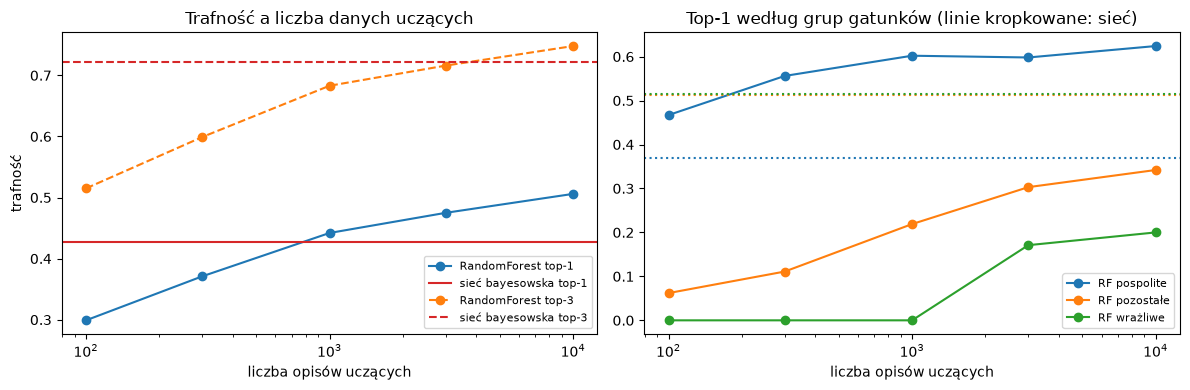

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rf_w = porownanie_rf[porownanie_rf["model"] == "RandomForest"]
for kol, styl in [("top-1", "-o"), ("top-3", "--o")]:
    ax[0].plot(rf_w["N uczących"], rf_w[kol], styl, label=f"RandomForest {kol}")
    ax[0].axhline(porownanie_rf.loc[0, kol], color="tab:red", ls=styl[:-1], label=f"sieć bayesowska {kol}")
ax[0].set_xscale("log")
ax[0].set_xlabel("liczba opisów uczących")
ax[0].set_ylabel("trafność")
ax[0].legend(fontsize=8)
ax[0].set_title("Trafność a liczba danych uczących")
for k in ["pospolite", "pozostałe", "wrażliwe"]:
    ax[1].plot(rf_w["N uczących"], rf_w[f"top-1 {k}"], "-o", label=f"RF {k}")
    ax[1].axhline(porownanie_rf.loc[0, f"top-1 {k}"], ls=":", color=ax[1].lines[-1].get_color())
ax[1].set_xscale("log")
ax[1].set_xlabel("liczba opisów uczących")
ax[1].set_title("Top-1 według grup gatunków (linie kropkowane: sieć)")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Sieć bayesowska, która nie widziała ani jednego przykładu, rozpoznaje 43% opisów, a w 72% przypadków właściwy gatunek jest wśród trzech pierwszych. RandomForest dorównuje jej przy około 1000 opisach uczących i wyprzedza ją przy 3000 (47,5%) i 10 000 (50,6%).

Wynik ogólny ukrywa jednak różnicę w tym, które gatunki każde podejście rozpoznaje. Las losowy przejmuje częstości z danych uczących, więc przy 10 000 opisów trafia 62% gatunków pospolitych, ale tylko 34% pozostałych i 20% wrażliwych. Sieć ma profil odwrotny (37%, 51% i 51%), bo każdy gatunek ma w niej opis cech z grafu niezależnie od tego, jak często się trafia. Dla systemu, który ma między innymi wychwytywać obserwacje gatunków rzadkich i chronionych, to istotna przewaga. Gatunków wrażliwych jest w zbiorze testowym tylko 35, więc wyniki w tej kolumnie mają błąd standardowy rzędu 8 punktów procentowych.

Jednym ze źródeł strat sieci przy gatunkach pospolitych jest dymorfizm płciowy, którego używa generator, a którego nie zna graf. Samica gila nie ma czerwieni, a w grafie gil jest czerwony, więc taki opis sieć przypisuje innemu gatunkowi. Las losowy może się tego nauczyć z przykładów. Wniosek dla nas nie brzmi "porzucić model jawny", tylko "dodać do ontologii barwy samicy". Las losowy wymaga za to tysięcy opisów z pewną etykietą gatunku, a takich danych na starcie systemu nie ma.

### 10.4. Jakość ontologii

Spójność ontologii sprawdziliśmy w sekcji 7 dwoma reasonerami. Żeby wiedzieć, czy te sprawdzenia w ogóle coś wykrywają, wstrzykujemy do kopii grafu trzy typowe błędy i sprawdzamy, który reasoner je zauważy:

1. Rodzinie przypisano rząd właściwością przeznaczoną dla gatunków (`nalezyDoRzedu` zamiast `rodzinaWRzedzie`). Dziedzina właściwości czyni rodzinę gatunkiem, a klasy `Gatunek` i `Rodzina` są rozłączne.
2. Obserwacja ma liczbę osobników 0, a zakresem właściwości jest `xsd:positiveInteger`.
3. Gil dostał drugi status pobytu. Właściwość jest funkcyjna, więc oba statusy musiałyby być tym samym obiektem, co wyklucza `owl:AllDifferent`.

In [35]:
def owlrl_bledy(graf):
    kopia = Graph() + graf
    owlrl.DeductiveClosure(owlrl.OWLRL_Semantics, axiomatic_triples=False, datatype_axioms=False).expand(kopia)
    return [str(o)[:110] for o in kopia.objects(None, ERROR)]


BLEDY = {
    "E1 rząd przypisany rodzinie złą właściwością": [(P.Corvidae, P.nalezyDoRzedu, P.Passeriformes)],
    "E2 liczba osobników 0": [(P.o01, P.liczbaOsobnikow, Literal(0, datatype=XSD.integer))],
    "E3 drugi status pobytu gila": [(P.gil, P.maStatusPobytu, P.Wedrowny)],
}
wiersze = []
for nazwa, trojki in BLEDY.items():
    zly = Graph() + g
    for tr in trojki:
        if tr[1] == P.liczbaOsobnikow:
            zly.remove((tr[0], tr[1], None))
        zly.add(tr)
    bl = owlrl_bledy(zly)
    h = hermit(zly)[1] if JAVA_OK else "brak Javy"
    wiersze.append({"błąd": nazwa, "owlrl": f"wykrył ({len(bl)})" if bl else "nie wykrył",
                    "HermiT": "wykrył" if h == "NIESPÓJNA" else "nie wykrył" if h == "spójna" else h,
                    "komunikat owlrl": bl[0] if bl else ""})
pd.DataFrame(wiersze)

,błąd,owlrl,HermiT,komunikat owlrl
0,E1 rząd przypisany rodzinie złą właściwością,wykrył (1),wykrył,Disjoint classes http://example.org/ptaki#Gatunek and http://example.org/ptaki#Rodzina have a common individua
1,E2 liczba osobników 0,nie wykrył,wykrył,
2,E3 drugi status pobytu gila,wykrył (1),wykrył,"'sameAs' and 'AllDifferent' cannot be used on the same subject-object pair: (http://example.org/ptaki#Osiadly,"


owlrl wykrył dwa z trzech błędów, HermiT wszystkie trzy. Błąd E2 wymaga sprawdzenia, czy literał należy do zakresu typu danych `xsd:positiveInteger`, czego owlrl w profilu RL nie robi. To główny powód, dla którego używamy dwóch reasonerów: owlrl daje domknięcie grafu, z którym pracuje reszta systemu, a HermiT pilnuje spójności.

Wykrycie błędów E1 i E3 zależy od aksjomatów, które świadomie dodaliśmy. E1 wychodzi tylko dlatego, że klasy `Gatunek` i `Rodzina` są rozłączne, a E3 dlatego, że statusy pobytu są oznaczone jako `owl:AllDifferent`. Bez tych dwóch aksjomatów oba reasonery uznałyby graf z błędami za poprawny.

Brak wartości nie jest dla reasonera błędem (świat otwarty), więc kompletność danych sprawdzamy osobno, zapytaniami SPARQL:

In [36]:
LINT = {
    "gatunki bez rodziny": "SELECT ?g WHERE { ?g a p:Gatunek FILTER NOT EXISTS { ?g p:nalezyDoRodziny ?r } }",
    "gatunki bez statusu pobytu": "SELECT ?g WHERE { ?g a p:Gatunek FILTER NOT EXISTS { ?g p:maStatusPobytu ?s } }",
    "gatunki bez barwy": "SELECT ?g WHERE { ?g a p:Gatunek FILTER NOT EXISTS { ?g p:maBarwe ?b } }",
    "rodziny bez gatunków": "SELECT ?r WHERE { ?r a p:Rodzina FILTER NOT EXISTS { ?g p:nalezyDoRodziny ?r } }",
    "rodziny bez rzędu": "SELECT ?r WHERE { ?r a p:Rodzina FILTER NOT EXISTS { ?r p:rodzinaWRzedzie ?o } }",
    "kwadraty bez siedliska": "SELECT ?k WHERE { ?k a p:Kwadrat FILTER NOT EXISTS { ?k p:maSiedlisko ?s } }",
    "obserwacje bez zachowania": "SELECT ?o WHERE { ?o a p:Obserwacja FILTER NOT EXISTS { ?o p:wykazanoZachowanie ?z } }",
    "gatunki bez powiązania z Wikidata": "SELECT ?g WHERE { ?g a p:Gatunek FILTER NOT EXISTS { ?g skos:exactMatch ?w } }",
    "zasoby słownikowe bez etykiety": """SELECT ?x WHERE { ?x a owl:NamedIndividual FILTER NOT EXISTS { ?x rdfs:label ?l }
                                         FILTER NOT EXISTS { ?x a p:Obserwacja } }""",
}
pd.DataFrame([{"kontrola": k, "liczba": len(sparql(gi, q)), "przykłady": ", ".join(sparql(gi, q).iloc[:, 0][:5])}
              for k, q in LINT.items()])

,kontrola,liczba,przykłady
0,gatunki bez rodziny,0,
1,gatunki bez statusu pobytu,0,
2,gatunki bez barwy,0,
3,rodziny bez gatunków,0,
4,rodziny bez rzędu,0,
5,kwadraty bez siedliska,0,
6,obserwacje bez zachowania,0,
7,gatunki bez powiązania z Wikidata,0,
8,zasoby słownikowe bez etykiety,0,


Kontrole kompletności przechodzą bez uwag. Pokazują jednak tylko, że każda wymagana właściwość ma jakąkolwiek wartość, a nie, że jest to wartość prawdziwa. Przykład dymówki z sekcji 8 (zbyt wąskie siedliska) przeszedłby wszystkie te kontrole.

W trakcie pracy znaleźliśmy i poprawiliśmy trzy błędy modelowania, które nie były błędami składni:

1. Pierwsza wersja zapisywała datę obserwacji jako `xsd:date`. owlrl to akceptował, ale HermiT odmawiał wnioskowania, bo `xsd:date` nie należy do typów danych OWL 2. Zmieniliśmy typ na `xsd:dateTime`.
2. Bez `owl:AllDifferent` dla statusów pobytu błąd E3 nie byłby błędem: reasoner uznałby po prostu, że "osiadły" i "wędrowny" to dwie nazwy tego samego statusu, i gil stałby się jednocześnie ptakiem obecnym zimą i niegniazdującym. To bezpośredni skutek braku założenia unikalnych nazw w OWL.
3. Powiązania z Wikidata zapisane początkowo przez `owl:sameAs` powodowały, że owlrl kopiował każdą trójkę o gatunku na adres Wikidata. Graf rósł bez żadnego pożytku dla pytań, więc przeszliśmy na `skos:exactMatch`.

Założenie świata otwartego ma w naszych pytaniach konkretne skutki. Klasa `GatunekObecnyZima` zawiera gatunki, o których wiadomo, że są obecne zimą. Gatunek bez zapisanego statusu nie trafi do niej, ale reasoner nie wywnioskuje też, że zimą go nie ma. Zapytanie SPARQL z `FILTER NOT EXISTS` tę różnicę zaciera. Widać to po dodaniu do kopii grafu jastrzębia bez statusu pobytu:

In [37]:
kopia = Graph() + gi
kopia.add((P.jastrzab, RDF.type, P.Gatunek))
kopia.add((P.jastrzab, RDFS.label, Literal("jastrząb", lang="pl")))
kopia.add((P.jastrzab, P.nalezyDoRodziny, P.Accipitridae))
owlrl.DeductiveClosure(owlrl.OWLRL_Semantics, axiomatic_triples=False, datatype_axioms=False).expand(kopia)
q_brak = "SELECT ?g WHERE { ?g a p:Gatunek FILTER NOT EXISTS { ?g a p:GatunekObecnyZima } } ORDER BY ?g"
print("gatunki nieobecne zimą według SPARQL (świat zamknięty):", len(sparql(kopia, q_brak)),
      "| w tym jastrząb:", "jastrzab" in set(sparql(kopia, q_brak)["g"]))
print("jastrząb jako ptak drapieżny (świat otwarty, wywnioskowane):", (P.jastrzab, RDF.type, P.PtakDrapiezny) in kopia)

gatunki nieobecne zimą według SPARQL (świat zamknięty): 17 | w tym jastrząb: True
jastrząb jako ptak drapieżny (świat otwarty, wywnioskowane): True


Jastrząb trafił na listę gatunków nieobecnych zimą, choć jest u nas osiadły, bo zapytanie z negacją potraktowało brak informacji jak informację. Ten sam brak nie przeszkodził reasonerowi zaliczyć go do ptaków drapieżnych, bo do tego wystarczy rodzina. Z tego powodu w regułach weryfikacji (R1, R2, R5) negacja dotyczy tylko gatunków, dla których kontrola kompletności potwierdziła obecność statusu pobytu. Gdyby kontrola "gatunki bez statusu pobytu" zwróciła coś niepustego, reguły dawałyby fałszywe alarmy.

## 11. Prywatność, przejrzystość, uczciwość

System przetwarza dwa rodzaje danych, które wymagają ostrożności. Pierwsze to dane o obserwatorach: pseudonim, historia zgłoszeń, a pośrednio także miejsca i godziny, w których dana osoba bywa. Szczegółowa historia obserwacji jednej osoby pozwala odgadnąć, gdzie mieszka i kiedy wychodzi z domu. Drugie to lokalizacje lęgów gatunków wrażliwych. Nie są to dane osobowe, ale ich ujawnienie może prowadzić do niepokojenia ptaków, a dla gatunków ze strefami ochrony przebywanie w strefie jest wprost ograniczone przepisami.

Proponowany podział dostępu do grafu:

| rola | widzi | nie widzi |
|---|---|---|
| użytkownik publiczny | gatunek, dzień, lokalizacja publiczna (kwadrat albo blok 5 km), pseudonim | godzina, dokładny kwadrat obserwacji ukrytych, historia obserwatora |
| zarejestrowany obserwator | to samo oraz własne zgłoszenia w pełnej postaci | dokładne miejsca cudzych obserwacji ukrytych |
| weryfikator (ekspert) | pełne dane zgłoszeń do weryfikacji, liczba zweryfikowanych zgłoszeń autora | tożsamość osoby za pseudonimem |
| administrator | powiązanie pseudonimu z osobą, przechowywane poza grafem | |

Poniżej sprawdzamy liczbami trzy rzeczy: czy ukrywanie miejsc lęgów rzeczywiście działa, jak łatwo odgadnąć miejsce zamieszkania obserwatora z opublikowanych danych i czy reguły weryfikacji traktują obserwatorów równo.

### 11.1. Czy ukryte miejsca lęgów da się odtworzyć

Budujemy graf publiczny, czyli to, co widziałby użytkownik bez uprawnień: gatunek, czas, pseudonim i lokalizację publiczną. Atakujący wie, że obserwator zwykle zgłasza kilka gatunków podczas jednego wyjścia w teren. Szuka więc innych obserwacji tej samej osoby z tego samego dnia, które mają dokładny kwadrat, i zostawia tylko kwadraty leżące w opublikowanym bloku 5 km.

In [38]:
def graf_publiczny(zrodlo):
    gp = Graph()
    for o in zrodlo.subjects(RDF.type, P.Obserwacja):
        if isinstance(o, URIRef):
            for pr in (P.dotyczyGatunku, P.zgloszonaPrzez, P.czasObserwacji, P.lokalizacjaPubliczna):
                for v in zrodlo.objects(o, pr):
                    gp.add((o, pr, v))
    return gp


Q_ATAK = """
SELECT ?ukryta ?gatunek ?blok ?kandydat WHERE {
  ?ukryta p:lokalizacjaPubliczna ?blok ; p:zgloszonaPrzez ?a ; p:czasObserwacji ?t1 ; p:dotyczyGatunku ?gatunek .
  FILTER(STRSTARTS(STR(?blok), "blok_"))
  OPTIONAL {
    ?inna p:zgloszonaPrzez ?a ; p:czasObserwacji ?t2 ; p:lokalizacjaPubliczna ?kandydat .
    FILTER(?inna != ?ukryta && STRSTARTS(STR(?kandydat), "kw_") && SUBSTR(STR(?t1), 1, 10) = SUBSTR(STR(?t2), 1, 10))
  }
}"""


def atak(graf):
    df = sparql(graf_publiczny(graf), Q_ATAK)
    wynik = []
    for (o, gat, bl), grp in df.groupby(["ukryta", "gatunek", "blok"]):
        kand = sorted({k for k in grp["kandydat"].dropna() if blok(k) == bl})
        wynik.append({"obserwacja": o, "gatunek": gat, "blok": bl, "kandydaci": ", ".join(kand) or "brak",
                      "prawdziwy kwadrat": obserwacje.set_index("id").loc[o, "kwadrat"],
                      "odtworzony": len(kand) == 1 and kand[0] == obserwacje.set_index("id").loc[o, "kwadrat"]})
    return pd.DataFrame(wynik)


atak_przed = atak(gi)
atak_przed

,obserwacja,gatunek,blok,kandydaci,prawdziwy kwadrat,odtworzony
0,o13,gluszec,blok_3_2,kw_15_14,kw_15_14,True
1,o16,orlik_krzykliwy,blok_2_2,"kw_12_10, kw_13_10",kw_13_10,False
2,o23,bielik,blok_3_2,kw_16_14,kw_16_14,True


Atak się udaje. Tokującego głuszca (o13) i gniazdo bielika (o23) da się umieścić w konkretnym kwadracie 1 km, bo ten sam obserwator tego samego dnia opublikował inne obserwacje z dokładnym kwadratem. Dla gniazda orlika (o16) zostają dwa kwadraty, czyli ochrona jest słabsza, niż sugeruje blok 5 km.

Poprawka to dodatkowa reguła R13: jeśli jedna obserwacja z danego wyjścia w teren jest ukryta, ukrywamy wszystkie obserwacje tej samej osoby z tego dnia. Reguła jest rekurencyjna, ale bez negacji, więc silnik umieszcza ją w tej samej warstwie co R12.

In [39]:
REGULY_POPRAWIONE = REGULY + [
    R("R13", ("ukryjMiejsce", "?o2"), [("ukryjMiejsce", "?o"), ("autor", "?o", "?a"), ("dzien", "?o", "?d"),
                                       ("autor", "?o2", "?a"), ("dzien", "?o2", "?d")], [],
      "ukrywamy też inne obserwacje tej samej osoby z tego samego dnia"),
]
silnik_pop = SilnikRegul(REGULY_POPRAWIONE).wykonaj(fakty_z_grafu(gi))
gi_pop = Graph() + gi
zapisz_wyniki_regul(silnik_pop, [gi_pop])
atak_po = atak(gi_pop)
ukryte_po = {o for (o,) in silnik_pop.zapytaj("ukryjMiejsce")}
print(f"obserwacji z ukrytym miejscem: przed {len(ukryte)}, po poprawce {len(ukryte_po)}")
print(f"odtworzone kwadraty lęgów: przed {int(atak_przed['odtworzony'].sum())} z {len(atak_przed)}, "
      f"po poprawce {int(atak_po[atak_po['obserwacja'].isin(ukryte)]['odtworzony'].sum())} z {len(ukryte)}")
print("\n".join(silnik_pop.objasnij(("ukryjMiejsce", "o24"))))
atak_po[atak_po["obserwacja"].isin(ukryte)]

obserwacji z ukrytym miejscem: przed 3, po poprawce 10
odtworzone kwadraty lęgów: przed 2 z 3, po poprawce 0 z 3
ukryjMiejsce(o24)   [reguła R13: ukrywamy też inne obserwacje tej samej osoby z tego samego dnia]
    ukryjMiejsce(o23)   [reguła R12: lęg gatunku wrażliwego publikujemy tylko z dokładnością do bloku 5 km]
        obsLegowa(o23)   [fakt, źródło: owlrl]
        gatunekObs(o23, bielik)   [fakt, źródło: graf]
        wrazliwy(bielik)   [fakt, źródło: graf]
    autor(o23, obs02)   [fakt, źródło: graf]
    dzien(o23, 2026-05-30)   [fakt, źródło: python]
    autor(o24, obs02)   [fakt, źródło: graf]
    dzien(o24, 2026-05-30)   [fakt, źródło: python]


,obserwacja,gatunek,blok,kandydaci,prawdziwy kwadrat,odtworzony
0,o13,gluszec,blok_3_2,brak,kw_15_14,False
3,o16,orlik_krzykliwy,blok_2_2,brak,kw_13_10,False
8,o23,bielik,blok_3_2,brak,kw_16_14,False


Po poprawce żaden z trzech kwadratów lęgowych nie daje się odtworzyć tym atakiem. Kosztem jest mniejsza dokładność danych publicznych: z dokładnym kwadratem znika siedem obserwacji zwykłych gatunków, które przypadkiem zgłoszono tego samego dnia. Atak bardziej wyrafinowany, który łączy dane z kilku dni albo od kilku obserwatorów, nadal jest możliwy, więc w praktyce do bloków 5 km dodalibyśmy opóźnienie publikacji obserwacji lęgowych do końca sezonu lęgowego.

### 11.2. Czy z opublikowanych danych da się odgadnąć miejsce zamieszkania obserwatora

Na 44 obserwacjach nie da się tego zmierzyć, więc generujemy 500 syntetycznych obserwatorów na obszarze 20 na 20 km. Każdy ma miejsce zamieszkania w losowym kwadracie, a jego obserwacje w 60% pochodzą z okolicy domu (dom i 8 sąsiednich kwadratów), w pozostałych 40% z losowego miejsca. Atakujący zgaduje, że obserwator mieszka w kwadracie, z którego ma najwięcej zgłoszeń (przy publikacji dokładnych kwadratów) albo w środku bloku, z którego ma najwięcej zgłoszeń (przy publikacji bloków 5 km). Sukces oznacza, że wskazany kwadrat jest domem obserwatora albo z nim sąsiaduje, czyli trafienie z dokładnością do około 1,5 km.

In [40]:
rng = np.random.default_rng(RANDOM_STATE)
BOK = 20
wiersze = []
for i in range(500):
    dom = rng.integers(0, BOK, size=2)
    n = int(rng.integers(5, 81))
    blisko = rng.random(n) < 0.6
    xy = np.where(blisko[:, None], np.clip(dom + rng.integers(-1, 2, size=(n, 2)), 0, BOK - 1),
                  rng.integers(0, BOK, size=(n, 2)))
    kw = Counter(map(tuple, xy)).most_common(1)[0][0]
    bl = Counter(map(tuple, xy // 5)).most_common(1)[0][0]
    zgad_kw = np.array(kw)
    zgad_bl = np.array(bl) * 5 + 2
    losowy = rng.integers(0, BOK, size=2)
    wiersze.append({"liczba zgłoszeń": n,
                    "kwadraty 1 km": np.abs(zgad_kw - dom).max() <= 1,
                    "bloki 5 km": np.abs(zgad_bl - dom).max() <= 1,
                    "zgadywanie losowe": np.abs(losowy - dom).max() <= 1})
dom_atak = pd.DataFrame(wiersze)
dom_atak["przedział zgłoszeń"] = pd.cut(dom_atak["liczba zgłoszeń"], [4, 10, 20, 40, 80])
display(dom_atak[["kwadraty 1 km", "bloki 5 km", "zgadywanie losowe"]].mean().to_frame("skuteczność ataku").T.round(3))
dom_atak.groupby("przedział zgłoszeń", observed=True)[["kwadraty 1 km", "bloki 5 km"]].mean().round(3)

,kwadraty 1 km,bloki 5 km,zgadywanie losowe
skuteczność ataku,0.982,0.316,0.014


,kwadraty 1 km,bloki 5 km
przedział zgłoszeń,,
"(4, 10]",0.844,0.438
"(10, 20]",0.935,0.242
"(20, 40]",1.000,0.294
"(40, 80]",1.000,0.328


Publikacja dokładnych kwadratów praktycznie zdradza miejsce zamieszkania. Atak trafia u 98% obserwatorów, a u wszystkich, którzy mają ponad 20 zgłoszeń. Bloki 5 km obniżają skuteczność do 32%, ale to wciąż ponad dwadzieścia razy więcej niż zgadywanie losowe (1,4%). Przy blokach skuteczność prawie nie zależy od liczby zgłoszeń, bo atakujący niemal zawsze wskazuje właściwy blok, a ogranicza go samo zaokrąglenie. Środek bloku sąsiaduje z 9 z jego 25 kwadratów, więc ta metoda nie przekroczy 36%.

Obecny system publikuje dokładny kwadrat każdej obserwacji poza lęgami gatunków wrażliwych, czyli jest w pierwszym wierszu tej tabeli. Proponujemy, żeby profil publiczny obserwatora pokazywał tylko listę gatunków i daty, a mapy obserwacji powstawały z danych wielu osób łącznie, bez przypisania punktów do pseudonimu. Model ruchu obserwatora jest bardzo prosty. Prawdziwi obserwatorzy mają zwykle kilka stałych miejsc (dom, działka, praca), co atak utrudnia, ale ci, którzy chodzą głównie wokół domu, są narażeni bardziej, niż zakłada model.

### 11.3. Czy reguły weryfikacji traktują obserwatorów równo

Reguła R11 zwalnia z weryfikacji obserwatorów zaufanych, czyli tych, którzy mają co najmniej 50 wcześniej zweryfikowanych zgłoszeń. To rozsądne ze względu na obciążenie ekspertów, ale oznacza, że ta sama nietypowa obserwacja jest traktowana różnie w zależności od tego, kto ją zgłosił. Na naszych danych wygląda to tak:

In [41]:
wr = wyniki_regul.assign(grupa=np.where(wyniki_regul["zaufany"], "zaufani", "bez historii"),
                         nietypowa_b=wyniki_regul["nietypowa"] != "")
wr.groupby("grupa").agg(obserwacji=("id", "size"), nietypowych=("nietypowa_b", "sum"),
                        do_weryfikacji=("do_weryfikacji", "sum"))

,obserwacji,nietypowych,do_weryfikacji
grupa,,,
bez historii,21,9,8
zaufani,23,5,0


Wszystkie obserwacje skierowane do eksperta pochodzą od osób bez historii, choć nietypowe obserwacje zgłosili też obserwatorzy zaufani (zimujący kopciuszek, bieliki, orlik, turkawka). Pytanie brzmi, czy to różnicowanie jest uzasadnione, czyli czy przekłada się na lepsze wychwytywanie błędów, i kto ponosi jego koszt.

Sprawdzamy to symulacją. Przyjmujemy, że osoby bez historii mylą się w 12% zgłoszeń, a zaufane w 3%. Błędna obserwacja wygląda na nietypową dla reguł z prawdopodobieństwem 0,7, a poprawna z prawdopodobieństwem 0,08 (rzadkie, ale prawdziwe zjawiska). Poprawną obserwację ktoś niezależnie potwierdza z prawdopodobieństwem 0,2, a błędną 0,02. Porównujemy dwie polityki: A, czyli obecne reguły ze zwolnieniem zaufanych, i B, w której nietypowe niepotwierdzone obserwacje trafiają do eksperta niezależnie od autora. Wartości prawdopodobieństw są założeniami ilustracyjnymi, a nie pomiarem.

In [42]:
rng = np.random.default_rng(RANDOM_STATE + 1)
N_SYM = 20000
grupa_s = np.where(rng.random(N_SYM) < 0.5, "bez historii", "zaufani")
blad = rng.random(N_SYM) < np.where(grupa_s == "bez historii", 0.12, 0.03)
nietypowa_s = rng.random(N_SYM) < np.where(blad, 0.7, 0.08)
potw = rng.random(N_SYM) < np.where(blad, 0.02, 0.2)
polityki = {"A: zaufani zwolnieni": nietypowa_s & ~potw & (grupa_s == "bez historii"),
            "B: bez zwolnień": nietypowa_s & ~potw}
wiersze = []
for nazwa, flaga in polityki.items():
    for gr in ["bez historii", "zaufani"]:
        m = grupa_s == gr
        wiersze.append({"polityka": nazwa, "grupa": gr,
                        "poprawne zgłoszenia wstrzymane (FPR)": flaga[m & ~blad].mean(),
                        "błędy wychwycone": flaga[m & blad].mean(),
                        "błędy opublikowane na 1000 zgłoszeń": 1000 * (m & blad & ~flaga).sum() / m.sum()})
    wiersze.append({"polityka": nazwa, "grupa": "razem", "poprawne zgłoszenia wstrzymane (FPR)": flaga[~blad].mean(),
                    "błędy wychwycone": flaga[blad].mean(),
                    "błędy opublikowane na 1000 zgłoszeń": 1000 * (blad & ~flaga).sum() / N_SYM,
                    "obciążenie eksperta na 1000 zgłoszeń": 1000 * flaga.mean()})
uczciwosc = pd.DataFrame(wiersze).round(3)
uczciwosc

,polityka,grupa,poprawne zgłoszenia wstrzymane (FPR),błędy wychwycone,błędy opublikowane na 1000 zgłoszeń,obciążenie eksperta na 1000 zgłoszeń
0,A: zaufani zwolnieni,bez historii,0.064,0.690,36.519,NaN
1,A: zaufani zwolnieni,zaufani,0.000,0.000,31.213,NaN
2,A: zaufani zwolnieni,razem,0.030,0.544,33.850,68.45
3,B: bez zwolnień,bez historii,0.064,0.690,36.519,NaN
4,B: bez zwolnień,zaufani,0.063,0.678,10.040,NaN
5,B: bez zwolnień,razem,0.064,0.687,23.200,109.95


Polityka A obciąża wyłącznie osoby bez historii: na eksperta czeka 6,4% ich poprawnych zgłoszeń, a u zaufanych żadne. Zaufani mylą się w symulacji czterokrotnie rzadziej, ale ich błędy w ogóle nie są sprawdzane. W efekcie w opublikowanych danych na każde 1000 zgłoszeń przypada 31 ich błędów, prawie tyle samo co błędów osób bez historii (37), które przechodzą przez weryfikację. Polityka B wyrównuje odsetek wstrzymanych poprawnych zgłoszeń (6,4% i 6,3%) i zmniejsza liczbę opublikowanych błędów z 34 do 23 na 1000 zgłoszeń, ale zwiększa liczbę zgłoszeń kierowanych do eksperta z 68 do 110 na 1000, czyli o 60%.

Wybór zależy od tego, ile czasu mają weryfikatorzy, więc nie rozstrzygamy go w kodzie. Proponujemy wariant pośredni: nietypowe obserwacje zaufanych osób publikujemy od razu, ale ekspert dostaje wyrywkowo co piątą z nich, a obserwacje gatunków wrażliwych zawsze. Próg 50 zweryfikowanych zgłoszeń jest arbitralny i powinien wynikać z danych o trafności obserwatorów, których w projekcie nie mamy. Trzeba też uważać na sprzężenie zwrotne: osoby bez historii częściej czekają na weryfikację, więc wolniej budują historię, która by je z niej zwolniła. Dlatego do progu powinny się liczyć także nietypowe zgłoszenia, które ekspert zatwierdził.

## 12. Wnioski, ograniczenia, dalsze kroki

Najwięcej dało połączenie trzech formalizmów, z których każdy robi to, czego pozostałe nie potrafią. Bez wnioskowania odpowiedź miały 3 z 12 pytań obsługiwanych zapytaniami SPARQL. Po wnioskowaniu owlrl odpowiadają wszystkie, a CQ9 i CQ10 po dopisaniu wyników reguł. Wszystkie 14 obsługiwanych pytań kompetencyjnych przechodzi testy z ręcznie wyznaczonymi oczekiwaniami. owlrl i HermiT przypisały instancje klasom definiowanym identycznie, więc profil OWL 2 RL wystarcza do pracy z danymi, ale tylko HermiT wykrył błąd zakresu typu danych. Reguły z negacją wskazały 14 nietypowych obserwacji, z których 8 trafia do eksperta. Jedną z nich (dymówka nad osiedlem) uważamy za fałszywy alarm wynikający ze zbyt wąskiego opisu siedlisk, nie z reguł. Sieć bayesowska, zbudowana w całości z faktów grafu, rozpoznała poprawnie 8 z 8 przypadków wzorcowych, Na opisach syntetycznych las losowy dorównuje jej dopiero przy około 1000 przykładach uczących, a gatunki rzadkie sieć rozpoznaje lepiej niż las losowy przy każdej liczbie przykładów.

Największe ograniczenia wynikają z danych, a nie z formalizmów. Obserwacje są syntetyczne, więc liczby z sekcji 10.3 i 11 mówią o zachowaniu systemu przy przyjętych założeniach, a nie o skuteczności w terenie. Każdy gatunek ma jeden status pobytu dla całej Polski i jeden zestaw barw, co daje fałszywe alarmy (zimujący kopciuszek) i błędy rozpoznania (samice). Dudka od dymówki i łyskę od gągoła sieć odróżnia tylko liczbą obserwacji, bo w grafie nie ma żadnej cechy, która by je rozdzielała. Parametry sieci przyjęliśmy bez pomiaru i choć analiza wrażliwości nie zmieniła żadnego pierwszego miejsca, zmieniała pewność nawet o 30 punktów procentowych. Aplikacja działa na szablonach i rozumie tylko pytania podobne do tych, które przewidzieliśmy.

Analiza prywatności znalazła realną lukę: ukrycie miejsca lęgu w bloku 5 km nie chroniło głuszca i bielika, bo obserwator tego samego dnia publikował inne obserwacje z dokładnym miejscem. Reguła R13 tę lukę zamyka. Większym problemem okazało się miejsce zamieszkania obserwatorów, które przy obecnej polityce publikacji da się odgadnąć prawie zawsze.

Kolejne kroki uszeregowaliśmy według tego, ile poprawiają przy jakim koszcie. Najtańsze są zmiany w publikacji danych z sekcji 11, które nie wymagają zmian w modelu. Dalej dodalibyśmy do ontologii barwy samicy i cechy kształtu (czub, kształt dzioba), status pobytu zależny od miesiąca oraz siedliska budynków, co usunęłoby znane fałszywe alarmy. Kontrole kompletności przenieślibyśmy do kształtów SHACL, żeby sprawdzały dane przy każdym zgłoszeniu. Gdy w systemie zbierze się kilka tysięcy zweryfikowanych zgłoszeń, parametry sieci można będzie oszacować z danych zamiast je zakładać, zachowując strukturę z grafu.

### Notatka dla odbiorcy nietechnicznego

Zbudowaliśmy prototyp systemu dla regionalnej bazy obserwacji ptaków. System ma zapisaną wiedzę o 58 gatunkach, odpowiada na proste pytania zadane po polsku, podpowiada, jaki ptak to mógł być, na podstawie krótkiego opisu, i sprawdza zgłoszenia, zanim zostaną opublikowane.

Przy każdej odpowiedzi system pokazuje, skąd ją wziął, a przy każdym zatrzymanym zgłoszeniu podaje powód, np. "bocian biały w lutym, gatunek zimą w Polsce nieobecny, nikt inny go nie potwierdził". Weryfikator nie musi więc ufać systemowi na słowo. Na testowym zbiorze 44 zgłoszeń system skierował do sprawdzenia 8.

Dwie sprawy wymagają decyzji, zanim system trafi do użytkowników. Pierwsza to publikacja miejsc. Pokazaliśmy, że z obecnie publikowanych danych da się odgadnąć, gdzie mieszka niemal każdy aktywny obserwator, a przy gniazdach gatunków chronionych samo zaokrąglenie lokalizacji nie wystarcza. Zaproponowaliśmy poprawki. Druga to sprawiedliwe traktowanie obserwatorów. Doświadczeni obserwatorzy są zwolnieni ze sprawdzania, co odciąża ekspertów, ale ich pomyłki trafiają do bazy bez kontroli, a nowi czekają na weryfikację częściej. Rozwiązanie zależy od tego, ile czasu mają weryfikatorzy, i to jest decyzja dla prowadzących bazę, a nie dla nas.

Wyniki opierają się na danych przygotowanych przez nas do testów, a nie na prawdziwych zgłoszeniach. Przed wdrożeniem trzeba je sprawdzić na rzeczywistych danych.

## 13. Podział pracy w zespole

| osoba | odpowiadała za |
|---|---|
| Osoba1 | ontologia i jej uzasadnienie (sekcja 4), reasonery i analiza jakości (sekcje 7 i 10.4), plik Turtle |
| Osoba2 | dane gatunków i obserwacji, łączenie z Wikidata i ocena powiązań (sekcja 5), zapytania SPARQL (sekcja 6) |
| Osoba3 | silnik reguł, reguły weryfikacji i objaśnienia (sekcja 8.1 i 8.2), analiza prywatności i uczciwości (sekcja 11) |
| Osoba4 | sieć bayesowska (sekcja 8.3), aplikacja pytań i odpowiedzi (sekcja 9), porównanie z RandomForest (sekcja 10.3) |

Pytania kompetencyjne, testy (sekcja 10.1), wnioski i notatkę dla odbiorcy nietechnicznego przygotowaliśmy wspólnie. Każda sekcja była przeglądana przez osobę, która jej nie pisała.

In [43]:
g.serialize("ptaki_ontologia.ttl", format="turtle")
print("zapisano ptaki_ontologia.ttl:", len(g), "trójek (TBox, dane, powiązania z Wikidata, wyniki reguł)")
print(f"czas wykonania całego notebooka: {time.time() - T_START:.0f} s")

zapisano ptaki_ontologia.ttl: 2174 trójek (TBox, dane, powiązania z Wikidata, wyniki reguł)
czas wykonania całego notebooka: 86 s
